# Customer Decision Analytics: Pricing, Causal Impact, Positioning and Marketing Measurement

**Case study:** a consumer app is launching a new subscription line-up and needs one plan covering which features to bundle, what to charge, whether the offer works, how to position the line-up and where to spend marketing dollars.

## Executive Summary

**Recommendation: launch three tiers, led by a refined bundle, Premium Lite at \$12, and confirm demand with a live test before full rollout.**

Four candidate bundles were tested: Budget \$5, Mid \$8, ValuePlus \$12 and Premium \$15. Premium Lite is Premium without offline download, at \$12.

| Decision | Recommendation | Key evidence | Section |
|---|---|---|---|
| **Bundle** | Mid \$8, Premium Lite \$12, Premium \$15. Drop Budget and ValuePlus. Premium stays pending the live test. | \$11.49 expected revenue per subscriber per month vs. \$10.45 for the four candidates. Gain: +\$1.03 [\$0.88, \$1.18] with one model for all respondents, and about +\$0.56 at the low end of the robustness checks. | 1, 3 |
| **Price** | Hold Mid at \$8 for entry-tier reach, a judgment to test. Test Premium below \$15. | In the launch line-up, Mid's share falls from 21.1% to 10.2% at \$9. Offline download averages \$0.85, and \$1.65 among PowerUsers, the highest segment, against Premium's \$3 step. | 3 |
| **Offer** | Refine targeting, do not scale yet. | Estimated +2.02 percentage points [1.46, 2.64] on the upgrade rate and +\$0.238 [\$0.153, \$0.321] revenue per user per month if the recorded user attributes explain who was targeted; not randomized. The raw gap is +3.68 percentage points. | 2 |
| **Positioning** | Lead Premium Lite on 1000 GB, Priority support and 6 seats. Use no ads as a line-wide message. | ValuePlus and Premium are the closest substitutes. Premium Lite sits between Mid and Premium on price, nearest Premium on features. | 3 |
| **Budget** | Do not reallocate between channels yet. The launch budget level stays open until subscriber lifetime value is known. | Channels add no significant forecast accuracy beyond trend and seasonality on any outcome. | 4 |

**Main risks:** the revenue gain rests on a simulation with no "buy nothing" option, and it moves demand away from Mid and Premium. The offer effect holds only if the recorded covariates explain targeting. Section 5 sets out the tests that would confirm or overturn the plan.

**How to read this notebook:** square brackets are 95% confidence intervals. Gaps are computed before rounding, so they can differ by \$0.01 from the rounded figures. Table values cited in the text are red in Jupyter and VS Code; some web previews drop the color. Each section opens with its approach and key concepts, and closes with a summary.

| Section | Question | Methods |
|---|---|---|
| 1. Feature and Price Preferences | What do customers value, and what will they pay? | Conjoint, conditional logit, willingness to pay, segment models |
| 2. Offer Impact | Does the offer cause more upgrades and revenue? | Propensity scores, IPW, AIPW, balance and sensitivity checks |
| 3. Positioning and Whitespace | Which bundles compete, and where is the gap? | Multidimensional scaling (MDS), Gower distance, candidate search, line-up simulation |
| 4. Marketing Budget and Measurement | Which channels work, and how can we know? | Ridge MMM, adstock, block bootstrap, placebo tests, experiment sizing |
| 5. Launch Plan, Risks and Next Steps | What should the business do? | Integrated recommendation and test plan |
| Appendix: Survey Value Drivers | How do survey items group? | Factor analysis |

## Setup and Data

In [1]:
# -----------------------------
# Imports and configuration
# -----------------------------
import re
from itertools import combinations
from pathlib import Path

import gower
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from matplotlib.ticker import PercentFormatter
from scipy import stats
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import FactorAnalysis
from sklearn.linear_model import LogisticRegression, Ridge, RidgeCV
from sklearn.manifold import MDS
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, MinMaxScaler, OneHotEncoder, StandardScaler
from statsmodels.discrete.conditional_models import ConditionalLogit
from statsmodels.stats.power import TTestIndPower

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 140)

# Data files sit next to this notebook
CHOICE_PATH = Path("choice_conjoint_tasks.csv")
BUNDLES_PATH = Path("candidate_bundles.csv")
ADOPT_PATH = Path("observational_offer_adoption.csv")
SURVEY_PATH = Path("survey_value_drivers.csv")
MMM_PATH = Path("marketing_weekly_channels.csv")
SIM_PATH = Path("bundle_similarity_matrix.csv")

In [2]:
# -----------------------------
# Chart style (shared by all sections)
# -----------------------------
COLORS = {
    'surface': '#fcfcfb',
    'text': '#0b0b0b',
    'text_2': '#52514e',
    'muted': '#8a8985',
    'grid': '#e6e5e1',
    'blue': '#2a78d6',  # primary series / positive utility
    'orange': '#eb6834',  # secondary series / cost
    'neutral': '#c9c8c2',  # de-emphasized marks
}

plt.rcParams.update(
    {
        'figure.facecolor': COLORS['surface'],
        'axes.facecolor': COLORS['surface'],
        'savefig.facecolor': COLORS['surface'],
        'figure.dpi': 110,
        'font.family': ['Helvetica Neue', 'Helvetica', 'Arial', 'DejaVu Sans'],
        'font.size': 10,
        'text.color': COLORS['text'],
        'axes.labelcolor': COLORS['text_2'],
        'axes.labelsize': 10,
        'axes.titlesize': 12,
        'axes.titleweight': 'bold',
        'axes.titlelocation': 'left',
        'axes.titlepad': 24,
        'axes.edgecolor': COLORS['grid'],
        'axes.linewidth': 1,
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.grid': True,
        'axes.axisbelow': True,
        'grid.color': COLORS['grid'],
        'grid.linewidth': 1,
        'xtick.color': COLORS['text_2'],
        'ytick.color': COLORS['text_2'],
        'xtick.major.size': 0,
        'ytick.major.size': 0,
        'xtick.major.pad': 6,
        'ytick.major.pad': 6,
        'lines.linewidth': 2,
        'lines.solid_capstyle': 'round',
        'legend.frameon': False,
        'legend.fontsize': 9,
        'legend.labelcolor': COLORS['text_2'],
    }
)


def subtitle(ax, text):
    """Grey one-line subtitle under a left-aligned axes title."""
    ax.text(0, 1.025, text, transform=ax.transAxes, ha='left', va='bottom', fontsize=9, color=COLORS['text_2'])


HIGHLIGHT = 'color: #c62828; font-weight: bold'


def mark(styler, cells=(), title=None):
    """Title a table and show cited cells in red. cells: [(rows, columns)]; None selects all rows or columns."""

    def css(df):
        """Style matrix for pandas: the selected cells get HIGHLIGHT, the rest stay plain."""
        out = pd.DataFrame('', index=df.index, columns=df.columns)
        for rows, cols in cells:
            out.loc[slice(None) if rows is None else rows, slice(None) if cols is None else cols] = HIGHLIGHT
        return out

    styler = styler.apply(css, axis=None)
    if title:
        styler = styler.set_caption(title).set_table_styles(
            [
                {
                    'selector': 'caption',
                    'props': 'caption-side: top; text-align: left; font-weight: bold; font-size: 1.05em; padding-bottom: 6px;',
                }
            ],
            overwrite=False,
        )
    return styler

In [3]:
# -----------------------------
# Helpers shared across sections
# -----------------------------
def boot_apply(fn, draws):
    """Apply a function of the part-worths to every bootstrap draw."""
    return pd.DataFrame([fn(row) for _, row in draws.iterrows()])


def boot_summary(est, draws, null=0.0):
    """Point estimate, 95% percentile CI, bootstrap SE and two-sided p-value (H0: value = null)."""
    est = pd.Series(est)
    draws = pd.DataFrame(draws)[est.index]
    se = draws.std(ddof=1)
    return pd.DataFrame(
        {
            'estimate': est,
            'ci_95_low': draws.quantile(0.025),
            'ci_95_high': draws.quantile(0.975),
            'boot_se': se,
            'p_value': 2 * stats.norm.sf(((est - null) / se).abs()),
        }
    )


def fmt_p(p):
    """Format a p-value, showing very small values as <0.001."""
    return '<0.001' if p < 0.001 else f'{p:.3f}'


def show_ci(df, kind='num', marks=(), title=None):
    """Display a boot_summary table formatted as 'num', 'usd' or 'pct'; `marks` cells are shown in red."""
    f = {'num': '{:.3f}', 'usd': '${:.2f}', 'pct': '{:.1%}'}[kind]
    if kind == 'usd':
        f = lambda v: f'-${-v:.2f}' if v < 0 else f'${v:.2f}'
    cols = {c: f for c in ['estimate', 'ci_95_low', 'ci_95_high', 'model_se', 'boot_se'] if c in df}
    display(mark(df.style.format({**cols, 'p_value': fmt_p}), marks, title=title))


def ci_str(est, lo, hi, kind):
    """Format an estimate and its 95% CI as text, in percent ('pct') or USD."""
    if kind == 'pct':
        return f'{est:.0%} [{lo:.0%}, {hi:.0%}]'
    return f'${est:.2f} [{lo:.2f}, {hi:.2f}]'


def logit_shares(u):
    """Logit share of each alternative from its utility: exp(u_i) / sum_j exp(u_j)."""
    return np.exp(u) / np.exp(u).sum()


def ipw_weights(treated, propensity):
    """Inverse probability weights: 1 / P(treated) for treated users, 1 / P(control) for the rest."""
    return np.where(treated == 1, 1 / propensity, 1 / (1 - propensity))


def orient_map(coords):
    """Fix the arbitrary signs of MDS axes: Premium to the right of Budget, and Mid in the upper half."""
    if coords.loc['Premium', 'dim_1'] < coords.loc['Budget', 'dim_1']:
        coords['dim_1'] *= -1
    if coords.loc['Mid', 'dim_2'] < 0:
        coords['dim_2'] *= -1
    return coords


def forest(ax, estimate, low, high, ypos):
    """Forest plot: point estimates with CI bars and a reference line at zero."""
    ax.hlines(ypos, low, high, color=COLORS['blue'], lw=3)
    ax.scatter(estimate, ypos, color=COLORS['blue'], s=70, zorder=3, edgecolor=COLORS['surface'], lw=1.5)
    ax.axvline(0, color=COLORS['muted'], lw=1)


def show_facts(facts, title):
    """Display labeled single values as a titled table, all shown in red because the text cites them."""
    display(mark(pd.Series(facts, name='value').to_frame().style, [(None, None)], title=title))

In [4]:
# Fail early with a clear message if a data file is missing
required = [CHOICE_PATH, BUNDLES_PATH, ADOPT_PATH, SURVEY_PATH, MMM_PATH, SIM_PATH]
missing = [p.name for p in required if not p.exists()]
if missing:
    raise FileNotFoundError(f"Place these files next to the notebook and rerun: {', '.join(missing)}")
print(f"All {len(required)} data files found.")

All 6 data files found.


In [5]:
# Load the five datasets and the bundle similarity matrix
df_choice = pd.read_csv(CHOICE_PATH)
df_bundles = pd.read_csv(BUNDLES_PATH)
df_adopt = pd.read_csv(ADOPT_PATH, keep_default_na=False, na_values=[''])  # 'NA' is a region code, not a missing value
df_mmm = pd.read_csv(MMM_PATH, parse_dates=["week_start"])

df_sim = pd.read_csv(SIM_PATH, index_col=0)
df_survey = pd.read_csv(SURVEY_PATH)

# Preview each dataset
display(mark(df_choice.head().style, title='Conjoint choice tasks: first five rows'))
display(mark(df_bundles.style, title='Candidate bundles'))
display(mark(df_adopt.head().style.format(precision=2), title='Offer and upgrade data by user: first five rows'))
display(
    mark(
        df_mmm.head()
        .style.format(precision=2, subset=df_mmm.select_dtypes('float').columns)
        .format('{:%Y-%m-%d}', subset=['week_start']),
        title='Weekly marketing spend and outcomes: first five rows',
    )
)

,respondent_id,segment_true,task_id,alternative,price_usd,storage_gb,support,ads,family_seats,offline_download,chosen
0,1,PowerUser,1,A,8,50,Standard,Ads,1,Yes,0
1,1,PowerUser,1,B,12,200,Standard,NoAds,4,No,0
2,1,PowerUser,1,C,5,1000,Standard,Ads,4,No,1
3,1,PowerUser,2,A,5,200,Priority,Ads,1,No,0
4,1,PowerUser,2,B,5,200,Standard,NoAds,4,Yes,1


,bundle,price_usd,storage_gb,support,ads,family_seats,offline_download
0,Budget,5,50,Standard,Ads,1,No
1,Mid,8,200,Standard,NoAds,4,Yes
2,Premium,15,1000,Priority,NoAds,6,Yes
3,ValuePlus,12,200,Priority,NoAds,4,Yes


,user_id,age,tenure_days,region,device,prior_spend_12m,sessions_30d,offer_received,upgraded_to_new_tier,new_tier_monthly_revenue
0,1,54,675,NA,iOS,8.99,6,1,0,0.00
1,2,59,540,NA,Android,1.64,5,0,0,0.00
2,3,50,821,APAC,Web,5.96,8,1,1,5.38
3,4,24,548,NA,Web,1.36,11,0,0,0.00
4,5,18,47,NA,Web,5.41,11,1,0,0.00


,week_start,spend_search,spend_social,spend_video,spend_affiliate,spend_email,installs,new_subscriptions,weekly_revenue_usd
0,2022-01-03,11157.72,3166.13,9609.98,892.09,1235.35,25597,899,10715.40
1,2022-01-10,3491.33,4454.75,3802.93,3257.74,1552.97,22440,865,4870.41
2,2022-01-17,5802.55,5511.06,2458.08,852.15,869.39,20345,791,16070.33
3,2022-01-24,4847.06,5245.37,1438.74,1707.09,970.90,23833,890,-3394.49
4,2022-01-31,10290.90,5783.86,2920.74,1654.58,814.64,24693,898,22258.67


## 1. Feature and Price Preferences (Conjoint)

**Business question:** which features and prices should the new subscription tiers have, and which of the four candidate bundles performs best?

### Approach
A conjoint study shows respondents product profiles that differ in features and price and asks them to choose. Each choice forces a trade-off, so the pattern of choices reveals what each feature is worth.

Here, each of 800 respondents answered 10 **choice tasks** (`task_id`): each task showed 3 alternatives and the respondent picked one. A conditional logit model turns those choices into the value of each feature (1.2, 1.3), converts it into dollars (1.4), scores the four candidate bundles (1.5), simulates price changes (1.6) and checks whether customer segments want different bundles (1.7). The section's conclusion feeds the launch plan.

| Term | Meaning | Why it matters here |
|---|---|---|
| Conjoint | Survey that infers feature value from choices between profiles | Measures trade-offs, including price, rather than stated opinions |
| Part-worth | Utility added by one unit of a feature (a model coefficient) | Every WTP, share and revenue figure is built from these |
| IIA (independence of irrelevant alternatives) | Logit assumes proportional substitution: a bundle that loses share gives it to the others in proportion to their shares | Similar options compete more with each other than this allows, so shifts between them are approximate |
| No "none" option | Every choice task forced a pick | Shares are relative to the alternatives shown, not total demand |

### 1.1 Data check

**Purpose:** confirm each choice task has exactly one pick, because the choice model depends on it. The `assert` stops the notebook if not.

In [6]:
# Confirm the choice data is well formed: one choice per task, three alternatives each
chosen_per_task = df_choice.groupby(['respondent_id', 'task_id'])['chosen'].sum()
alts_per_task = df_choice.groupby(['respondent_id', 'task_id']).size()

show_facts(
    {
        'Respondents': f"{df_choice['respondent_id'].nunique():,}",
        'Choice tasks': f'{len(chosen_per_task):,}',
        'Alternatives per task': ', '.join(map(str, alts_per_task.unique())),
        'Chosen alternatives per task': ', '.join(map(str, chosen_per_task.unique())),
    },
    'Conjoint data coverage',
)
assert (chosen_per_task == 1).all(), "Every task must have exactly one chosen alternative"

,value
Respondents,800
Choice tasks,"8,000"
Alternatives per task,3
Chosen alternatives per task,1


**Result:** **The choice data is well formed: 8,000 choice tasks (800 respondents × 10), each with 3 alternatives and exactly one chosen.**

### 1.2 Choice model: conditional logit

**Purpose:** estimate how much each feature and each dollar of price moves a choice, because every WTP, share and revenue figure in Section 1 is built from these coefficients.

Each alternative gets a utility score. Its chance of being picked depends on how that score compares with the other alternatives in the same choice task:

$$
U_i = \beta_{\text{price}}\,\text{price}_i + \beta_{\text{storage}}\,\log(\text{storage}_i) + \beta_{\text{seats}}\,\text{seats}_i
+ \beta_{\text{priority}}\,\text{Priority}_i + \beta_{\text{noads}}\,\text{NoAds}_i + \beta_{\text{offline}}\,\text{Offline}_i
$$

$$
P(\text{choose } i) = \frac{\exp(U_i)}{\sum_{j=1}^{3} \exp(U_j)} \qquad \text{(over the 3 alternatives } j \text{ in the same choice task)}
$$

- **Why conditional logit:** alternatives in a task compete, so the model compares them within each task (`task_group`). A standard logistic regression treats every row independently, so it is kept only as a check in 1.4.
- **Features:** price and seats are linear. Storage is logged for diminishing returns, which is tested below against linear storage. Categorical features are coded against the lower level, so each coefficient is the value of *adding* that feature.
- `utility()` and `choice_prob()` reuse the fitted model to score any set of alternatives (1.5, 1.6).

`part_worth` is utility per unit, and its `p_value` tests that the coefficient is 0. The fit is compared with random picking because a coefficient table alone cannot show whether the model explains choices at all.

In [7]:
baselines = {
    'support': 'Standard',
    'ads': 'Ads',
    'offline_download': 'No',
}
cat_cols = list(baselines)
log_cols = ['storage_gb']
num_cols = ['price_usd', 'family_seats']

preprocess = ColumnTransformer(
    transformers=[
        (
            'log',
            FunctionTransformer(np.log, validate=False, feature_names_out=lambda _, names: [f"log_{n}" for n in names]),
            log_cols,
        ),
        ('num', 'passthrough', num_cols),
        ('cat', OneHotEncoder(drop=[baselines[c] for c in cat_cols], sparse_output=False), cat_cols),
    ],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

X_design = preprocess.fit_transform(df_choice).astype(float)
task_group = df_choice.groupby(['respondent_id', 'task_id']).ngroup()  # one id per choice task

clogit = ConditionalLogit(df_choice['chosen'], X_design, groups=task_group).fit(disp=False)

# Part-worths (utility per unit of each feature)
pw = clogit.params


def utility(df):
    """Deterministic utility of each alternative under the fitted model."""
    return preprocess.transform(df).astype(float) @ pw


def choice_prob(df, groups):
    """Logit choice probability of each alternative within its choice set: exp(U_i) / sum_j exp(U_j)."""
    expu = np.exp(utility(df))
    return expu / expu.groupby(np.asarray(groups)).transform('sum')


ci = clogit.conf_int(alpha=0.05)
coef_table = pd.DataFrame(
    {
        'part_worth': pw,
        'std_err': clogit.bse,
        'ci_95_low': ci[0],
        'ci_95_high': ci[1],
        'z': clogit.tvalues,
        'p_value': clogit.pvalues,
    }
).sort_values('part_worth', key=abs, ascending=False)
display(
    mark(
        coef_table.style.format(
            {
                'part_worth': '{:.3f}',
                'std_err': '{:.3f}',
                'ci_95_low': '{:.3f}',
                'ci_95_high': '{:.3f}',
                'z': '{:.1f}',
                'p_value': fmt_p,
            }
        ),
        [(None, 'p_value'), (['log_storage_gb', 'ads_NoAds', 'support_Priority', 'price_usd'], 'part_worth')],
        title='Conditional logit part-worths',
    )
)
show_facts(
    {
        'Log-likelihood, fitted': f'{clogit.llf:,.0f}',
        'Log-likelihood, random pick of 1 in 3': f'{len(chosen_per_task) * np.log(1 / 3):,.0f}',
    },
    'Model fit against random choice',
)

,part_worth,std_err,ci_95_low,ci_95_high,z,p_value
log_storage_gb,2.071,0.046,1.981,2.162,44.8,<0.001
ads_NoAds,1.997,0.066,1.868,2.126,30.3,<0.001
support_Priority,1.222,0.058,1.108,1.336,21.0,<0.001
price_usd,-0.851,0.018,-0.887,-0.816,-46.8,<0.001
offline_download_Yes,0.727,0.055,0.619,0.834,13.3,<0.001
family_seats,0.374,0.015,0.344,0.403,24.7,<0.001


,value
"Log-likelihood, fitted","-2,416"
"Log-likelihood, random pick of 1 in 3","-8,789"


**Result:** **Every feature adds value and price subtracts it, as expected.**
- All coefficients are precise: p < 0.001, with CIs far from zero.
- The model fits far better than random picking (log-likelihood -2,416 vs. -8,789).

#### Uncertainty: respondent-level bootstrap

**Purpose:** give every business number its own CI, because the table above covers only the six coefficients.

Almost every number in Section 1 (WTP, importance shares, bundle shares, revenue per subscriber, demand-curve points, segment results) is a *nonlinear combination* of several coefficients, e.g., $\text{WTP} = -\beta_{\text{feature}} / \beta_{\text{price}}$. The bootstrap covers all of them in one consistent way: resample the 800 respondents with replacement (within each segment), refit the model, recompute every number, and repeat 1,000 times. Resampling whole respondents also accounts for each person answering 10 related choice tasks, which the model's own standard errors ignore.

**How to read the statistics tables in Section 1:**
- `estimate`: the value from the model fitted on the real data.
- `ci_95_low`, `ci_95_high`: the 2.5th and 97.5th percentiles of the 1,000 bootstrap refits.
- `boot_se`: standard deviation of the bootstrap refits. `model_se`: the standard error reported by statsmodels.
- `p_value`: two-sided test that the value is 0 ($z = \text{estimate} / \text{SE}_{\text{boot}}$ compared with a standard normal distribution). For rows named *gap* or *net value*, 0 means "no difference" or "priced exactly at its value", so the test is the business question.

In [8]:
k = X_design.shape[1]
tg = task_group.to_numpy().reshape(-1, 3)
assert (tg == tg[:, :1]).all(), "rows must come in consecutive blocks of 3 per choice task"
X_arr = X_design.to_numpy().reshape(-1, 3, k)
y_arr = df_choice['chosen'].to_numpy().reshape(-1, 3)
resp_of_task = df_choice['respondent_id'].to_numpy().reshape(-1, 3)[:, 0]
tasks_of_resp = pd.Series(np.arange(len(resp_of_task))).groupby(resp_of_task).apply(np.array)
seg_of_resp = df_choice.groupby('respondent_id')['segment_true'].first()
segments = ['PowerUser', 'ValueSeeker', 'Family']
resp_by_seg = {s: seg_of_resp.index[seg_of_resp.eq(s)].to_numpy() for s in segments}


def fit_clogit(X, y, start):
    """Newton-Raphson conditional logit for 3-option choice sets (same estimates as statsmodels, much faster)."""
    b = start.copy()
    for _ in range(50):
        u = X @ b
        p = np.exp(u - u.max(axis=1, keepdims=True))
        p /= p.sum(axis=1, keepdims=True)
        xbar = (p[..., None] * X).sum(axis=1)
        grad = ((y[..., None] * X).sum(axis=1) - xbar).sum(axis=0)
        dev = X - xbar[:, None, :]
        hess = -np.einsum('tj,tjk,tjl->kl', p, dev, dev)
        step = np.linalg.solve(hess, grad)
        b = b - step
        if np.abs(step).max() < 1e-10:
            break
    return b


# Matches statsmodels to 3 decimals (statsmodels stops iterating slightly earlier)
assert np.allclose(fit_clogit(X_arr, y_arr, np.zeros(k)), pw.to_numpy(), atol=1e-3)

In [9]:
CHOICE_BOOT = 1000
choice_rng = np.random.default_rng(42)
boot_rows, boot_seg_rows = [], {s: [] for s in segments}
for _ in range(CHOICE_BOOT):
    idx_all = []
    for seg in segments:
        pick = choice_rng.choice(resp_by_seg[seg], size=len(resp_by_seg[seg]), replace=True)
        idx = np.concatenate(tasks_of_resp.loc[pick].to_numpy())
        boot_seg_rows[seg].append(fit_clogit(X_arr[idx], y_arr[idx], pw.to_numpy()))
        idx_all.append(idx)
    idx = np.concatenate(idx_all)
    boot_rows.append(fit_clogit(X_arr[idx], y_arr[idx], pw.to_numpy()))
# Continue this stream for the choose-rate CIs in 1.6, so re-running that cell repeats its numbers
rate_rng_state = choice_rng.bit_generator.state
boot_pw = pd.DataFrame(boot_rows, columns=X_design.columns)
boot_seg_pw = {s: pd.DataFrame(r, columns=X_design.columns) for s, r in boot_seg_rows.items()}

In [10]:
# Coefficients: model-based vs. respondent-clustered bootstrap
coef_boot = boot_summary(pw, boot_pw)
coef_boot.insert(3, 'model_se', clogit.bse)
show_ci(
    coef_boot.loc[coef_table.index],
    marks=[(None, ['model_se', 'boot_se', 'p_value'])],
    title='Part-worths with respondent-bootstrap 95% CIs',
)
se_ratio = coef_boot['boot_se'] / coef_boot['model_se']
show_facts(
    {'Lowest ratio': f'{se_ratio.min():.2f}', 'Highest ratio': f'{se_ratio.max():.2f}'}, 'Bootstrap SE / model SE'
)

,estimate,ci_95_low,ci_95_high,model_se,boot_se,p_value
log_storage_gb,2.071,1.985,2.166,0.046,0.047,<0.001
ads_NoAds,1.997,1.870,2.130,0.066,0.067,<0.001
support_Priority,1.222,1.120,1.332,0.058,0.055,<0.001
price_usd,-0.851,-0.887,-0.817,0.018,0.018,<0.001
offline_download_Yes,0.727,0.622,0.835,0.055,0.056,<0.001
family_seats,0.374,0.345,0.403,0.015,0.015,<0.001


,value
Lowest ratio,0.95
Highest ratio,1.02


**Result:** **Answering 10 choice tasks per respondent barely affects precision, and every coefficient stays significant (p < 0.001).**
- Bootstrap standard errors are close to the model's: the ratio runs from 0.95 to 1.02.
- The bootstrap's main job is therefore the CIs for the derived numbers below.

#### Check: does storage value grow evenly, or with diminishing returns?

**Purpose:** test the log storage form used in 1.2, because the dollar value of each storage upgrade depends on this assumption.

Only three storage sizes were tested (50, 200 and 1000 GB), so the model has to assume how value grows between them. Three versions are compared:
- **Linear:** every GB is worth the same, so the 800 GB step from 200 → 1000 GB would be worth about 5 times the 150 GB step from 50 → 200 GB.
- **Log:** diminishing returns, so each doubling of storage adds the same value.
- **Per-level:** 200 GB and 1000 GB each get their own value, with no assumption about how value grows. With only 3 sizes this is the most flexible version, so it is the benchmark.

**Why these tests:** AIC weighs fit against the number of parameters, so a lower value is better. The likelihood-ratio test then checks whether each one-parameter version fits significantly worse than the per-level benchmark: $\text{LR} = 2\,(\ell_{\text{per-level}} - \ell_{\text{version}})$, where $\ell$ is the log-likelihood, compared with a $\chi^2$ distribution with 1 df. A **high** `p_value` means the simpler version is consistent with the data, and a low one rejects it.

In [11]:
base = pd.DataFrame(
    {
        'price_usd': df_choice['price_usd'],
        'family_seats': df_choice['family_seats'],
        'support_Priority': df_choice['support'].eq('Priority').astype(int),
        'ads_NoAds': df_choice['ads'].eq('NoAds').astype(int),
        'offline_download_Yes': df_choice['offline_download'].eq('Yes').astype(int),
    }
)
specs = {
    'Linear (TB)': base.assign(storage_tb=df_choice['storage_gb'] / 1000),
    'log(GB)': base.assign(log_storage_gb=np.log(df_choice['storage_gb'])),
    'Per-level dummies': base.assign(
        storage_200=df_choice['storage_gb'].eq(200).astype(int),
        storage_1000=df_choice['storage_gb'].eq(1000).astype(int),
    ),
}

rows = []
for name, X in specs.items():
    res = ConditionalLogit(df_choice['chosen'], X.astype(float), groups=task_group).fit(disp=False)
    b = res.params
    if name == 'Linear (TB)':
        step1, step2 = b['storage_tb'] * 0.15, b['storage_tb'] * 0.8
    elif name == 'log(GB)':
        step1, step2 = b['log_storage_gb'] * np.log(200 / 50), b['log_storage_gb'] * np.log(1000 / 200)
    else:
        step1, step2 = b['storage_200'], b['storage_1000'] - b['storage_200']
    rows.append(
        {
            'specification': name,
            'storage_params': X.shape[1] - base.shape[1],
            'log_likelihood': res.llf,
            'AIC': 2 * len(b) - 2 * res.llf,
            'WTP 50→200 GB': -step1 / b['price_usd'],
            'WTP 200→1000 GB': -step2 / b['price_usd'],
        }
    )

storage_specs = pd.DataFrame(rows).set_index('specification')
storage_specs['ΔAIC vs best'] = storage_specs['AIC'] - storage_specs['AIC'].min()
# Linear and log are both nested in the per-level model (1 storage parameter vs. 2): likelihood-ratio test
ll_full = storage_specs.loc['Per-level dummies', 'log_likelihood']
storage_specs['LR_vs_per_level'] = 2 * (ll_full - storage_specs['log_likelihood'])
storage_specs['p_value'] = stats.chi2.sf(storage_specs['LR_vs_per_level'], df=1)
storage_specs.loc['Per-level dummies', ['LR_vs_per_level', 'p_value']] = np.nan
storage_fmt = (
    {c: '{:.2f}' for c in storage_specs.columns if c not in ('p_value', 'storage_params')}
    | {'storage_params': '{:.0f}'}
    | {'p_value': lambda p: '' if pd.isna(p) else fmt_p(p)}
)
display(
    mark(
        storage_specs.style.format(storage_fmt, na_rep=''),
        [
            ('log(GB)', ['WTP 50→200 GB', 'WTP 200→1000 GB', 'ΔAIC vs best', 'LR_vs_per_level', 'p_value']),
            ('Linear (TB)', ['WTP 50→200 GB', 'WTP 200→1000 GB', 'LR_vs_per_level', 'p_value']),
        ],
        title='Storage specifications compared',
    )
)

,storage_params,log_likelihood,AIC,WTP 50→200 GB,WTP 200→1000 GB,ΔAIC vs best,LR_vs_per_level,p_value
specification,,,,,,,,
Linear (TB),1,-2792.38,5596.77,0.99,5.27,752.83,754.30,<0.001
log(GB),1,-2415.97,4843.93,3.37,3.92,0.00,1.46,0.227
Per-level dummies,2,-2415.24,4844.47,3.28,3.99,0.54,,


**Result:** **Storage value grows with diminishing returns, so log storage is kept.**
- The log version is not rejected against the per-level benchmark (LR = 1.46, p = 0.23) and has the lowest AIC.
- The linear version is firmly rejected (LR = 754, p < 0.001).
- Under log storage, the 200 → 1000 GB step is worth \$3.92 and the 50 → 200 GB step \$3.37. Linear storage would imply \$5.27 and \$0.99.
- Values for sizes outside 50–1000 GB would be extrapolations.

### 1.3 What drives the choice

**Purpose:** rank the features by how much they move choices, so the bundle is built around the strongest drivers.

Two rankings are shown. Coefficients are per unit, and the units differ (dollars, log GB, on/off), so their ranking depends on those units. Attribute importance removes that dependence: each feature's utility swing across the range tested (e.g., \$5→\$15, 50→1000 GB), as a share of the total.

$$
\text{importance}_k = \frac{|\beta_k| \times \text{range}_k}{\sum_j |\beta_j| \times \text{range}_j}
$$

`p_vs_next_rank` tests whether a driver's share is significantly larger than the one ranked just below it, because a ranking claim is only justified if that gap is real.

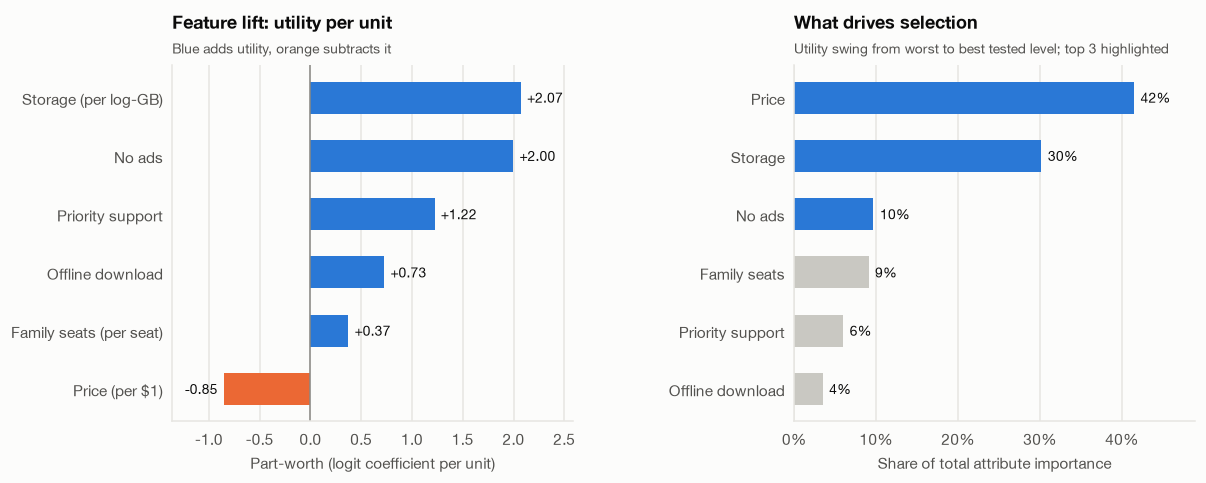

,estimate,ci_95_low,ci_95_high,p_value,p_vs_next_rank
price_usd,41.5%,40.8%,42.1%,<0.001,<0.001
log_storage_gb,30.2%,29.6%,30.8%,<0.001,<0.001
ads_NoAds,9.7%,9.2%,10.2%,<0.001,0.121
family_seats,9.1%,8.5%,9.7%,<0.001,<0.001
support_Priority,6.0%,5.5%,6.4%,<0.001,<0.001
offline_download_Yes,3.5%,3.1%,4.0%,<0.001,


In [12]:
LABELS = {
    'log_storage_gb': 'Storage (per log-GB)',
    'ads_NoAds': 'No ads',
    'support_Priority': 'Priority support',
    'offline_download_Yes': 'Offline download',
    'family_seats': 'Family seats (per seat)',
    'price_usd': 'Price (per $1)',
}

# Attribute importance = |coef| x (range of the feature across levels tested)
importance = (pw.abs() * (X_design.max() - X_design.min())).sort_values(ascending=False)
importance = pd.DataFrame(
    {
        'utility_range': importance.round(3),
        'share_of_importance': (importance / importance.sum()).round(3),
    }
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'wspace': 0.55})

# Left: part-worths per unit, features in blue, price (a cost) in orange
pw_sorted = pw.sort_values()
colors = [COLORS['orange'] if v < 0 else COLORS['blue'] for v in pw_sorted]
y = np.arange(len(pw_sorted))
ax1.barh(y, pw_sorted.values, color=colors, height=0.55)
ax1.set_yticks(y, [LABELS[n] for n in pw_sorted.index])
ax1.axvline(0, color=COLORS['muted'], lw=1)
pad = np.abs(pw_sorted).max() * 0.03
for yi, v in zip(y, pw_sorted.values):
    ax1.text(
        v + (pad if v >= 0 else -pad),
        yi,
        f'{v:+.2f}',
        va='center',
        ha='left' if v >= 0 else 'right',
        fontsize=9,
        color=COLORS['text'],
    )
ax1.set_xlim(pw_sorted.min() * 1.6, pw_sorted.max() * 1.25)
ax1.set_xlabel('Part-worth (logit coefficient per unit)')
ax1.grid(axis='y', visible=False)
ax1.set_title('Feature lift: utility per unit')
subtitle(ax1, 'Blue adds utility, orange subtracts it')

# Right: attribute importance (utility swing across tested levels)
imp = importance['share_of_importance'].sort_values()
y = np.arange(len(imp))
ax2.barh(
    y, imp.values, color=[COLORS['blue'] if n in imp.index[-3:] else COLORS['neutral'] for n in imp.index], height=0.55
)
ax2.set_yticks(y, [LABELS[n].split(' (')[0] for n in imp.index])
for yi, v in zip(y, imp.values):
    ax2.text(v + 0.008, yi, f'{v:.0%}', va='center', fontsize=9, color=COLORS['text'])
ax2.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax2.set_xlim(0, imp.max() * 1.18)
ax2.set_xlabel('Share of total attribute importance')
ax2.grid(axis='y', visible=False)
ax2.set_title('What drives selection')
subtitle(ax2, 'Utility swing from worst to best tested level; top 3 highlighted')

plt.show()

# Importance shares with 95% CIs, plus a test that each driver outranks the next one
feature_range = X_design.max() - X_design.min()
imp_share = lambda b: (b.abs() * feature_range) / (b.abs() * feature_range).sum()
imp_draws = boot_apply(imp_share, boot_pw)
imp_ci = boot_summary(imp_share(pw), imp_draws).sort_values('estimate', ascending=False)
order_imp = imp_ci.index.tolist()
upper, lower = order_imp[:-1], order_imp[1:]  # each driver paired with the one ranked just below it
gap_est = pd.Series(imp_ci['estimate'].loc[upper].to_numpy() - imp_ci['estimate'].loc[lower].to_numpy(), index=upper)
gap_draws = pd.DataFrame(imp_draws[upper].to_numpy() - imp_draws[lower].to_numpy(), columns=upper)
imp_ci['p_vs_next_rank'] = boot_summary(gap_est, gap_draws)['p_value']
display(
    mark(
        imp_ci.drop(columns='boot_se').style.format(
            {
                'estimate': '{:.1%}',
                'ci_95_low': '{:.1%}',
                'ci_95_high': '{:.1%}',
                'p_value': fmt_p,
                'p_vs_next_rank': lambda p: '' if pd.isna(p) else fmt_p(p),
            }
        ),
        [
            (['price_usd', 'log_storage_gb', 'ads_NoAds', 'family_seats'], ['estimate', 'ci_95_low', 'ci_95_high']),
            (['support_Priority', 'offline_download_Yes'], 'estimate'),
            (order_imp[:-1], 'p_vs_next_rank'),
        ],
        title='Attribute importance with 95% CIs',
    )
)

**Result:** **Log storage, no ads and Priority support have the largest coefficients, while price and storage lead on importance share.**

**Top 3 drivers by absolute coefficient** (coefficient table in 1.2):
1. **Log storage, 2.071:** adds value, per unit of log GB.
2. **No ads, 1.997:** adds value.
3. **Priority support, 1.222:** adds value.

Price, at -0.851 per dollar, subtracts value and ranks 4th by coefficient.

**Why importance share ranks differently:** a coefficient measures one unit, while importance share accounts for the range tested. Price is small per dollar but spans \$5 to \$15, so it moves to first. Family seats have the smallest coefficient but rise to a tie for third, because several seats were tested.

**Ranking by importance share:**
1. **Price, 41.5% [40.8%, 42.1%]:** every extra dollar has to be earned by features.
2. **Storage, 30.2% [29.6%, 30.8%]:** the most valuable feature, with diminishing returns per GB.
3. **No ads, 9.7% [9.2%, 10.2%], and family seats, 9.1% [8.5%, 9.7%]:** statistically tied for third (p = 0.12).

Every other driver is significantly larger than the next one down (p < 0.001). Priority support (6.0%) and offline download (3.5%) are secondary.

### 1.4 Willingness to pay (WTP)

**Purpose:** put each feature in dollars, because pricing decisions need value in the same units as price.

$$
\text{WTP}_k = -\frac{\beta_k}{\beta_{\text{price}}}
$$

converts a feature's utility into dollars: the monthly price increase that would exactly offset it. Storage is reported per upgrade step.

In [13]:
# Willingness to pay = -beta_feature / beta_price, with bootstrap CIs
beta_price = pw['price_usd']
wtp = (-pw.drop('price_usd') / beta_price).rename('wtp_usd_per_unit')


def wtp_fn(b):
    """Willingness to pay by feature in USD/month for one set of part-worths."""
    w = -b.drop('price_usd') / b['price_usd']
    return pd.Series(
        {
            'No ads': w['ads_NoAds'],
            'Priority support': w['support_Priority'],
            'Offline download': w['offline_download_Yes'],
            'Each extra family seat': w['family_seats'],
            'Storage 50 → 200 GB': w['log_storage_gb'] * np.log(200 / 50),
            'Storage 200 → 1000 GB': w['log_storage_gb'] * np.log(1000 / 200),
        }
    )


wtp_ci = boot_summary(wtp_fn(pw), boot_apply(wtp_fn, boot_pw))
show_ci(
    wtp_ci,
    'usd',
    marks=[(None, ['estimate', 'ci_95_low', 'ci_95_high', 'p_value'])],
    title='Willingness to pay by feature (USD/month)',
)

show_facts(
    {
        'beta, no ads': f"{pw['ads_NoAds']:.3f}",
        'beta, price': f'{beta_price:.3f}',
        'WTP for no ads = -beta_NoAds / beta_price': f"${wtp['ads_NoAds']:.2f}",
    },
    'Worked WTP example (USD/month)',
)

,estimate,ci_95_low,ci_95_high,boot_se,p_value
No ads,$2.35,$2.21,$2.49,$0.07,<0.001
Priority support,$1.44,$1.32,$1.55,$0.06,<0.001
Offline download,$0.85,$0.73,$0.97,$0.06,<0.001
Each extra family seat,$0.44,$0.41,$0.47,$0.02,<0.001
Storage 50 → 200 GB,$3.37,$3.29,$3.46,$0.05,<0.001
Storage 200 → 1000 GB,$3.92,$3.82,$4.02,$0.05,<0.001


,value
"beta, no ads",1.997
"beta, price",-0.851
WTP for no ads = -beta_NoAds / beta_price,$2.35


**Result:** **Storage upgrades are worth the most to the average respondent, followed by no ads (USD per month).**
- **Storage:** \$3.37 [3.29, 3.46] for 50 → 200 GB and \$3.92 [3.82, 4.02] for 200 → 1000 GB.
- **No ads:** \$2.35 [2.21, 2.49].
- **Priority support:** \$1.44 [1.32, 1.55].
- **Offline download:** \$0.85 [0.73, 0.97].
- **Each extra seat:** \$0.44 [0.41, 0.47].
- All are significantly above zero (p < 0.001). These values are compared with each bundle's price premium next (1.5).

#### Check: does the model choice change these numbers?

**Purpose:** refit the same features with a standard (pooled) logistic regression, to show whether the results depend on the choice of model. It compares two models, so it is reported without CIs.

In [14]:
# Robustness check: pooled binary logistic regression (each alternative treated as an independent yes/no row).
# Its coefficients are on a different scale, but the WTP ratios should agree.
pooled = LogisticRegression(C=np.inf, max_iter=2000).fit(X_design, df_choice['chosen'])
pw_pooled = pd.Series(pooled.coef_[0], index=X_design.columns)

wtp_check = pd.DataFrame(
    {
        'coef_conditional_logit': pw,
        'coef_pooled_logistic': pw_pooled,
        'WTP_conditional_logit': -pw / pw['price_usd'],
        'WTP_pooled_logistic': -pw_pooled / pw_pooled['price_usd'],
    }
).drop('price_usd', errors='ignore')
display(
    mark(
        wtp_check.style.format('{:.3f}'),
        [(None, ['WTP_conditional_logit', 'WTP_pooled_logistic'])],
        title='Coefficients and WTP: conditional logit vs. pooled logistic',
    )
)

# Pooled logistic ignores the one-choice-per-task constraint: its probabilities don't sum to 1 per task
pooled_sum = pd.Series(pooled.predict_proba(X_design)[:, 1]).groupby(task_group.values).sum()
show_facts(
    {'Lowest task total': f'{pooled_sum.min():.2f}', 'Highest task total': f'{pooled_sum.max():.2f}'},
    'Pooled logistic: predicted probabilities per choice task (should total 1.00)',
)

# Consequence for bundle shares: pooled coefficients flatten the shares
u_pooled = preprocess.transform(df_bundles).astype(float) @ pw_pooled
display(
    pd.DataFrame(
        {
            'share_conditional_logit': choice_prob(df_bundles, np.zeros(len(df_bundles))).values,
            'share_pooled_logistic': logit_shares(u_pooled).values,
        },
        index=df_bundles['bundle'],
    )
    .style.format('{:.0%}')
    .pipe(mark, [('Mid', None)], title='Share of preference: conditional logit vs. pooled logistic')
)

,coef_conditional_logit,coef_pooled_logistic,WTP_conditional_logit,WTP_pooled_logistic
log_storage_gb,2.071,0.881,2.433,2.441
family_seats,0.374,0.159,0.439,0.441
support_Priority,1.222,0.507,1.436,1.404
ads_NoAds,1.997,0.837,2.346,2.319
offline_download_Yes,0.727,0.307,0.854,0.851


,value
Lowest task total,0.04
Highest task total,2.67


,share_conditional_logit,share_pooled_logistic
bundle,,
Budget,1%,7%
Mid,61%,43%
Premium,32%,33%
ValuePlus,7%,17%


**Result:** **WTP does not depend on the model, but shares do, so shares and demand curves use the conditional logit.**
- WTP is close in both models, e.g., no ads \$2.35 vs. \$2.32 and Priority support \$1.44 vs. \$1.40, inside the CIs (1.4).
- The pooled model's probabilities within a task total 0.04 to 2.67 instead of 1.
- The pooled model would understate Mid's share (43% vs. 61%).

### 1.5 Bundle comparison

**Purpose:** decide which bundle should lead, because the most preferred bundle is not always the one that earns the most or gives fair value.

Each candidate bundle is scored with the model. **Share of preference** is its chance of being picked when all four compete, relative to these four only. **Expected revenue per subscriber** $= \text{share} \times \text{price}$ is the expected monthly revenue from one customer who subscribes to one of the four.

The Mid vs. Premium gaps are tested because a lead only matters if the two bundles really differ. Net value checks whether each price is justified: $\text{net value} = \Delta\,\text{feature value} - \Delta\,\text{price}$, relative to Mid. Below \$0, a bundle charges more than its extra features are worth, or saves less than the features it drops.

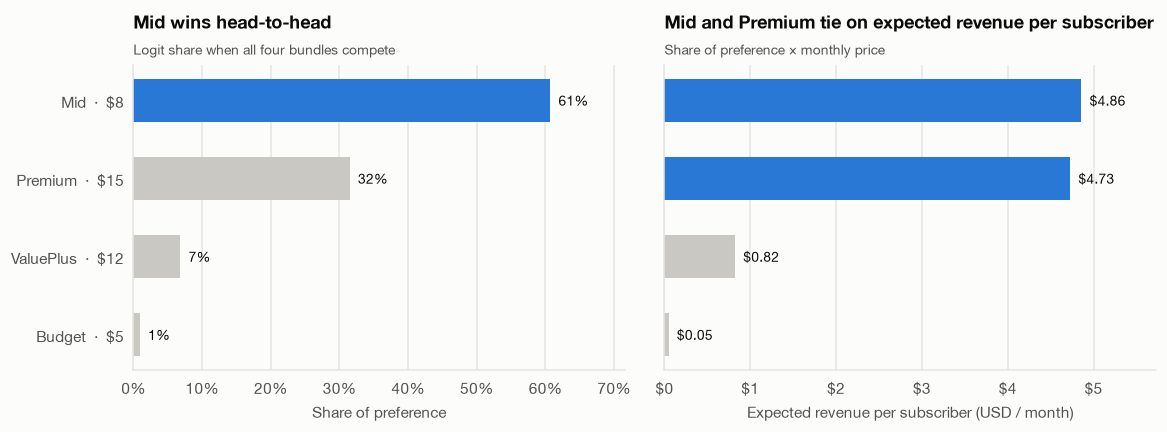

rank,bundle,price_usd,storage_gb,support,ads,family_seats,offline_download,share_of_preference,expected_revenue_per_subscriber
1,Mid,8,200,Standard,NoAds,4,Yes,60.7%,$4.86
2,Premium,15,1000,Priority,NoAds,6,Yes,31.5%,$4.73
3,ValuePlus,12,200,Priority,NoAds,4,Yes,6.8%,$0.82
4,Budget,5,50,Standard,Ads,1,No,0.9%,$0.05


In [15]:
bundle_scores = df_bundles.copy()
bundle_scores['share_of_preference'] = choice_prob(df_bundles, np.zeros(len(df_bundles)))
bundle_scores['revenue_index'] = (
    bundle_scores['share_of_preference'] * bundle_scores['price_usd']
)  # expected $ per subscriber
bundle_scores = bundle_scores.sort_values('share_of_preference', ascending=False)

plot_df = bundle_scores.iloc[::-1]  # barh draws bottom-up, so the leader lands on top
leader = bundle_scores['bundle'].iloc[0]
top_rev = bundle_scores.loc[
    bundle_scores['revenue_index'] >= 0.9 * bundle_scores['revenue_index'].max(), 'bundle'
].tolist()  # near-tied leaders
y = np.arange(len(plot_df))
labels = [f"{b}  ·  ${p}" for b, p in zip(plot_df['bundle'], plot_df['price_usd'])]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True, gridspec_kw={'wspace': 0.08})
panels = [
    (
        ax1,
        'share_of_preference',
        [leader],
        lambda v: f'{v:.0%}',
        'Share of preference',
        'Mid wins head-to-head',
        'Logit share when all four bundles compete',
    ),
    (
        ax2,
        'revenue_index',
        top_rev,
        lambda v: f'${v:.2f}',
        'Expected revenue per subscriber (USD / month)',
        'Mid and Premium tie on expected revenue per subscriber',
        'Share of preference × monthly price',
    ),
]
for ax, col, hi, fmt, xlabel, title, sub in panels:
    vals = plot_df[col].values
    ax.barh(y, vals, height=0.55, color=[COLORS['blue'] if b in hi else COLORS['neutral'] for b in plot_df['bundle']])
    for yi, v in zip(y, vals):
        ax.text(v + vals.max() * 0.02, yi, fmt(v), va='center', fontsize=9, color=COLORS['text'])
    ax.set_xlim(0, vals.max() * 1.18)
    ax.set_xlabel(xlabel)
    ax.grid(axis='y', visible=False)
    ax.set_title(title)
    subtitle(ax, sub)
ax1.set_yticks(y, labels)
ax1.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax2.xaxis.set_major_formatter(lambda x, _: f'${x:.0f}')
ax2.tick_params(axis='y', length=0)

plt.show()

# The full scorecard: every bundle's features with its share and expected revenue, ranked
scorecard = bundle_scores.rename(columns={'revenue_index': 'expected_revenue_per_subscriber'})
scorecard.insert(0, 'rank', range(1, len(scorecard) + 1))
display(
    mark(
        scorecard.style.hide(axis='index').format(
            {'share_of_preference': '{:.1%}', 'expected_revenue_per_subscriber': '${:.2f}'}
        ),
        [(None, ['share_of_preference', 'expected_revenue_per_subscriber'])],
        title='Candidate bundles scored and ranked by share of preference',
    )
)

In [16]:
# Shares and revenue per subscriber with 95% CIs, and the Mid-vs-Premium gaps
X_bundles = preprocess.transform(df_bundles).astype(float)
bundle_names = df_bundles['bundle'].tolist()
bundle_prices = df_bundles.set_index('bundle')['price_usd']


def bundle_metrics(b):
    """Share, expected revenue and the Mid-vs-Premium gaps for one set of part-worths."""
    u = X_bundles.to_numpy() @ b.to_numpy()
    s = pd.Series(logit_shares(u), index=bundle_names)
    r = s * bundle_prices
    return pd.concat(
        [
            s.add_prefix('share: '),
            r.add_prefix('revenue: '),
            pd.Series(
                {
                    'share gap: Mid − Premium': s['Mid'] - s['Premium'],
                    'revenue gap: Mid − Premium': r['Mid'] - r['Premium'],
                }
            ),
        ]
    )


bm_ci = boot_summary(bundle_metrics(pw), boot_apply(bundle_metrics, boot_pw))
share_rows = [f'share: {b}' for b in ['Mid', 'Premium', 'ValuePlus', 'Budget']] + ['share gap: Mid − Premium']
rev_rows = [f'revenue: {b}' for b in ['Mid', 'Premium', 'ValuePlus', 'Budget']] + ['revenue gap: Mid − Premium']
show_ci(
    bm_ci.loc[share_rows],
    'pct',
    marks=[
        (['share: Mid', 'share: Premium'], ['estimate', 'ci_95_low', 'ci_95_high']),
        (['share: ValuePlus', 'share: Budget'], 'estimate'),
        ('share gap: Mid − Premium', ['estimate', 'p_value']),
    ],
    title='Share of preference by bundle',
)
show_ci(
    bm_ci.loc[rev_rows],
    'usd',
    marks=[
        (['revenue: Mid', 'revenue: Premium'], 'estimate'),
        ('revenue gap: Mid − Premium', ['estimate', 'ci_95_low', 'ci_95_high', 'p_value']),
    ],
    title='Expected revenue per subscriber by bundle: share × price (USD/month)',
)

,estimate,ci_95_low,ci_95_high,boot_se,p_value
share: Mid,60.7%,57.5%,64.2%,1.8%,<0.001
share: Premium,31.5%,28.3%,34.7%,1.7%,<0.001
share: ValuePlus,6.8%,6.2%,7.6%,0.4%,<0.001
share: Budget,0.9%,0.7%,1.2%,0.1%,<0.001
share gap: Mid − Premium,29.2%,23.0%,35.9%,3.5%,<0.001


,estimate,ci_95_low,ci_95_high,boot_se,p_value
revenue: Mid,$4.86,$4.60,$5.13,$0.15,<0.001
revenue: Premium,$4.73,$4.24,$5.20,$0.25,<0.001
revenue: ValuePlus,$0.82,$0.74,$0.91,$0.04,<0.001
revenue: Budget,$0.05,$0.04,$0.06,$0.01,<0.001
revenue gap: Mid − Premium,$0.13,-$0.59,$0.89,$0.40,0.742


In [17]:
# Why each bundle wins or loses: dollar value of its features vs. its price, both relative to Mid
def value_fn(b):
    """Feature value and net value of each bundle relative to Mid, in USD/month."""
    # Feature value = utility with the price term removed, converted to USD/month (sum of the features' WTP).
    # Its absolute level depends on arbitrary baselines (log of 1 GB, 0 seats), so only gaps to Mid are reported.
    fv = (X_bundles.to_numpy() @ b.to_numpy() - b['price_usd'] * bundle_prices.to_numpy()) / -b['price_usd']
    fv = pd.Series(fv, index=bundle_names)
    out = {}
    for name in ['Budget', 'ValuePlus', 'Premium']:
        out[f'{name}: feature value vs Mid'] = fv[name] - fv['Mid']
        out[f'{name}: net value vs Mid'] = fv[name] - fv['Mid'] - (bundle_prices[name] - bundle_prices['Mid'])
    return pd.Series(out)


print('Price vs Mid:', (bundle_prices - bundle_prices['Mid']).drop('Mid').to_dict())
show_ci(
    boot_summary(value_fn(pw), boot_apply(value_fn, boot_pw)),
    'usd',
    marks=[
        (None, ['estimate', 'p_value']),
        (
            [
                'Premium: feature value vs Mid',
                'Premium: net value vs Mid',
                'ValuePlus: net value vs Mid',
                'Budget: feature value vs Mid',
            ],
            ['ci_95_low', 'ci_95_high'],
        ),
    ],
    title='Bundle value relative to Mid (USD/month)',
)

Price vs Mid: {'Budget': -3, 'Premium': 7, 'ValuePlus': 4}


,estimate,ci_95_low,ci_95_high,boot_se,p_value
Budget: feature value vs Mid,-$7.89,-$8.16,-$7.64,$0.14,<0.001
Budget: net value vs Mid,-$4.89,-$5.16,-$4.64,$0.14,<0.001
ValuePlus: feature value vs Mid,$1.44,$1.32,$1.55,$0.06,<0.001
ValuePlus: net value vs Mid,-$2.56,-$2.68,-$2.45,$0.06,<0.001
Premium: feature value vs Mid,$6.23,$6.06,$6.40,$0.09,<0.001
Premium: net value vs Mid,-$0.77,-$0.94,-$0.60,$0.09,<0.001


**Result:** **Mid (\$8) is the clear favorite on share, and Mid and Premium are statistically tied on expected revenue per subscriber.**
- **Share of preference:** Mid 60.7% [57.5%, 64.2%] vs. Premium 31.5% [28.3%, 34.7%], a lead of 29 percentage points (p < 0.001). ValuePlus (6.8%) and Budget (0.9%) barely register.
- **Expected revenue per subscriber per month:** Mid \$4.86 vs. Premium \$4.73. The \$0.13 gap has a CI of [-\$0.59, \$0.89] (p = 0.74). Its sign depends on the model: the segment models reverse it (3.6).
- **Net value explains why** (feature value minus extra price, relative to Mid; all p < 0.001):
  - **Premium:** extras worth \$6.23 [6.06, 6.40] for \$7 more, net -\$0.77 [-0.94, -0.60]. It sits slightly but significantly below its price for the average respondent.
  - **ValuePlus:** Priority support worth \$1.44 for \$4 more, net -\$2.56 [-2.68, -2.45]. It would match Mid's value only at Mid's \$8 plus that \$1.44.
  - **Budget:** saves \$3 but gives up \$7.89 [7.64, 8.16] of features, net -\$4.89.

### 1.6 Price sensitivity

**Purpose:** check the model's price response against the survey, then find how far Mid's price can move before demand shifts to another bundle.

- **Left (survey data):** share of alternatives chosen at each tested price (\$5, \$8, \$12, \$15), observed vs. model-predicted.
- **Right (simulation):** Mid's share as only its price changes, with the three other bundles held at their listed prices.

The two charts answer different questions, so the same price gives different percentages: at \$8 the left averages every feature mix in 3-way choices (42%), while the right follows Mid's specific features against specific rivals in a 4-way choice (61%).

The model's predictions are checked against observed choose-rates, with CIs from resampling respondents, because the simulation is only useful if the model reproduces observed price response. The *Premium − Mid* gap shows the price at which Premium would overtake Mid.

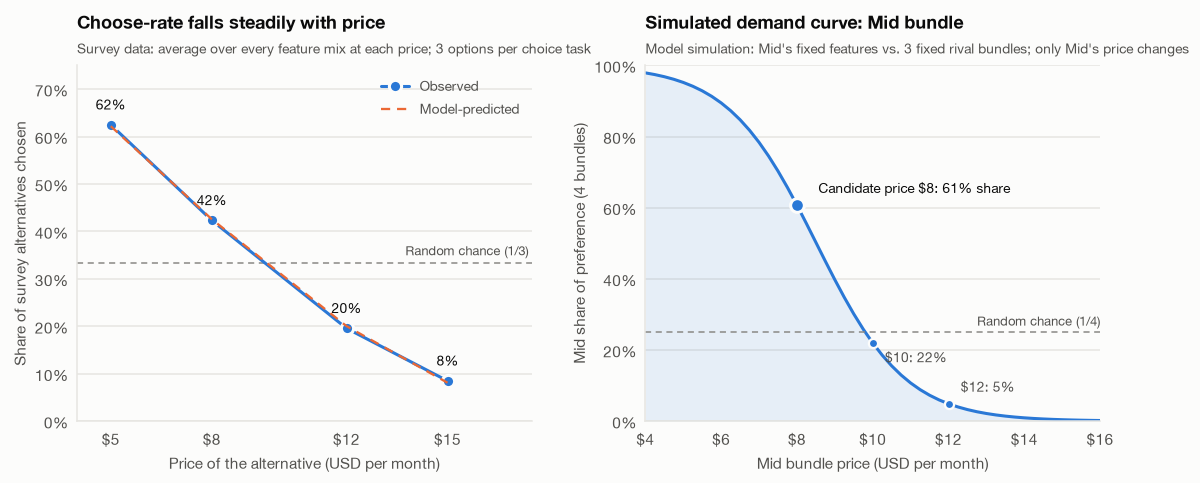

In [18]:
# Empirical choose-rate vs. model-implied choice probability at each price level
df_choice['p_hat'] = choice_prob(df_choice, task_group)
ps = (
    df_choice.groupby('price_usd')
    .agg(observed_choose_rate=('chosen', 'mean'), predicted_choose_rate=('p_hat', 'mean'))
    .reset_index()
)
n_alts = df_choice['alternative'].nunique()

# Mid bundle's share of preference vs. the other candidate bundles as its own price varies
price_grid = np.arange(4, 16.25, 0.25)
mid_share = []
for p in price_grid:
    b = df_bundles.astype({'price_usd': float})
    b.loc[b['bundle'] == 'Mid', 'price_usd'] = p
    share = choice_prob(b, np.zeros(len(b)))
    mid_share.append(share[b['bundle'].eq('Mid')].iloc[0])
mid_share = np.array(mid_share)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'wspace': 0.25})

# Left: observed vs predicted
ax1.axhline(1 / n_alts, color=COLORS['muted'], lw=1, ls=(0, (4, 3)))
ax1.text(
    17.4,
    1 / n_alts + 0.01,
    f'Random chance (1/{n_alts})',
    ha='right',
    va='bottom',
    fontsize=8.5,
    color=COLORS['text_2'],
)
ax1.plot(
    ps['price_usd'],
    ps['observed_choose_rate'],
    color=COLORS['blue'],
    marker='o',
    ms=8,
    mec=COLORS['surface'],
    mew=2,
    label='Observed',
    zorder=3,
)
ax1.plot(
    ps['price_usd'],
    ps['predicted_choose_rate'],
    color=COLORS['orange'],
    lw=1.5,
    ls=(0, (4, 3)),
    label='Model-predicted',
    zorder=4,
)
for x, v in zip(ps['price_usd'], ps['observed_choose_rate']):
    ax1.annotate(
        f'{v:.0%}', (x, v), xytext=(0, 10), textcoords='offset points', ha='center', fontsize=9, color=COLORS['text']
    )
ax1.set_xticks(ps['price_usd'], [f'${p}' for p in ps['price_usd']])
ax1.set_xlim(4, 17.5)
ax1.set_ylim(0, 0.75)
ax1.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax1.set_xlabel('Price of the alternative (USD per month)')
ax1.set_ylabel('Share of survey alternatives chosen')
ax1.grid(axis='x', visible=False)
ax1.legend(loc='upper right')
ax1.set_title('Choose-rate falls steadily with price')
subtitle(ax1, 'Survey data: average over every feature mix at each price; 3 options per choice task')

# Right: simulated demand curve for Mid
cur = df_bundles.loc[df_bundles['bundle'] == 'Mid', 'price_usd'].iloc[0]
cur_share = np.interp(cur, price_grid, mid_share)
ax2.fill_between(price_grid, mid_share, color=COLORS['blue'], alpha=0.10, lw=0)
ax2.plot(price_grid, mid_share, color=COLORS['blue'])
ax2.axhline(1 / len(df_bundles), color=COLORS['muted'], lw=1, ls=(0, (4, 3)))
ax2.text(
    price_grid.max(),
    1 / len(df_bundles) + 0.01,
    f'Random chance (1/{len(df_bundles)})',
    ha='right',
    va='bottom',
    fontsize=8.5,
    color=COLORS['text_2'],
)
ax2.plot([cur], [cur_share], 'o', color=COLORS['blue'], ms=9, mec=COLORS['surface'], mew=2, zorder=3)
ax2.annotate(
    f'Candidate price ${cur}: {cur_share:.0%} share',
    (cur, cur_share),
    xytext=(14, 8),
    textcoords='offset points',
    fontsize=9,
    color=COLORS['text'],
)
for p in (10, 12):
    s = np.interp(p, price_grid, mid_share)
    ax2.plot([p], [s], 'o', color=COLORS['blue'], ms=6, mec=COLORS['surface'], mew=1.5, zorder=3)
    below = p == 10  # keep the $10 label clear of the random-chance line
    ax2.annotate(
        f'${p}: {s:.0%}',
        (p, s),
        xytext=(8, -4 if below else 6),
        textcoords='offset points',
        va='top' if below else 'bottom',
        fontsize=9,
        color=COLORS['text_2'],
    )
ax2.set_xlim(price_grid.min(), price_grid.max())
ax2.set_ylim(0, 1.0)
ax2.xaxis.set_major_formatter(lambda x, _: f'${x:.0f}')
ax2.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax2.set_xlabel('Mid bundle price (USD per month)')
ax2.set_ylabel('Mid share of preference (4 bundles)')
ax2.grid(axis='x', visible=False)
ax2.set_title('Simulated demand curve: Mid bundle')
subtitle(ax2, 'Model simulation: Mid\'s fixed features vs. 3 fixed rival bundles; only Mid\'s price changes')

plt.show()

In [19]:
# Observed choose-rate by price with respondent-clustered 95% CIs
counts = df_choice.groupby(['respondent_id', 'price_usd'])['chosen'].agg(['sum', 'count']).unstack(fill_value=0)
resp_ids = counts.index.to_numpy()
rate_rng = np.random.Generator(np.random.PCG64())
rate_rng.bit_generator.state = rate_rng_state
rate_draws = []
for _ in range(CHOICE_BOOT):
    c = counts.loc[rate_rng.choice(resp_ids, size=len(resp_ids), replace=True)].sum()
    rate_draws.append(c['sum'] / c['count'])
rate_draws = pd.DataFrame(rate_draws)
obs = ps.set_index('price_usd')
rate_ci = pd.DataFrame(
    {
        'observed': obs['observed_choose_rate'],
        'ci_95_low': rate_draws.quantile(0.025),
        'ci_95_high': rate_draws.quantile(0.975),
        'predicted': obs['predicted_choose_rate'],
    }
)
rate_ci['predicted_within_ci'] = rate_ci['predicted'].between(rate_ci['ci_95_low'], rate_ci['ci_95_high'])
display(
    mark(
        rate_ci.style.format({c: '{:.1%}' for c in ['observed', 'ci_95_low', 'ci_95_high', 'predicted']}),
        [
            (8, ['observed', 'ci_95_low', 'ci_95_high', 'predicted']),
            (None, 'predicted_within_ci'),
        ],
        title='Choose rate by price: observed vs. model-predicted',
    )
)

# Mid's demand curve at key prices (other bundles fixed), with 95% CIs
key_prices = [7, 8, 9, 10, 12]
mid_i, prem_i = bundle_names.index('Mid'), bundle_names.index('Premium')


def mid_demand(b):
    """Mid and Premium shares at each key Mid price, other bundles held fixed."""
    out = {}
    for p in key_prices:
        Xp = X_bundles.copy()
        Xp.loc[Xp.index[mid_i], 'price_usd'] = p
        u = Xp.to_numpy() @ b.to_numpy()
        s = logit_shares(u)
        out[f'${p}: Mid share'] = s[mid_i]
        out[f'${p}: Premium share'] = s[prem_i]
        out[f'${p}: Premium − Mid'] = s[prem_i] - s[mid_i]
    return pd.Series(out)


show_ci(
    boot_summary(mid_demand(pw), boot_apply(mid_demand, boot_pw)),
    'pct',
    marks=[
        ('$8: Mid share', 'estimate'),
        (['$9: Mid share', '$10: Mid share'], ['estimate', 'ci_95_low', 'ci_95_high']),
        ('$9: Premium share', 'estimate'),
        ('$9: Premium − Mid', ['estimate', 'ci_95_low', 'ci_95_high', 'p_value']),
    ],
    title="Mid and Premium share at different Mid prices (other bundles fixed)",
)

,observed,ci_95_low,ci_95_high,predicted,predicted_within_ci
price_usd,,,,,
5,62.5%,61.4%,63.5%,62.2%,True
8,42.3%,41.3%,43.3%,42.6%,True
12,19.6%,18.7%,20.5%,20.0%,True
15,8.5%,7.8%,9.2%,8.1%,True


,estimate,ci_95_low,ci_95_high,boot_se,p_value
$7: Mid share,78.4%,75.5%,81.1%,1.5%,<0.001
$7: Premium share,17.4%,14.9%,19.8%,1.3%,<0.001
$7: Premium − Mid,-61.0%,-66.2%,-55.8%,2.7%,<0.001
$8: Mid share,60.7%,57.5%,64.2%,1.8%,<0.001
$8: Premium share,31.5%,28.3%,34.7%,1.7%,<0.001
$8: Premium − Mid,-29.2%,-35.9%,-23.0%,3.5%,<0.001
$9: Mid share,39.7%,36.6%,42.9%,1.7%,<0.001
$9: Premium share,48.3%,44.9%,51.8%,1.8%,<0.001
$9: Premium − Mid,8.6%,2.3%,15.2%,3.4%,0.012
$10: Mid share,22.0%,19.7%,24.3%,1.1%,<0.001


**Result:** **The model reproduces observed choose-rates, and in simulation Mid's share falls quickly above \$8.**
- **Model check:** at every tested price the predicted choose-rate falls inside the observed rate's CI (e.g., \$8: observed 42.3% [41.3%, 43.3%], predicted 42.6%).
- **Mid's simulated share:** 60.7% at \$8, 39.7% [36.6%, 42.9%] at \$9 and 22.0% [19.7%, 24.3%] at \$10.
- **Premium leads with Mid at \$9:** 48.3% vs. 39.7%, a gap of 8.6 percentage points [2.3, 15.2] (p = 0.012).
- **\$9 and \$10 are interpolated:** the survey did not test prices between \$8 and \$12, so keep Mid at \$8 unless a live price test says otherwise.

#### All four bundles

**Purpose:** compare price sensitivity across the four candidates, because a price change on one bundle moves shares across all four.

The same simulation is run for each bundle in turn. The shaded band is the \$5–\$15 range tested in the survey, and prices outside that band are extrapolation.

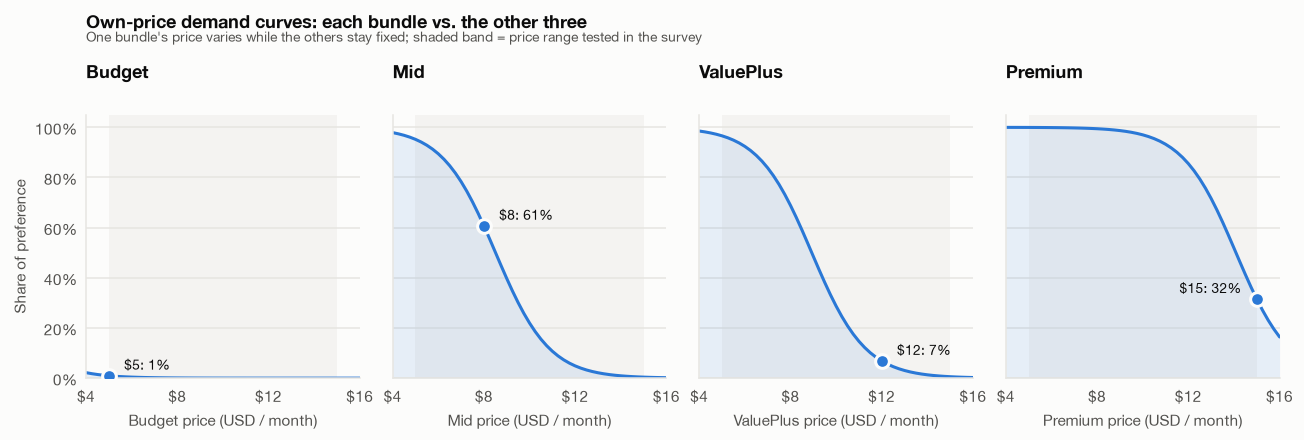

,price − $1,candidate price,price + $1
Budget ($5),"2% [2%, 3%]","1% [1%, 1%]","0% [0%, 1%]"
Mid ($8),"78% [76%, 81%]","61% [57%, 64%]","40% [37%, 43%]"
ValuePlus ($12),"15% [14%, 16%]","7% [6%, 8%]","3% [3%, 3%]"
Premium ($15),"52% [48%, 55%]","32% [28%, 35%]","16% [14%, 19%]"


In [20]:
def own_price_curve(bundle, grid):
    """Share of preference for `bundle` as its own price varies, other bundles held fixed."""
    shares = []
    for p in grid:
        b = df_bundles.astype({'price_usd': float})
        b.loc[b['bundle'] == bundle, 'price_usd'] = p
        share = choice_prob(b, np.zeros(len(b)))
        shares.append(share[b['bundle'].eq(bundle)].iloc[0])
    return np.array(shares)


bundle_order = ['Budget', 'Mid', 'ValuePlus', 'Premium']  # cheapest to most expensive
curves = {name: own_price_curve(name, price_grid) for name in bundle_order}

fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True, gridspec_kw={'wspace': 0.12})
for ax, name in zip(axes, bundle_order):
    cur = df_bundles.loc[df_bundles['bundle'] == name, 'price_usd'].iloc[0]
    share = curves[name]
    at = lambda p: np.interp(p, price_grid, share)

    ax.axvspan(5, 15, color=COLORS['grid'], alpha=0.35, lw=0)
    ax.fill_between(price_grid, share, color=COLORS['blue'], alpha=0.10, lw=0)
    ax.plot(price_grid, share, color=COLORS['blue'])
    ax.plot([cur], [at(cur)], 'o', color=COLORS['blue'], ms=9, mec=COLORS['surface'], mew=2, zorder=3)
    right_edge = cur > 13
    ax.annotate(
        f'${cur}: {at(cur):.0%}',
        (cur, at(cur)),
        xytext=(-10 if right_edge else 10, 4),
        textcoords='offset points',
        ha='right' if right_edge else 'left',
        fontsize=9,
        color=COLORS['text'],
    )

    ax.set_xlim(price_grid.min(), price_grid.max())
    ax.set_xticks([4, 8, 12, 16])
    ax.xaxis.set_major_formatter(lambda x, _: f'${x:.0f}')
    ax.grid(axis='x', visible=False)
    ax.set_title(name)
    ax.set_xlabel(f'{name} price (USD / month)')


axes[0].set_ylim(0, 1.05)
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].set_ylabel('Share of preference')
fig.subplots_adjust(top=0.74)
fig.suptitle(
    'Own-price demand curves: each bundle vs. the other three',
    x=0.125,
    y=0.99,
    ha='left',
    fontsize=12,
    fontweight='bold',
)
fig.text(
    0.125,
    0.915,
    'One bundle\'s price varies while the others stay fixed; shaded band = price range tested in the survey',
    ha='left',
    fontsize=9,
    color=COLORS['text_2'],
)
plt.show()


# Each bundle's share at its candidate price and ±$1 (others fixed), estimate [95% CI]
def own_price_points(b):
    """Each bundle's share at its price and $1 either side."""
    out = {}
    for i, name in enumerate(bundle_names):
        for d in (-1, 0, 1):
            Xp = X_bundles.copy()
            Xp.loc[Xp.index[i], 'price_usd'] = bundle_prices[name] + d
            u = Xp.to_numpy() @ b.to_numpy()
            out[(name, d)] = logit_shares(u)[i]
    return pd.Series(out)


opp = boot_summary(own_price_points(pw), boot_apply(own_price_points, boot_pw))
demand_summary = pd.DataFrame(
    {
        col: [ci_str(*opp.loc[[(n, d)], ['estimate', 'ci_95_low', 'ci_95_high']].iloc[0], 'pct') for n in bundle_order]
        for d, col in [(-1, 'price − $1'), (0, 'candidate price'), (1, 'price + $1')]
    },
    index=[f'{n} (${bundle_prices[n]})' for n in bundle_order],
)
display(
    mark(
        demand_summary.style,
        [
            ('Premium ($15)', ['price − $1', 'price + $1']),
            ('ValuePlus ($12)', ['price − $1', 'candidate price']),
            ('Budget ($5)', 'price − $1'),
        ],
        title="Each bundle's share at its candidate price and ±$1: estimate [95% CI]",
    )
)

**Result:** **Price moves Premium and ValuePlus strongly, but it does not rescue Budget.**
- **Premium is also price-sensitive:** at \$14 it would reach 52% [48%, 55%], and at \$16 it drops to 16% [14%, 19%].
- **ValuePlus is over-priced, not unwanted:** a \$1 cut roughly doubles its share (7% to 15% [14%, 16%]), but it still trails Mid because its net value remains below Mid's (1.5).
- **Budget stays at 2% [2%, 3%] even at \$4:** its feature set, not its price, is the problem.
- **Range:** \$14 is interpolated, while \$16 and \$4 are outside the tested range, so they are extrapolations.

These curves show shifts between bundles, not total demand: with no "none" option, nobody leaves the market when prices rise, so they should not be used to set revenue-maximizing prices.

### 1.7 Segments: do different customers want different bundles?

**Purpose:** test whether the average hides groups that want different bundles, because that decides who each bundle should be built and messaged for.

The model above describes the average respondent. Here it is refit separately for each labeled segment (`segment_true`), and a likelihood-ratio test checks whether the segments really differ. Premium's upgrades are also compared with its \$7 price gap in each segment, to show which segments value them above that gap.

In [21]:
seg_fits, seg_shares = {}, {}

for seg in segments:
    mask = df_choice['segment_true'].eq(seg)
    X_seg = X_design[mask]
    g_seg = df_choice.loc[mask].groupby(['respondent_id', 'task_id']).ngroup()
    fit = ConditionalLogit(df_choice.loc[mask, 'chosen'], X_seg, groups=g_seg).fit(disp=False)
    seg_fits[seg] = fit
    u = preprocess.transform(df_bundles).astype(float) @ fit.params
    seg_shares[seg] = pd.Series(logit_shares(u.values), index=df_bundles['bundle'])

# Likelihood-ratio test: segment-specific part-worths vs. one pooled set
ll_segments = sum(f.llf for f in seg_fits.values())
lr_stat = 2 * (ll_segments - clogit.llf)
lr_df = len(pw) * (len(segments) - 1)

seg_size = df_choice.groupby('segment_true')['respondent_id'].nunique().reindex(segments)
show_facts(
    {
        'LR chi-square, segment models vs. pooled': f'{lr_stat:,.0f}',
        'Degrees of freedom': f'{lr_df}',
        'p-value': fmt_p(stats.chi2.sf(lr_stat, lr_df)),
    }
    | {f'Respondents, {seg}': f'{n}' for seg, n in seg_size.items()},
    'Do segments differ? Likelihood-ratio test and segment sizes',
)

# WTP by segment (USD/month)
wtp_seg_ci = pd.DataFrame(
    {
        seg: [
            ci_str(*row, 'usd')
            for row in boot_summary(wtp_fn(seg_fits[seg].params), boot_apply(wtp_fn, boot_seg_pw[seg]))[
                ['estimate', 'ci_95_low', 'ci_95_high']
            ].to_numpy()
        ]
        for seg in segments
    },
    index=wtp_fn(pw).index,
)
wtp_seg_ci['All respondents'] = [
    ci_str(*row, 'usd') for row in wtp_ci[['estimate', 'ci_95_low', 'ci_95_high']].to_numpy()
]
display(
    mark(
        wtp_seg_ci.style,
        [
            (['Storage 200 → 1000 GB', 'Priority support', 'Offline download'], 'PowerUser'),
            (['No ads', 'Each extra family seat'], 'Family'),
        ],
        title='Willingness to pay by segment (USD/month): estimate [95% CI]',
    )
)

# Is Premium's upgrade over Mid worth the $7 price gap to each segment?
gap = bundle_prices['Premium'] - bundle_prices['Mid']


def premium_net(b):
    """Value of Premium's extra features over Mid, minus its price premium (`gap`), in USD/month."""
    w = -b / b['price_usd']
    return w['log_storage_gb'] * np.log(1000 / 200) + w['support_Priority'] + 2 * w['family_seats'] - gap


prem_ci = pd.concat(
    {
        seg: boot_summary(
            pd.Series({'net value of Premium vs Mid': premium_net(seg_fits[seg].params)}),
            pd.DataFrame(
                {
                    'net value of Premium vs Mid': boot_apply(
                        lambda b: pd.Series({'v': premium_net(b)}), boot_seg_pw[seg]
                    )['v']
                }
            ),
        )
        for seg in segments
    }
).droplevel(1)
show_ci(
    prem_ci,
    'usd',
    marks=[(None, 'estimate'), ('PowerUser', ['ci_95_low', 'ci_95_high']), (None, 'p_value')],
    title=f'Premium upgrades (storage 200→1000 GB, Priority, +2 seats) minus the ${gap:.0f} price gap, by segment',
)

,value
"LR chi-square, segment models vs. pooled","1,341"
Degrees of freedom,12
p-value,<0.001
"Respondents, PowerUser",289
"Respondents, ValueSeeker",357
"Respondents, Family",154


,PowerUser,ValueSeeker,Family,All respondents
No ads,"$1.90 [1.66, 2.14]","$2.23 [2.09, 2.38]","$3.29 [2.98, 3.61]","$2.35 [2.21, 2.49]"
Priority support,"$2.35 [2.12, 2.58]","$0.70 [0.57, 0.84]","$1.83 [1.59, 2.08]","$1.44 [1.32, 1.55]"
Offline download,"$1.65 [1.44, 1.85]","$0.40 [0.26, 0.55]","$0.38 [0.15, 0.67]","$0.85 [0.73, 0.97]"
Each extra family seat,"$0.30 [0.24, 0.35]","$0.36 [0.33, 0.40]","$0.74 [0.67, 0.81]","$0.44 [0.41, 0.47]"
Storage 50 → 200 GB,"$4.86 [4.71, 5.04]","$2.92 [2.83, 3.01]","$2.04 [1.88, 2.21]","$3.37 [3.29, 3.46]"
Storage 200 → 1000 GB,"$5.65 [5.47, 5.85]","$3.39 [3.28, 3.49]","$2.37 [2.18, 2.57]","$3.92 [3.82, 4.02]"


,estimate,ci_95_low,ci_95_high,boot_se,p_value
PowerUser,$1.59,$1.20,$1.97,$0.20,<0.001
ValueSeeker,-$2.18,-$2.35,-$1.99,$0.09,<0.001
Family,-$1.32,-$1.68,-$0.95,$0.19,<0.001


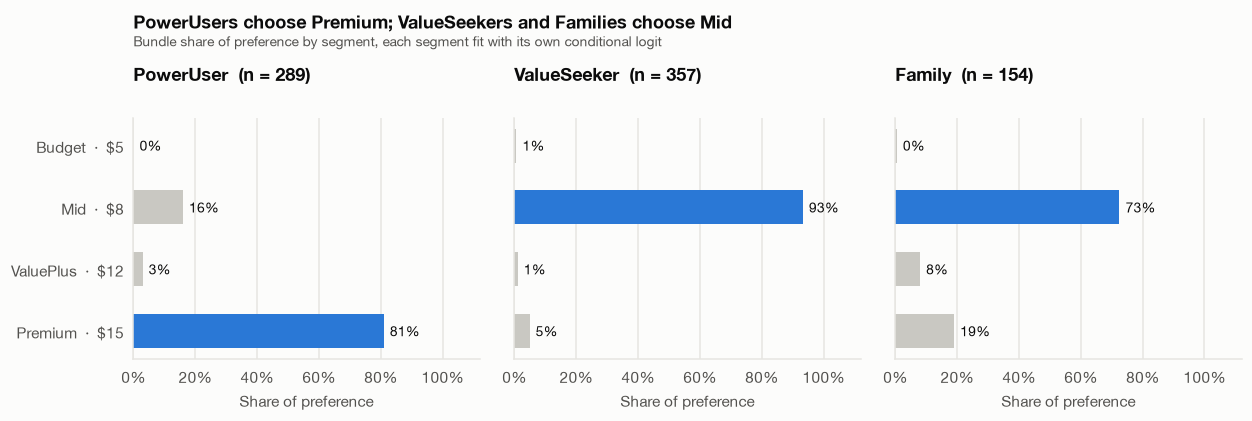

,Budget,Mid,ValuePlus,Premium
PowerUser,"0% [0%, 0%]","16% [12%, 22%]","3% [2%, 4%]","81% [75%, 86%]"
ValueSeeker,"1% [0%, 1%]","93% [91%, 95%]","1% [1%, 1%]","5% [3%, 7%]"
Family,"0% [0%, 1%]","73% [65%, 80%]","8% [6%, 10%]","19% [13%, 25%]"


In [22]:
# Shares of preference by segment, with the WTP that explains them
share_seg = pd.DataFrame(seg_shares)[segments]
order = ['Budget', 'Mid', 'ValuePlus', 'Premium']

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True, gridspec_kw={'wspace': 0.1})
for ax, seg in zip(axes, segments):
    vals = share_seg.loc[order, seg]
    leader = vals.idxmax()
    y = np.arange(len(order))[::-1]
    ax.barh(y, vals.values, height=0.55, color=[COLORS['blue'] if b == leader else COLORS['neutral'] for b in order])
    for yi, v in zip(y, vals.values):
        ax.text(v + 0.02, yi, f'{v:.0%}', va='center', fontsize=9, color=COLORS['text'])
    ax.set_xlim(0, 1.12)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel('Share of preference')
    ax.grid(axis='y', visible=False)
    ax.set_title(f'{seg}  (n = {seg_size[seg]})')
axes[0].set_yticks(
    np.arange(len(order))[::-1], [f"{b}  ·  ${df_bundles.set_index('bundle').loc[b, 'price_usd']}" for b in order]
)
fig.subplots_adjust(top=0.72)
fig.suptitle(
    'PowerUsers choose Premium; ValueSeekers and Families choose Mid',
    x=0.125,
    y=0.99,
    ha='left',
    fontsize=12,
    fontweight='bold',
)
fig.text(
    0.125,
    0.9,
    'Bundle share of preference by segment, each segment fit with its own conditional logit',
    ha='left',
    fontsize=9,
    color=COLORS['text_2'],
)
plt.show()

seg_share_ci = pd.DataFrame(
    {
        seg: [
            ci_str(*row, 'pct')
            for row in boot_summary(
                bundle_metrics(seg_fits[seg].params)[[f'share: {b}' for b in order]],
                boot_apply(bundle_metrics, boot_seg_pw[seg])[[f'share: {b}' for b in order]],
            )[['estimate', 'ci_95_low', 'ci_95_high']].to_numpy()
        ]
        for seg in segments
    },
    index=order,
).T
display(
    mark(
        seg_share_ci.style,
        [('PowerUser', 'Premium'), (['ValueSeeker', 'Family'], 'Mid')],
        title='Share of preference by segment: estimate [95% CI]',
    )
)

**Result:** **Segments differ significantly: PowerUsers choose Premium, while ValueSeekers and Families choose Mid.**
- **Test:** LR test χ² = 1,341, 12 df, p < 0.001.
- **PowerUsers (n = 289) choose Premium: 81% [75%, 86%].** They value large storage (\$5.65 [5.47, 5.85] for 200 → 1000 GB), Priority support (\$2.35 [2.12, 2.58]) and offline download (\$1.65 [1.44, 1.85]). Premium's extras exceed its \$7 premium by \$1.59 [1.20, 1.97] (p < 0.001).
- **ValueSeekers (n = 357) and Families (n = 154) choose Mid: 93% [91%, 95%] and 73% [65%, 80%].** For them Premium falls short of its price by \$2.18 and \$1.32 (both p < 0.001).
- **Families** value no ads (\$3.29 [2.98, 3.61]) and seats (\$0.74 [0.67, 0.81] each) more than the other segments, with CIs that do not overlap, and Mid already includes both.

**Implication:** among the four candidates, Mid fits ValueSeekers and Families (message: no ads, shared seats) and Premium fits PowerUsers (message: storage, Priority support, offline download). `segment_true` is a known label here. In practice segments would need to be inferred, e.g., from usage data or a latent-class model.

### Section summary
**Recommendation:** **The best of the four candidates is Mid at \$8, with Premium at \$15 as the upsell; Section 3 refines this.**
- **Mid leads on share:** 60.7% [57.5%, 64.2%] vs. 31.5% [28.3%, 34.7%] for Premium, p < 0.001 (1.5).
- **Premium matches Mid on expected revenue per subscriber:** the gap is not significant, p = 0.74 (1.5). PowerUsers choose Premium 81% [75%, 86%] of the time (1.7).
- **Mid's share is sensitive above \$8:** among the four candidates, at an interpolated \$9 it drops to 39.7% [36.6%, 42.9%] and Premium leads, p = 0.012 (1.6).
- **No ads is a key message:** worth \$2.35 [2.21, 2.49] per month on average and \$3.29 [2.98, 3.61] to Families (1.4, 1.7).
- **Budget and ValuePlus lose on value:** Budget gives up \$7.89 of features to save \$3, and ValuePlus charges \$4 more for \$1.44 of Priority support, both p < 0.001 (1.5).

**Limitations:** survey (stated) choices rather than real purchases; no "none" option, so shares are relative rather than total demand; logit assumes proportional substitution, so shifts between similar bundles are approximate; preferences are modeled per segment, not per person; CIs capture sampling uncertainty only, not survey bias. Validate with a live test before full launch.

## 2. Offer Impact (Causal Inference)

How much does the offer itself change upgrades and revenue, once targeting is accounted for? The offer data records upgrades to a new tier, but it does not define the offer, its dates or the tier users moved to, so these results are not specific to Premium Lite.

### Approach

**Question:** a raw comparison of offered and non-offered users is misleading, because the offer was **not randomly assigned** (2.1). If offered users were more likely to upgrade anyway, the raw gap mixes the offer's effect with who was targeted (*selection bias*).

**Data:** `observational_offer_adoption.csv`, one row per user.
- **Treatment:** `offer_received`.
- **Outcomes:** `upgraded_to_new_tier` (0/1) and `new_tier_monthly_revenue` (USD per user per month, \$0 for users who did not upgrade).
- **Covariates (6):** numeric `age`, `tenure_days`, `prior_spend_12m`, `sessions_30d`; categorical `region` and `device`, one-hot encoded (baselines APAC and Web).

**Method:**
1. **Propensity model (2.2).** A logistic regression predicts each user's chance of getting the offer from their covariates: the *propensity score* $e(x)$. A plain (not conditional) logit fits because each row is one user and the offer is one yes/no per user, with no choice sets.
2. **Inverse probability weighting, IPW (2.3, 2.4).** Each user is weighted by 1 / (chance of the treatment they actually got), where $T_i$ is `offer_received` and $y_i$ is the observed outcome:

$$
w_i = \frac{T_i}{e(x_i)} + \frac{1 - T_i}{1 - e(x_i)}
\qquad\Rightarrow\qquad
\widehat{\text{ATE}}_{\text{IPW}} = \frac{\sum_i w_i T_i y_i}{\sum_i w_i T_i} - \frac{\sum_i w_i (1 - T_i)\, y_i}{\sum_i w_i (1 - T_i)}
$$

   *Example:* an offered user with $e(x) = 0.25$ is rare among similar users (only 1 in 4 is offered), so they count for $1 / 0.25 = 4$ users: themselves plus the 3 similar users who were not offered. After weighting, both groups look like the full user base, so the gap in weighted outcomes estimates the **average treatment effect (ATE)**.
3. **AIPW as a robustness check (2.5).** A second estimator combines IPW with an outcome model.

**Uncertainty:** every effect gets a 95% CI and p-value from a bootstrap of the 50,000 users (1,000 resamples). Each resample refits the propensity and outcome models, so the CIs include the uncertainty of the estimated weights.

**Key concepts:**

| Term | Meaning | Why it matters here |
|---|---|---|
| Positivity (overlap) | Every kind of user has some chance of getting and of not getting the offer | Without it, IPW has no comparable users to weight (2.3) |
| Unconfoundedness | Given the covariates, who gets the offer is unrelated to how they would respond | It makes the estimate causal, and the data cannot prove it (2.5) |
| ATE vs. ATT | ATE: everyone vs. no one offered. ATT: effect among users actually offered | The ATE is reported here, so it is not the effect of any specific targeting rule |
| Odds ratio | Multiplier on the odds of getting the offer; 1 means no association | Shows which covariates the targeting leaned on (2.2) |

### 2.1 Data check: was the offer targeted?

**Purpose:** compare users who did and did not get the offer, because if it was targeted, a raw comparison mixes the effect of the offer with who received it.

In [23]:
TREAT = 'offer_received'
OUTCOMES = ['upgraded_to_new_tier', 'new_tier_monthly_revenue']
T2_NUM = ['age', 'tenure_days', 'prior_spend_12m', 'sessions_30d']
T2_CAT = ['region', 'device']

adopt = df_adopt.copy()
show_facts(
    {
        'Users': f'{len(adopt):,}',
        'Offer rate': f'{adopt[TREAT].mean():.1%}',
        'Missing values': f'{adopt.isna().sum().sum():,}',
        'Users in region NA': f"{adopt['region'].eq('NA').sum():,} ({adopt['region'].eq('NA').mean():.0%})",
    },
    'Offer data coverage',
)
assert set(adopt[TREAT].unique()) == {0, 1}
assert (
    adopt.loc[adopt['upgraded_to_new_tier'] == 0, 'new_tier_monthly_revenue'] == 0
).all()  # revenue only from upgraders

t = adopt[TREAT].to_numpy()
offered, not_offered = adopt[t == 1], adopt[t == 0]

# Numeric covariates and outcomes: group means and Welch t-test
targeting = pd.DataFrame(
    {
        'no_offer_mean': not_offered[T2_NUM + OUTCOMES].mean(),
        'offer_mean': offered[T2_NUM + OUTCOMES].mean(),
    }
)
targeting['difference'] = targeting['offer_mean'] - targeting['no_offer_mean']
targeting['p_value'] = [stats.ttest_ind(offered[c], not_offered[c], equal_var=False).pvalue for c in targeting.index]
display(
    mark(
        targeting.style.format(
            {'no_offer_mean': '{:.3f}', 'offer_mean': '{:.3f}', 'difference': '{:+.3f}', 'p_value': fmt_p}
        ),
        [
            (['tenure_days', 'prior_spend_12m', 'sessions_30d'], ['difference', 'p_value']),
            ('age', 'p_value'),
            (OUTCOMES, ['no_offer_mean', 'offer_mean']),
        ],
        title='Covariate and outcome means by offer status',
    )
)

# Categorical covariates: offer rate by level and chi-square test of independence
for c in T2_CAT:
    tab = pd.crosstab(adopt[c], adopt[TREAT])
    rate = adopt.groupby(c)[TREAT].mean().map('{:.1%}'.format).to_dict()
    p_text = fmt_p(stats.chi2_contingency(tab).pvalue).replace('<', '< ')
    print(f"Offer rate by {c}: {rate}  |  chi-square p: {p_text}")

# What upgraders pay: compared with the $5 to $15 bundle prices, because the data does not name the tier they chose
upgrade_revenue = adopt.loc[adopt['upgraded_to_new_tier'] == 1, 'new_tier_monthly_revenue']
show_facts(
    {
        'Users who upgraded': f'{len(upgrade_revenue):,}',
        'Minimum': f'${upgrade_revenue.min():.2f}',
        'Median': f'${upgrade_revenue.median():.2f}',
        'Mean': f'${upgrade_revenue.mean():.2f}',
        'Maximum': f'${upgrade_revenue.max():.2f}',
        'Share below $5': f'{(upgrade_revenue < 5).mean():.1%}',
        'Share above $15': f'{(upgrade_revenue > 15).mean():.1%}',
    },
    'Monthly revenue among users who upgraded (USD)',
)

,value
Users,"50,000"
Offer rate,44.3%
Missing values,0
Users in region NA,"22,360 (45%)"


,no_offer_mean,offer_mean,difference,p_value
age,41.535,41.627,+0.092,0.457
tenure_days,556.944,653.931,+96.987,<0.001
prior_spend_12m,5.224,5.711,+0.487,<0.001
sessions_30d,9.108,9.464,+0.357,<0.001
upgraded_to_new_tier,0.140,0.177,+0.037,<0.001
new_tier_monthly_revenue,1.460,1.876,+0.415,<0.001


Offer rate by region: {'APAC': '42.7%', 'EU': '43.2%', 'LATAM': '41.7%', 'NA': '46.3%'}  |  chi-square p: < 0.001
Offer rate by device: {'Android': '44.5%', 'Web': '42.1%', 'iOS': '45.2%'}  |  chi-square p: < 0.001


,value
Users who upgraded,"7,820"
Minimum,$1.39
Median,$9.12
Mean,$10.52
Maximum,$66.35
Share below $5,14.2%
Share above $15,17.8%


**Result:** **The offer was targeted, not random, so the raw outcome gap cannot be read as the offer's effect.**
- **Coverage:** 44.3% of 50,000 users got the offer, and no values are missing. Region code `NA` covers 22,360 users (45%). It is read here as North America, but the data dictionary does not define it, so the code needs confirming.
- **Numeric covariates:** offered users had longer tenure (+97 days), higher prior spend (+\$0.49) and more sessions (+0.36 in `sessions_30d`), all p < 0.001. Age did not differ (p = 0.46).
- **Categorical covariates:** offer rates also differed by region and device (chi-square p < 0.001).
- **Raw outcomes, offered vs. not offered:** upgrade rate 0.177 vs. 0.140, revenue \$1.88 vs. \$1.46 per user per month.
- **Upgrader revenue does not track tier prices:** it runs from \$1.39 to \$66.35 a month, with a median of \$9.12. Of the 7,820 upgraders, 14.2% pay below \$5 and 17.8% above \$15, outside the \$5 to \$15 bundle prices.

### 2.2 Propensity model

**Purpose:** estimate each user's chance of getting the offer, because IPW builds its weights from these scores.

Logistic regression of `offer_received` on the six covariates. Numeric covariates are standardized (z-scores) so their odds ratios are comparable: each is the change in the odds of getting the offer for **+1 standard deviation**. Categorical odds ratios are relative to the baseline level (APAC, Web). The predicted probabilities are the propensity scores, and the odds ratios show *who* was targeted.

`AUC` measures how well the covariates predict who got the offer: 0.5 is no better than chance, 1 is perfectly predictable. IPW needs an AUC between the two: targeting that depends on the covariates, so adjustment matters, but is not deterministic, so the groups still overlap.

In [24]:
t2_preprocess = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), T2_NUM),
        ('cat', OneHotEncoder(drop=['APAC', 'Web'], sparse_output=False), T2_CAT),
    ],
    verbose_feature_names_out=False,
).set_output(transform='pandas')

X_ps = sm.add_constant(t2_preprocess.fit_transform(adopt))
ps_model = sm.Logit(t, X_ps).fit(disp=False)
e_hat = ps_model.predict(X_ps).to_numpy()  # propensity score: P(offer | covariates)

ps_ci = np.exp(ps_model.conf_int())
odds_table = pd.DataFrame(
    {
        'odds_ratio': np.exp(ps_model.params),
        'ci_95_low': ps_ci[0],
        'ci_95_high': ps_ci[1],
        'p_value': ps_model.pvalues,
    }
).drop(index='const')
odds_table.index = [f'{c} (+1 SD)' if c in T2_NUM else c for c in odds_table.index]
display(
    mark(
        odds_table.sort_values('odds_ratio', ascending=False).style.format(
            {'odds_ratio': '{:.3f}', 'ci_95_low': '{:.3f}', 'ci_95_high': '{:.3f}', 'p_value': fmt_p}
        ),
        [
            ('tenure_days (+1 SD)', ['odds_ratio', 'ci_95_low', 'ci_95_high', 'p_value']),
            (
                ['region_NA', 'device_iOS', 'device_Android', 'prior_spend_12m (+1 SD)', 'sessions_30d (+1 SD)'],
                ['odds_ratio', 'p_value'],
            ),
            (['region_EU', 'age (+1 SD)', 'region_LATAM'], 'p_value'),
        ],
        title='Propensity model: odds ratios for receiving the offer',
    )
)
show_facts({'AUC': f'{roc_auc_score(t, e_hat):.3f}'}, 'Propensity model discrimination (CI in 2.5)')

,odds_ratio,ci_95_low,ci_95_high,p_value
tenure_days (+1 SD),1.329,1.305,1.353,<0.001
region_NA,1.162,1.107,1.219,<0.001
device_iOS,1.128,1.070,1.188,<0.001
device_Android,1.101,1.046,1.159,<0.001
prior_spend_12m (+1 SD),1.075,1.056,1.095,<0.001
sessions_30d (+1 SD),1.074,1.055,1.093,<0.001
region_EU,1.022,0.969,1.078,0.429
age (+1 SD),1.006,0.989,1.025,0.484
region_LATAM,0.955,0.890,1.024,0.195


,value
AUC,0.589


**Result:** **Targeting leaned mainly on tenure, and overall the covariates predict the offer only weakly (AUC 0.589).**
- **Largest driver:** tenure, odds ratio 1.329 [1.305, 1.353] per +1 SD, p < 0.001.
- **Smaller drivers, all p < 0.001:** region NA vs. APAC (1.16), iOS and Android vs. Web (1.13, 1.10), prior spend and sessions (1.07 each per +1 SD).
- **No detectable association:** age, EU and LATAM (p = 0.20 to 0.48).
- **For IPW:** the AUC is above chance, so adjustment matters, and far from 1, so the groups can still overlap (2.3).

### 2.3 Overlap

**Purpose:** confirm that offered and non-offered users are comparable enough for IPW to work.

IPW can only compare like with like if, for every kind of user, some were offered and some were not. Scores near 0 or 1 would mean some users were almost always or almost never offered: no comparable user exists in the other group, and their weights explode. The rule of thumb is to worry about scores outside 0.1 to 0.9.

The **effective sample size** (ESS) is also checked, because a few very large weights can leave far less information than the user count suggests. It is how many equally weighted users the weighted group is worth, computed within each group: $\text{ESS} = \big(\sum_i w_i\big)^2 / \sum_i w_i^2$. An ESS close to the actual group size means the weights are stable.

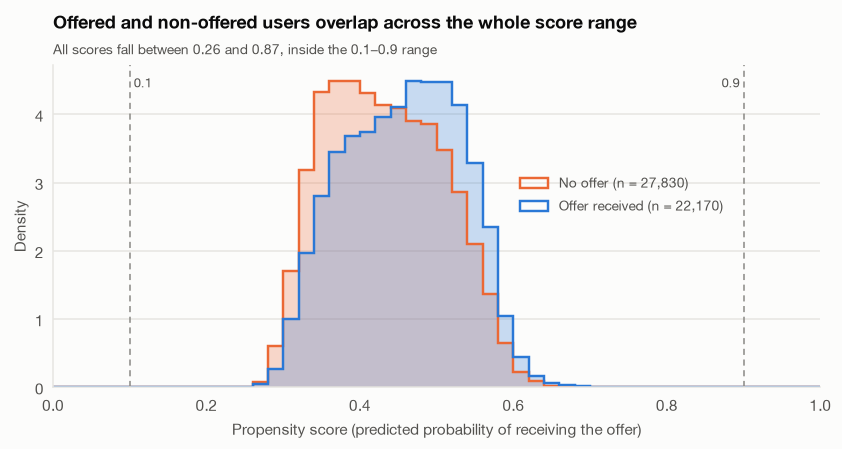

,min,p1,p25,median,p75,p99,max
no_offer,0.263,0.296,0.372,0.429,0.491,0.593,0.872
offer,0.263,0.306,0.396,0.460,0.516,0.609,0.839


,value
Lowest propensity score,0.26
Highest propensity score,0.87
Largest weight,7.79
"Effective sample, offered","21,508 of 22,170"
"Effective sample, not offered","27,264 of 27,830"


In [25]:
w_ipw = ipw_weights(t, e_hat)

fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.linspace(0, 1, 51)
for grp, color, label in [(0, COLORS['orange'], 'No offer'), (1, COLORS['blue'], 'Offer received')]:
    ax.hist(e_hat[t == grp], bins=bins, density=True, color=color, alpha=0.25, lw=0)
    ax.hist(
        e_hat[t == grp],
        bins=bins,
        density=True,
        histtype='step',
        color=color,
        lw=1.6,
        label=f'{label} (n = {(t == grp).sum():,})',
    )
for x in (0.1, 0.9):
    ax.axvline(x, color=COLORS['muted'], lw=1, ls=(0, (4, 3)))
ax.text(0.1, ax.get_ylim()[1] * 0.97, ' 0.1', va='top', fontsize=8.5, color=COLORS['text_2'])
ax.text(0.9, ax.get_ylim()[1] * 0.97, '0.9 ', va='top', ha='right', fontsize=8.5, color=COLORS['text_2'])
ax.set_xlim(0, 1)
ax.set_xlabel('Propensity score (predicted probability of receiving the offer)')
ax.set_ylabel('Density')
ax.grid(axis='x', visible=False)
ax.legend(loc='center right', bbox_to_anchor=(0.89, 0.6))
ax.set_title('Offered and non-offered users overlap across the whole score range')
subtitle(ax, f'All scores fall between {e_hat.min():.2f} and {e_hat.max():.2f}, inside the 0.1–0.9 range')
plt.show()

overlap = pd.DataFrame(
    {
        label: pd.Series(e_hat[t == grp]).quantile([0, 0.01, 0.25, 0.5, 0.75, 0.99, 1]).to_numpy()
        for grp, label in [(0, 'no_offer'), (1, 'offer')]
    },
    index=['min', 'p1', 'p25', 'median', 'p75', 'p99', 'max'],
)
display(
    mark(
        overlap.T.style.format('{:.3f}'),
        [(None, ['min', 'p1', 'p99', 'max'])],
        title='Propensity score distribution by offer status',
    )
)

ess = lambda w: w.sum() ** 2 / (w**2).sum()
show_facts(
    {
        'Lowest propensity score': f'{e_hat.min():.2f}',
        'Highest propensity score': f'{e_hat.max():.2f}',
        'Largest weight': f'{w_ipw.max():.2f}',
        'Effective sample, offered': f'{ess(w_ipw[t == 1]):,.0f} of {(t == 1).sum():,}',
        'Effective sample, not offered': f'{ess(w_ipw[t == 0]):,.0f} of {(t == 0).sum():,}',
    },
    'Overlap and weight diagnostics',
)

**Result:** **Overlap is adequate: no user falls outside 0.1 to 0.9, so no weight trimming is needed.**
- **Score range:** 0.263 to 0.872 for non-offered users and 0.263 to 0.839 for offered users.
- **p1 to p99:** 0.296 to 0.593 for non-offered users and 0.306 to 0.609 for offered users.
- **Weights:** the largest is 7.79, and ESS stays close to group size: 21,508 of 22,170 offered and 27,264 of 27,830 not offered.

### 2.4 Balance diagnostics

**Purpose:** check that IPW made the two groups comparable, because the effect estimate is only credible if the targeting imbalance is removed.

The **standardized mean difference (SMD)** measures how different the two groups are on a covariate, in standard deviations:

$$
\text{SMD} = \frac{\bar{x}_{\text{offer}} - \bar{x}_{\text{no offer}}}{\sqrt{\big(s^2_{\text{offer}} + s^2_{\text{no offer}}\big) / 2}}
$$

The usual threshold is $|\text{SMD}| < 0.1$. Before weighting, SMD shows the targeting imbalance. After IPW (weighted means, same pooled SD), it should be near 0 for every covariate. Categorical covariates are checked level by level (share of users in each region and device).

*Why no p-values here:* balance is a property of this sample after weighting, not a claim about a wider population, and with 50,000 users even trivial differences would be significant. SMD with a fixed threshold is the standard check.

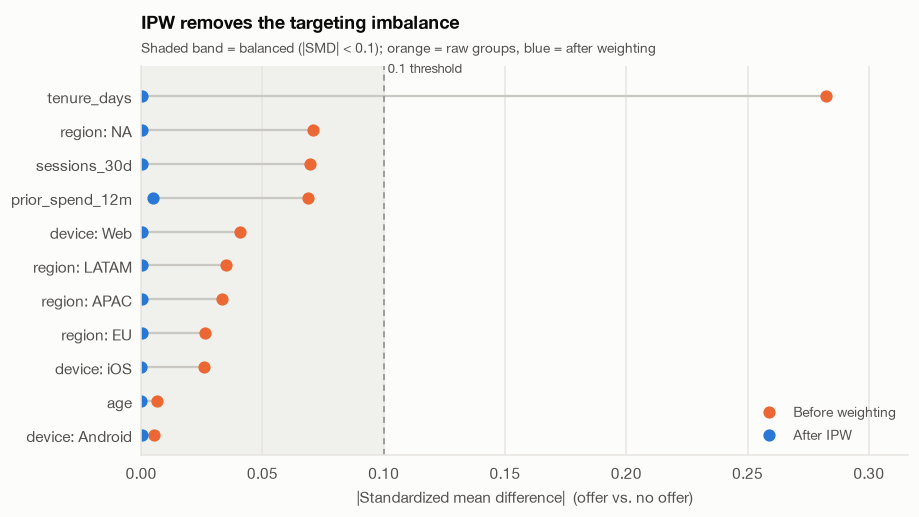

,smd_before,smd_after_ipw,balanced_after
tenure_days,+0.282,-0.000,True
region: NA,+0.071,+0.000,True
sessions_30d,+0.070,+0.000,True
prior_spend_12m,+0.069,-0.005,True
device: Web,-0.041,+0.001,True
region: LATAM,-0.035,-0.000,True
region: APAC,-0.033,-0.001,True
region: EU,-0.026,+0.000,True
device: iOS,+0.026,-0.000,True
age,+0.007,-0.000,True


In [26]:
# Covariates on their original scale; every categorical level as its own 0/1 column
bal_X = pd.concat([adopt[T2_NUM], pd.get_dummies(adopt[T2_CAT], prefix_sep=': ', dtype=float)], axis=1)


def smd(X, t, w=None):
    """Standardized mean difference per column; weighted means if w is given, unweighted pooled SD."""
    w = np.ones(len(t)) if w is None else w
    m1 = np.average(X[t == 1], axis=0, weights=w[t == 1])
    m0 = np.average(X[t == 0], axis=0, weights=w[t == 0])
    sd = np.sqrt((X[t == 1].var(axis=0, ddof=1) + X[t == 0].var(axis=0, ddof=1)) / 2)
    return (m1 - m0) / sd


balance = pd.DataFrame(
    {
        'smd_before': smd(bal_X.to_numpy(), t),
        'smd_after_ipw': smd(bal_X.to_numpy(), t, w_ipw),
    },
    index=bal_X.columns,
)
balance['balanced_after'] = balance['smd_after_ipw'].abs() < 0.1

plot_bal = balance.reindex(balance['smd_before'].abs().sort_values().index)
fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(plot_bal))
ax.axvspan(0, 0.1, color=COLORS['grid'], alpha=0.5, lw=0)
ax.hlines(y, plot_bal['smd_after_ipw'].abs(), plot_bal['smd_before'].abs(), color=COLORS['neutral'], lw=1.5)
ax.plot(plot_bal['smd_before'].abs(), y, 'o', color=COLORS['orange'], ms=7, label='Before weighting')
ax.plot(plot_bal['smd_after_ipw'].abs(), y, 'o', color=COLORS['blue'], ms=7, label='After IPW')
ax.axvline(0.1, color=COLORS['muted'], lw=1, ls=(0, (4, 3)))
ax.text(0.1, len(plot_bal) - 0.4, ' 0.1 threshold', fontsize=8.5, color=COLORS['text_2'], va='bottom')
ax.set_yticks(y, plot_bal.index)
ax.set_xlim(0, max(0.12, plot_bal['smd_before'].abs().max() * 1.12))
ax.set_ylim(-0.6, len(plot_bal) - 0.1)
ax.set_xlabel('|Standardized mean difference|  (offer vs. no offer)')
ax.grid(axis='y', visible=False)
ax.legend(loc='lower right')
ax.set_title('IPW removes the targeting imbalance')
subtitle(ax, 'Shaded band = balanced (|SMD| < 0.1); orange = raw groups, blue = after weighting')
plt.show()

display(
    mark(
        balance.sort_values('smd_before', key=abs, ascending=False).style.format(
            {'smd_before': '{:+.3f}', 'smd_after_ipw': '{:+.3f}'}
        ),
        [
            (['tenure_days', 'region: NA', 'sessions_30d', 'prior_spend_12m'], 'smd_before'),
            ('prior_spend_12m', 'smd_after_ipw'),
        ],
        title='Covariate balance before and after IPW (standardized mean differences)',
    )
)

**Result:** **Balance improved after IPW: every covariate is now well inside the 0.1 threshold.**
- **Before weighting:** tenure is clearly imbalanced (SMD +0.28, above 0.1). Region NA, sessions and prior spend show smaller gaps (+0.07 each).
- **After IPW:** the largest remaining gap is prior spend (-0.005), so the weighted groups match closely on all six measured covariates.

### 2.5 Effect of the offer: naive vs. IPW vs. AIPW

**Purpose:** estimate the effect of the offer, and check that the answer does not depend on one model.

#### How AIPW works

IPW relies entirely on the propensity model: if that model is wrong, so are the weights and the effect. **AIPW (augmented IPW)** adds a second route to the same answer, an outcome model.

For each outcome, two regressions on the six covariates are fit, one on offered users and one on non-offered users: logistic for upgrade, linear for revenue. Applied to every user, they predict the outcome with the offer, $m_1(x_i)$, and without it, $m_0(x_i)$. Each user is observed in only one situation, and the model fills in the other.

AIPW then adds back each user's prediction error, weighted as in IPW. $T_i$ acts as a switch, so only the observed side is corrected:

$$
\psi_i \;=\; \underbrace{\left[\, m_1(x_i) + \frac{T_i\,\big(y_i - m_1(x_i)\big)}{e(x_i)} \right]}_{\text{outcome with offer}}
\;-\; \underbrace{\left[\, m_0(x_i) + \frac{(1 - T_i)\,\big(y_i - m_0(x_i)\big)}{1 - e(x_i)} \right]}_{\text{outcome without offer}}
$$

$$
\widehat{\text{ATE}}_{\text{AIPW}} \;=\; \frac{1}{n}\sum_{i=1}^{n} \psi_i
$$

**Why it is called doubly robust:** if the outcome model is right, prediction errors average to zero and the correction does nothing, so a wrong propensity model does no harm. If the propensity model is right, the weighted correction repairs any bias in the outcome model. The estimate is consistent if **either** model is correct. So if IPW and AIPW agree, the result does not hinge on the propensity model alone. Both still assume no unmeasured confounding.

The table below shows the inputs for two users, and the note after it follows User A through the calculation.

In [27]:
X_np = X_ps.to_numpy()
sigmoid = lambda z: 1 / (1 + np.exp(-z))


def fit_logit(X, y):
    """Newton-Raphson logistic regression (same estimates as statsmodels Logit, fast enough to bootstrap)."""
    b = np.zeros(X.shape[1])
    for _ in range(50):
        p = sigmoid(X @ b)
        step = np.linalg.solve((X * (p * (1 - p))[:, None]).T @ X, X.T @ (y - p))
        b += step
        if np.abs(step).max() < 1e-10:
            break
    return b


def outcome_predictions(X, t, y, binary):
    """m1, m0: each user's predicted outcome with and without the offer (one model per group)."""
    if binary:
        fit, link = fit_logit, sigmoid
    else:
        fit, link = (lambda X, y: np.linalg.lstsq(X, y, rcond=None)[0]), (lambda z: z)
    return link(X @ fit(X[t == 1], y[t == 1])), link(X @ fit(X[t == 0], y[t == 0]))


assert np.allclose(fit_logit(X_np, t), ps_model.params.to_numpy(), atol=1e-6)

# Worked example: one offered user who upgraded (low score) and one non-offered user (high score)
y_up = adopt['upgraded_to_new_tier'].to_numpy()
m1_up, m0_up = outcome_predictions(X_np, t, y_up, binary=True)
psi1 = m1_up + t * (y_up - m1_up) / e_hat
psi0 = m0_up + (1 - t) * (y_up - m0_up) / (1 - e_hat)
ex = [
    np.where((t == 1) & (y_up == 1))[0][np.abs(e_hat[(t == 1) & (y_up == 1)] - 0.30).argmin()],
    np.where((t == 0) & (y_up == 0))[0][np.abs(e_hat[(t == 0) & (y_up == 0)] - 0.80).argmin()],
]
example = adopt.iloc[ex][T2_NUM + T2_CAT + [TREAT, 'upgraded_to_new_tier']].assign(
    propensity_e=e_hat[ex],
    ipw_weight=w_ipw[ex],
    m1_with_offer=m1_up[ex],
    m0_without_offer=m0_up[ex],
    aipw_with_offer=psi1[ex],
    aipw_without_offer=psi0[ex],
    aipw_score=psi1[ex] - psi0[ex],
)
display(
    mark(
        example.T.rename(columns=dict(zip(example.index, ['User A (offered)', 'User B (not offered)']))).style.format(
            precision=3
        ),
        [
            (
                [
                    'propensity_e',
                    'ipw_weight',
                    'm1_with_offer',
                    'm0_without_offer',
                    'aipw_with_offer',
                    'aipw_without_offer',
                    'aipw_score',
                ],
                'User A (offered)',
            ),
            (['age', 'tenure_days'], 'User A (offered)'),
        ],
        title='Worked example: IPW and AIPW inputs for two users',
    )
)

,User A (offered),User B (not offered)
age,65,33
tenure_days,40,1137
prior_spend_12m,4.690,93.440
sessions_30d,4,16
region,LATAM,NA
device,iOS,Android
offer_received,1,0
upgraded_to_new_tier,1,0
propensity_e,0.300,0.784
ipw_weight,3.329,4.625


**Worked example:** **User A shows how AIPW corrects a prediction with the observed outcome (upgrade outcome).**
- **Weight:** User A (age 65, 40 days of tenure) got the offer despite a low score, $e(x_A) = 0.30$, so IPW counts them as $1 / 0.30 = 3.33$ users.
- **Observed side:** they upgraded ($y_A = 1$) although the model predicted only $m_1(x_A) = 0.097$. AIPW starts from that prediction and adds the weighted error: $0.097 + (1 - 0.097) \times 3.33 \approx 3.10$.
- **Unobserved side:** their outcome without the offer is never seen, so AIPW uses the prediction $m_0(x_A) = 0.079$, giving $\psi_A \approx 3.10 - 0.079 = 3.02$.
- **Reading the score:** individual AIPW scores can fall outside 0 to 1, and they are not predictions for one person. Only their **average over all 50,000 users** is the effect estimate.

#### Estimates with 95% CIs

IPW is the main estimate because it adjusts for targeting, and AIPW is the check because it does not rely on the propensity model alone. *Naive - IPW* is the targeting gap, which equals selection bias if every user responds alike, and *AIPW - IPW* should be close to 0. Relative lift is $\widehat{\text{ATE}}_{\text{IPW}} \,/\, \bar{y}_{\text{without offer}}$. The two outcome levels have no p-value because they are not differences.

In [28]:
Y = {'upgrade': y_up, 'revenue': adopt['new_tier_monthly_revenue'].to_numpy()}


def offer_effects(X, t, Y):
    """Naive, IPW and AIPW effects for each outcome; refits the propensity and outcome models on (X, t, Y)."""
    e = sigmoid(X @ fit_logit(X, t))
    w = ipw_weights(t, e)
    out = {'AUC': roc_auc_score(t, e)}
    for name, y in Y.items():
        mu1, mu0 = np.average(y[t == 1], weights=w[t == 1]), np.average(y[t == 0], weights=w[t == 0])
        m1, m0 = outcome_predictions(X, t, y, binary=(name == 'upgrade'))
        aipw = np.mean(m1 + t * (y - m1) / e) - np.mean(m0 + (1 - t) * (y - m0) / (1 - e))
        naive = y[t == 1].mean() - y[t == 0].mean()
        out |= {
            f'{name}: without offer': mu0,
            f'{name}: with offer': mu1,
            f'{name}: naive difference': naive,
            f'{name}: IPW ATE': mu1 - mu0,
            f'{name}: AIPW ATE': aipw,
            f'{name}: naive - IPW (targeting gap)': naive - (mu1 - mu0),
            f'{name}: AIPW - IPW': aipw - (mu1 - mu0),
            f'{name}: relative lift': (mu1 - mu0) / mu0,
        }
    return pd.Series(out)


t2_est = offer_effects(X_np, t, Y)
OFFER_BOOT = 1000
offer_rng = np.random.default_rng(42)
t2_draws = pd.DataFrame(
    [
        offer_effects(X_np[i], t[i], {k: v[i] for k, v in Y.items()})
        for i in (offer_rng.integers(0, len(t), len(t)) for _ in range(OFFER_BOOT))
    ]
)
t2_ci = boot_summary(t2_est, t2_draws)

fmt_unit = {'upgrade': lambda v: f'{100 * v:+.2f} pts', 'revenue': lambda v: f'-${-v:.3f}' if v < 0 else f'${v:.3f}'}
rows = [k.split(': ')[1] for k in t2_est.index if k.startswith('upgrade: ')]
effects_table = pd.DataFrame(index=rows)
for name, col in [('upgrade', 'Upgrade rate'), ('revenue', 'Revenue (USD / user / month)')]:
    f = fmt_unit[name]
    r = t2_ci.loc[[f'{name}: {m}' for m in rows]]
    effects_table[col] = [
        (
            f'{v:.1%} [{lo:.1%}, {hi:.1%}]'
            if m == 'relative lift' or (name == 'upgrade' and m in ('without offer', 'with offer'))
            else f'{f(v)} [{f(lo)}, {f(hi)}]'
        )
        for m, v, lo, hi in zip(rows, r['estimate'], r['ci_95_low'], r['ci_95_high'])
    ]
    effects_table[f'p ({name})'] = [
        '' if m in ('without offer', 'with offer') else fmt_p(p)  # levels, not differences
        for m, p in zip(rows, r['p_value'])
    ]
display(
    mark(
        effects_table.style,
        [
            ('IPW ATE', None),
            (['naive difference', 'AIPW ATE'], ['Upgrade rate', 'Revenue (USD / user / month)']),
            (['without offer', 'with offer'], 'Upgrade rate'),
            (['naive - IPW (targeting gap)', 'AIPW - IPW'], None),
            ('relative lift', ['Upgrade rate', 'Revenue (USD / user / month)']),
        ],
        title='Effect of the offer: naive, IPW and AIPW estimates',
    )
)
a = t2_ci.loc['AUC']
show_facts(
    {'AUC': f"{a['estimate']:.3f} [{a['ci_95_low']:.3f}, {a['ci_95_high']:.3f}]"},
    'Propensity model discrimination: estimate [95% CI]',
)

# Scaled to a campaign of 10,000 offers (IPW ATE x 10,000)
scaled = {}
for name, unit in [('upgrade', 'Extra upgrades'), ('revenue', 'Extra monthly revenue (USD)')]:
    r = t2_ci.loc[f'{name}: IPW ATE'] * 10_000
    scaled[f'{unit}, per 10,000 offers'] = f"{r['estimate']:,.0f} [{r['ci_95_low']:,.0f}, {r['ci_95_high']:,.0f}]"
show_facts(scaled, 'IPW effect at campaign scale: estimate [95% CI]')

,Upgrade rate,p (upgrade),Revenue (USD / user / month),p (revenue)
without offer,"14.8% [14.3%, 15.2%]",,"$1.545 [$1.491, $1.598]",
with offer,"16.8% [16.3%, 17.3%]",,"$1.783 [$1.721, $1.845]",
naive difference,"+3.68 pts [+3.11 pts, +4.30 pts]",<0.001,"$0.415 [$0.335, $0.495]",<0.001
IPW ATE,"+2.02 pts [+1.46 pts, +2.64 pts]",<0.001,"$0.238 [$0.153, $0.321]",<0.001
AIPW ATE,"+2.05 pts [+1.49 pts, +2.66 pts]",<0.001,"$0.239 [$0.154, $0.322]",<0.001
naive - IPW (targeting gap),"+1.66 pts [+1.52 pts, +1.80 pts]",<0.001,"$0.177 [$0.160, $0.197]",<0.001
AIPW - IPW,"+0.03 pts [+0.00 pts, +0.06 pts]",0.065,"$0.001 [-$0.000, $0.004]",0.364
relative lift,"13.7% [9.8%, 18.2%]",<0.001,"15.4% [9.7%, 21.1%]",<0.001


,value
AUC,"0.589 [0.584, 0.594]"


,value
"Extra upgrades, per 10,000 offers","202 [146, 264]"
"Extra monthly revenue (USD), per 10,000 offers","2,382 [1,528, 3,210]"


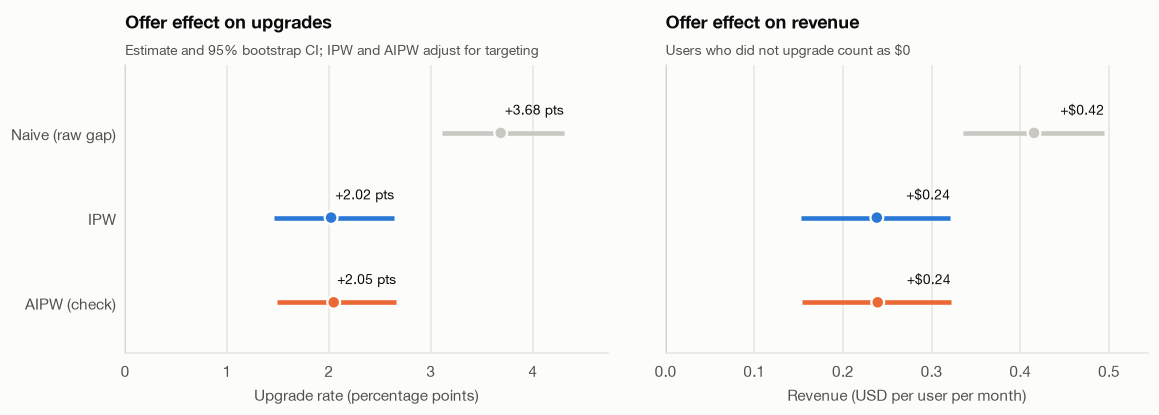

In [29]:
# Compare naive, IPW and AIPW estimates side by side
methods = ['naive difference', 'IPW ATE', 'AIPW ATE']
method_labels = ['Naive (raw gap)', 'IPW', 'AIPW (check)']
method_colors = [COLORS['neutral'], COLORS['blue'], COLORS['orange']]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True, gridspec_kw={'wspace': 0.12})
panels = [
    ('upgrade', 'Upgrade rate (percentage points)', lambda v: f'+{v * 100:.2f} pts', 100),
    ('revenue', 'Revenue (USD per user per month)', lambda v: f'+${v:.2f}', 1),
]
for ax, (name, xlabel, fmt, scale) in zip(axes, panels):
    r = t2_ci.loc[[f'{name}: {m}' for m in methods]]
    y = np.arange(len(methods))[::-1]
    ax.hlines(y, r['ci_95_low'] * scale, r['ci_95_high'] * scale, color=method_colors, lw=3)
    ax.scatter(r['estimate'] * scale, y, color=method_colors, s=70, zorder=3, edgecolor=COLORS['surface'], lw=1.5)
    for yi, v, hi in zip(y, r['estimate'], r['ci_95_high']):
        ax.text(hi * scale, yi + 0.18, f'  {fmt(v)}', va='bottom', ha='right', fontsize=9, color=COLORS['text'])
    ax.axvline(0, color=COLORS['muted'], lw=1)
    ax.set_xlim(0, r['ci_95_high'].max() * scale * 1.1)
    ax.set_ylim(-0.6, len(methods) - 0.2)
    ax.set_xlabel(xlabel)
    ax.grid(axis='y', visible=False)
    ax.set_title(f"Offer effect on {'upgrades' if name == 'upgrade' else 'revenue'}")
axes[0].set_yticks(np.arange(len(methods))[::-1], method_labels)
subtitle(axes[0], 'Estimate and 95% bootstrap CI; IPW and AIPW adjust for targeting')
subtitle(axes[1], 'Users who did not upgrade count as $0')
plt.show()

**Result:** **If the six covariates explain targeting, the offer adds an estimated +2.02 percentage points to the upgrade rate and +\$0.24 per user per month in revenue, about half of the raw gap. The offer was not randomized.**
- **IPW effect:** the upgrade rate would be 16.8% if every user were offered vs. 14.8% if no one were: **+2.02 percentage points [1.46, 2.64]**, p < 0.001, a 13.7% [9.8%, 18.2%] relative lift. Revenue rises by **+\$0.24 [0.15, 0.32] per user per month**, p < 0.001, a 15.4% relative lift.
- **The naive comparison overstates the effect:** +3.68 percentage points and +\$0.415 per user per month. The targeting gap (naive - IPW) is 1.66 percentage points [1.52, 1.80] and \$0.18 [0.16, 0.20] per user per month, both p < 0.001: the offer went to users who were more likely to upgrade anyway.
- **AIPW agrees with IPW:** +2.05 percentage points and +\$0.24 per user per month. The gap to IPW is 0.03 percentage points (p = 0.07) and \$0.001 (p = 0.36), so the result does not depend on the propensity model alone.
- **At campaign scale:** 10,000 offers to users like the full base imply about **202 [146, 264] extra upgrades** and **\$2,382 [1,528, 3,210] of extra revenue per month**. Offer cost is unknown, so the break-even rule is: an offer pays back if its cost per user is below \$0.24 × the months the extra revenue lasts.

#### Key assumption: no unmeasured confounding

IPW and AIPW remove bias only from the **six measured covariates**. The estimate is causal if the offer was assigned using only information in this dataset, such as CRM rules based on tenure or spend. If offers were also hand-picked by account managers or scored with data not available here, part of the +2.02 percentage points could still be selection bias, and no statistic computed from this data can rule that out.

To see how much this could matter, the code recomputes the IPW upgrade effect with one covariate removed at a time, as if it had not been recorded. This cannot detect a missing confounder, but it shows how sensitive the result is to what is measured. `bias_vs_full` is the change from the full model's +2.02 percentage points.

In [30]:
# Pretend one covariate was never recorded: refit the propensity model without it and recompute the IPW upgrade effect
def ipw_upgrade_without(cov):
    """IPW upgrade effect after dropping one covariate from the propensity model."""
    keep = [j for j, c in enumerate(X_ps.columns) if not c.startswith(cov)]
    e = sigmoid(X_np[:, keep] @ fit_logit(X_np[:, keep], t))
    w = ipw_weights(t, e)
    return np.average(y_up[t == 1], weights=w[t == 1]) - np.average(y_up[t == 0], weights=w[t == 0])


full = t2_est['upgrade: IPW ATE']
omitted = pd.DataFrame({'ipw_upgrade_effect': {c: ipw_upgrade_without(c) for c in T2_NUM + T2_CAT}})
omitted['bias_vs_full'] = omitted['ipw_upgrade_effect'] - full
omitted = omitted.sort_values('bias_vs_full', ascending=False)
print(
    f"All six covariates: {100 * full:.2f} pts  |  no adjustment (naive): {100 * t2_est['upgrade: naive difference']:.2f} pts"
)
display(
    mark(
        omitted.mul(100).style.format('{:+.2f} pts'),
        [('tenure_days', None), ('sessions_30d', None)],
        title='IPW upgrade effect when one covariate is left out of the propensity model',
    )
)

All six covariates: 2.02 pts  |  no adjustment (naive): 3.68 pts


,ipw_upgrade_effect,bias_vs_full
tenure_days,+3.40 pts,+1.38 pts
sessions_30d,+2.16 pts,+0.14 pts
prior_spend_12m,+2.15 pts,+0.13 pts
device,+2.06 pts,+0.04 pts
region,+2.03 pts,+0.01 pts
age,+2.02 pts,+0.00 pts


**Result:** **Leaving out tenure alone would raise the estimate from +2.02 to +3.40 percentage points, close to the naive +3.68.**
- **Tenure:** omitting it adds +1.38 percentage points, which is large relative to the +2.02 effect.
- **Other covariates:** omitting any one moves the estimate by at most 0.14 percentage points.
- **Remaining risk:** tenure is measured and adjusted for here. An *unrecorded* factor of similar strength would bias the estimate, and only the targeting rule or a randomized holdout can rule that out.

**Next steps:** confirm the targeting rule with the campaign team, and run a **randomized holdout** in the next campaign (randomly withhold the offer from part of the eligible users) to measure the effect without this assumption.

### Section summary

**Recommendation:** **Refine the offer's targeting, do not scale it yet: first confirm the lift with a randomized holdout and a cost check.** Offer cost and the targeting rule are unknown, and the ATE compares everyone vs. no one, not a specific rollout.

- **Effect:** if there is no unmeasured confounding, the offer causes a real but modest lift. The upgrade rate moves from 14.8% to 16.8%, **+2.02 percentage points [1.46, 2.64]**, and revenue rises **+\$0.24 [0.15, 0.32] per user per month**, both p < 0.001 (2.5).
- **Targeted, not random:** targeting leaned on tenure (odds ratio 1.329 per +1 SD, p < 0.001), though the covariates predict the offer only weakly (AUC 0.589) (2.1, 2.2).
- **Adjustment checks pass:** overlap is adequate, with scores from 0.26 to 0.87 and ESS close to group size, and balance improved after IPW, with a largest remaining gap of 0.005 SMD (2.3, 2.4).
- **AIPW agrees:** +2.05 percentage points and +\$0.24 per user per month (2.5).
- **Do not use the naive numbers:** the raw gap (+3.68 percentage points, +\$0.415 per user per month) includes the targeting gap and would overstate the campaign's return (2.5).
- **Business use:** about 202 extra upgrades and \$2,382 of extra revenue per month per 10,000 offers. An offer pays back if its cost per user is below \$0.24 × the expected months of extra revenue (2.5).

**Limitations:**
- The causal reading assumes the offer was targeted only on the six measured covariates. If it also used information not recorded here, part of the lift could be selection bias (2.5).
- The covariates must be measured before the offer. The data does not confirm this. `sessions_30d` is the most exposed, and leaving it out gives +2.16 percentage points (2.5).
- Revenue is a single monthly snapshot, so how long the extra revenue lasts is unknown.
- The ATE is an average and does not show which users respond most. Estimating the effect by segment is the next step for refining the targeting.

## 3. Positioning and Whitespace (Multidimensional Scaling, MDS)

How do the bundles relate to each other, which two compete most directly, and is there an open position worth filling?

### Approach

The analysis maps the four bundles from their specifications, finds the closest pair, then searches every tested configuration for an open position.

**Feature set (6):** price, $\log(\text{storage})$, family seats, Priority support, no ads, offline download. Storage is logged because Section 1 showed diminishing returns (1.2), so 50 → 200 GB counts as a similar step to 200 → 1000 GB, and it enters **once**.

**Two dissimilarity matrices, each called $D$, are built and compared in 3.5:**

- **Gower distance.** Each feature contributes a 0–1 difference and the distance is their average, so numeric and yes/no features carry equal weight and no feature needs standardizing:

$$
d^{\text{Gower}}_{ij} = \frac{1}{p}\sum_{k=1}^{p} g_{ijk},
\qquad
g_{ijk} =
\begin{cases}
|x_{ik} - x_{jk}| \,/\, R_k & \text{numeric feature with range } R_k \\
0 \text{ if the two bundles match, } 1 \text{ if not} & \text{categorical feature}
\end{cases}
$$

  A value of 0.20 reads directly as "20% of the maximum possible difference". It is built for a mix of numeric and categorical features like these.
- **Euclidean distance on standardized features.** With $z_{ik}$ the z-score of feature $k$ for bundle $i$, and yes/no features coded 0/1:

$$
d^{\text{Euclid}}_{ij} = \sqrt{\sum_{k=1}^{p} \big(z_{ik} - z_{jk}\big)^2}
$$

**MDS** places the bundles on a map so that distances on the map match $D$ as closely as possible. Fit is measured by Stress-1, where $\delta_{ij}$ is the input dissimilarity and $d_{ij}$ is the distance on the map:

$$
\text{Stress-1} = \sqrt{\frac{\sum_{i<j} \big(\delta_{ij} - d_{ij}\big)^2}{\sum_{i<j} d_{ij}^2}}
$$

| Term | Meaning | Why it matters here |
|---|---|---|
| Classical MDS | Eigenvalue solution that splits $D$ into ranked dimensions | Shows how much variation each dimension holds, and starts the fit (3.2) |
| Metric MDS | Iterative fit that moves points until map distances match $D$ | Produces the final map coordinates (3.2) |
| Stress-1 | Relative gap between map distances and $D$; 0 is perfect, below 0.05 is usually read as a good fit | Shows whether the 2D map keeps the real distances |
| Part-worth | Utility added by one unit of a feature, estimated in Section 1 | Scores every option in the search (3.4) |
| Share of preference | Modeled share among the alternatives shown, not a demand forecast | Compares options and line-ups (3.4, 3.6) |

**This map is built from features, not from measured perception:** $D$ comes from product specifications, not from what customers think. `bundle_similarity_matrix.csv` is used as an outside check (3.3).

**Uncertainty:** $D$ and the map are exact calculations from four bundle definitions, so they have no sampling error and no p-values or CIs. p-values and CIs appear where there is sampling: the conjoint search and tests in 3.4 and 3.6.

### 3.1 Dissimilarity matrices

**Purpose:** measure how far apart the bundles are, because substitutes and whitespace are both defined by distance.

Both Gower and Euclidean distance are computed because they scale features differently. The closest pair is then recomputed under other choices, including storage in raw GB rather than log, because the finding should not depend on one scaling decision. The `log storage` rows are the matrices used below.

In [31]:
BUNDLE_ORDER = ['Budget', 'Mid', 'ValuePlus', 'Premium']  # cheapest to most expensive
T3_CAT = ['support', 'ads', 'offline_download']


def gower_frame(df, storage='log'):
    """Bundle attributes for Gower: numeric as float, categorical as object (which Gower treats as match / no match)."""
    out = df[['price_usd', 'family_seats']].astype(float).join(df[T3_CAT].astype(object))
    if storage == 'log':
        out['log_storage_gb'] = np.log(df['storage_gb'].astype(float))
    else:
        out['storage_gb'] = df['storage_gb'].astype(float)
    return out


def numeric_features(df):
    """The same six features as numbers, for Euclidean distance."""
    return pd.DataFrame(
        {
            'price_usd': df['price_usd'].astype(float),
            'log_storage_gb': np.log(df['storage_gb'].astype(float)),
            'family_seats': df['family_seats'].astype(float),
            'priority_support': df['support'].eq('Priority').astype(float),
            'no_ads': df['ads'].eq('NoAds').astype(float),
            'offline_download': df['offline_download'].eq('Yes').astype(float),
        }
    )


def as_matrix(values):
    """Label a square array with the bundle names."""
    return pd.DataFrame(np.asarray(values, dtype=float), index=BUNDLE_ORDER, columns=BUNDLE_ORDER)


def pair_distances(D):
    """All bundle pairs in a distance matrix, closest first."""
    return pd.Series({(a, b): D.loc[a, b] for a, b in combinations(BUNDLE_ORDER, 2)}).sort_values()


bundles_t3 = df_bundles.set_index('bundle').loc[BUNDLE_ORDER]
D_gower = as_matrix(gower.gower_matrix(gower_frame(bundles_t3)))

t3_scaler = StandardScaler().fit(numeric_features(bundles_t3))
Z_bundles = t3_scaler.transform(numeric_features(bundles_t3))
D_euclid = as_matrix(cdist(Z_bundles, Z_bundles))

for name, D in [('Gower distance (0 to 1)', D_gower), ('Euclidean distance on z-scores', D_euclid)]:
    closest = pair_distances(D).index[0]
    display(mark(D.style.format('{:.3f}'), [(closest[0], closest[1]), (closest[1], closest[0])], title=name))

raw_features = (
    numeric_features(bundles_t3)
    .drop(columns='log_storage_gb')
    .assign(storage_gb=bundles_t3['storage_gb'].astype(float))
)
Z_raw = StandardScaler().fit_transform(raw_features)
versions = {
    'Gower (log storage)': D_gower,
    'Gower (raw GB)': as_matrix(gower.gower_matrix(gower_frame(bundles_t3, 'raw'))),
    'Euclidean (log storage)': D_euclid,
    'Euclidean (raw GB)': as_matrix(cdist(Z_raw, Z_raw)),
}
sensitivity = pd.DataFrame(
    {
        v: {
            'closest_pair': ' – '.join(pair_distances(D).index[0]),
            'distance': pair_distances(D).iloc[0],
            'runner_up': ' – '.join(pair_distances(D).index[1]),
            'runner_up_distance': pair_distances(D).iloc[1],
        }
        for v, D in versions.items()
    }
).T
display(
    mark(
        sensitivity.style.format({'distance': '{:.3f}', 'runner_up_distance': '{:.3f}'}),
        [(None, ['closest_pair', 'distance', 'runner_up_distance'])],
        title='Closest pair by distance measure and storage scale',
    )
)

,Budget,Mid,ValuePlus,Premium
Budget,0.000,0.560,0.794,1.000
Mid,0.560,0.000,0.233,0.440
ValuePlus,0.794,0.233,0.000,0.206
Premium,1.000,0.440,0.206,0.000


,Budget,Mid,ValuePlus,Premium
Budget,0.000,3.977,4.752,6.114
Mid,3.977,0.000,2.259,3.307
ValuePlus,4.752,2.259,0.000,2.044
Premium,6.114,3.307,2.044,0.000


,closest_pair,distance,runner_up,runner_up_distance
Gower (log storage),ValuePlus – Premium,0.206,Mid – ValuePlus,0.233
Gower (raw GB),Mid – ValuePlus,0.233,ValuePlus – Premium,0.257
Euclidean (log storage),ValuePlus – Premium,2.044,Mid – ValuePlus,2.259
Euclidean (raw GB),Mid – ValuePlus,2.259,ValuePlus – Premium,2.544


**Result:** **Both matrices put ValuePlus – Premium closest (Gower 0.206, Euclidean 2.044), just ahead of Mid – ValuePlus (0.233, 2.259), but the order depends on how storage is measured.**
- **With raw GB, Mid – ValuePlus comes first under both distances (0.233, 2.259).** The storage step from ValuePlus to Premium then looks much larger and pushes those two apart (0.257, 2.544), while Mid and ValuePlus have equal storage and do not move.
- **Standardizing does not prevent this,** because it rescales storage without changing the shape of its values.
- **Log storage is the supported choice:** Section 1 rejected linear storage value (1.2).

### 3.2 Feature map

**Purpose:** turn the distances into a map that can support positioning, and check whether two dimensions are enough.

`mds_fit` runs metric MDS in 1 and 2 dimensions. Classical MDS, which is what the fit starts from, also splits the variation in $D$ into dimensions; `variance_share` shows how much each one holds.

Stress-1 is checked because a map is only useful if it keeps the real distances. Each Euclidean map dimension is correlated with the features to give the axes a meaning. With only four points this is descriptive, so it has no p-values.

,variance_dim_1,variance_dim_2,variance_dim_3,stress_1_in_1D,stress_1_in_2D
Gower,100.0%,0.0%,0.0%,0.000,0.000
Euclidean,84.6%,11.0%,4.4%,0.115,0.037


Every feature non-decreasing along Budget → Mid → ValuePlus → Premium: True
Gower steps 0.560 + 0.233 + 0.206 = 1.000  vs. Budget–Premium 1.000


,dim_1,dim_2
Budget,-3.60,-0.39
Mid,-0.07,+1.36
ValuePlus,+0.94,-0.72
Premium,+2.74,-0.25


,price_usd,log_storage_gb,family_seats,priority_support,no_ads,offline_download
dim_1,+0.96,+0.96,+0.99,+0.79,+0.90,+0.90
dim_2,-0.28,+0.04,+0.12,-0.60,+0.28,+0.28


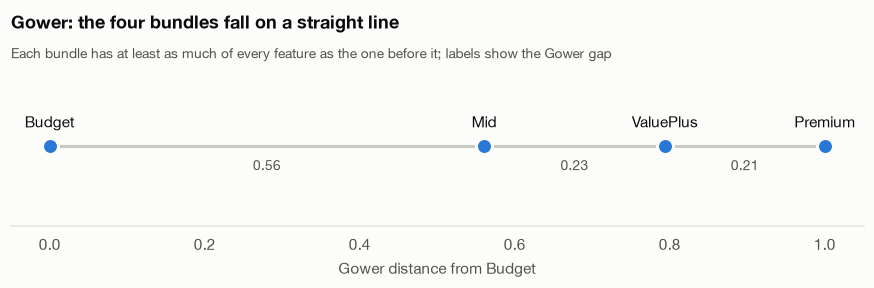

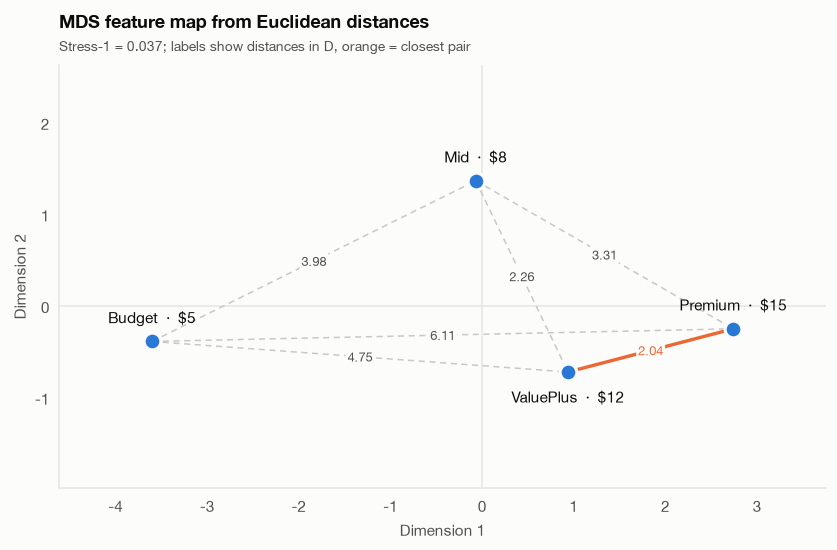

In [32]:
def mds_fit(D, k):
    """Metric MDS in k dimensions; returns the coordinates and Stress-1."""
    model = MDS(n_components=k, metric='precomputed', init='classical_mds', max_iter=1000, normalized_stress=True)
    return model.fit_transform(D.to_numpy()), model.stress_


def variance_share(D):
    """Share of distance variation carried by each classical MDS dimension (eigenvalue share)."""
    centering = np.eye(len(D)) - 1 / len(D)
    eig = np.linalg.eigvalsh(-0.5 * centering @ D.to_numpy() ** 2 @ centering)[::-1]
    return eig.clip(min=0) / eig.clip(min=0).sum()


fit_table = pd.DataFrame(
    {
        name: {
            'variance_dim_1': variance_share(D)[0],
            'variance_dim_2': variance_share(D)[1],
            'variance_dim_3': variance_share(D)[2],
            'stress_1_in_1D': mds_fit(D, 1)[1],
            'stress_1_in_2D': mds_fit(D, 2)[1],
        }
        for name, D in [('Gower', D_gower), ('Euclidean', D_euclid)]
    }
).T
display(
    mark(
        fit_table.style.format(
            {c: '{:.1%}' for c in fit_table.columns if 'variance' in c}
            | {c: '{:.3f}' for c in fit_table.columns if 'stress' in c}
        ),
        [
            ('Gower', ['variance_dim_1', 'stress_1_in_1D']),
            ('Euclidean', ['variance_dim_1', 'variance_dim_2', 'stress_1_in_2D']),
        ],
        title='MDS fit by distance measure',
    )
)

# Why Gower gives a line: every feature rises (or stays) from each bundle to the next, so the gaps simply add up
ladder = numeric_features(bundles_t3).diff().dropna()
steps = [D_gower.loc[a, b] for a, b in zip(BUNDLE_ORDER[:-1], BUNDLE_ORDER[1:])]
print(f"Every feature non-decreasing along Budget → Mid → ValuePlus → Premium: {(ladder >= 0).all().all()}")
print(
    f"Gower steps {' + '.join(f'{s:.3f}' for s in steps)} = {sum(steps):.3f}  vs. Budget–Premium {D_gower.loc['Budget', 'Premium']:.3f}"
)

coords_e = pd.DataFrame(mds_fit(D_euclid, 2)[0], index=BUNDLE_ORDER, columns=['dim_1', 'dim_2'])
coords_e = orient_map(coords_e)
display(mark(coords_e.style.format('{:+.2f}'), [(None, 'dim_2')], title='Euclidean MDS coordinates'))

axis_meaning = (
    numeric_features(bundles_t3).join(coords_e).corr().loc[coords_e.columns, numeric_features(bundles_t3).columns]
)
display(
    mark(
        axis_meaning.style.format('{:+.2f}'),
        [('dim_1', None), ('dim_2', 'priority_support')],
        title='Correlation of each MDS dimension with the features',
    )
)

# Gower map: every bundle sits on one line
line = pd.Series(mds_fit(D_gower, 1)[0].ravel(), index=BUNDLE_ORDER)
line = line - line['Budget'] if line['Premium'] > line['Budget'] else line['Budget'] - line
fig, ax = plt.subplots(figsize=(10, 1.9))
ax.hlines(0, 0, line.max(), color=COLORS['neutral'], lw=2, zorder=1)
ax.scatter(line, np.zeros(4), s=110, color=COLORS['blue'], edgecolor=COLORS['surface'], lw=2, zorder=3)
for name, x in line.items():
    ax.annotate(
        name, (x, 0), xytext=(0, 12), textcoords='offset points', ha='center', fontsize=10, color=COLORS['text']
    )
for a, b in zip(BUNDLE_ORDER[:-1], BUNDLE_ORDER[1:]):
    ax.annotate(
        f'{D_gower.loc[a, b]:.2f}',
        ((line[a] + line[b]) / 2, 0),
        xytext=(0, -16),
        textcoords='offset points',
        ha='center',
        fontsize=9,
        color=COLORS['text_2'],
    )
ax.set_ylim(-1, 1)
ax.set_xlim(-0.05, line.max() + 0.05)
ax.set_yticks([])
ax.set_xlabel('Gower distance from Budget')
ax.grid(visible=False)
ax.spines['left'].set_visible(False)
ax.set_title('Gower: the four bundles fall on a straight line')
subtitle(ax, 'Each bundle has at least as much of every feature as the one before it; labels show the Gower gap')
plt.show()


def draw_map(ax, closest=None):
    """Euclidean feature map; dashed lines show the distances in D, the closest pair is drawn in orange."""
    for a, b in combinations(BUNDLE_ORDER, 2):
        is_closest = closest is not None and {a, b} == set(closest)
        xa, ya, xb, yb = *coords_e.loc[a], *coords_e.loc[b]
        ax.plot(
            [xa, xb],
            [ya, yb],
            color=COLORS['orange'] if is_closest else COLORS['neutral'],
            lw=2.2 if is_closest else 1,
            ls='-' if is_closest else (0, (4, 3)),
            zorder=1,
        )
        ax.annotate(
            f'{D_euclid.loc[a, b]:.2f}',
            ((xa + xb) / 2, (ya + yb) / 2),
            ha='center',
            va='center',
            fontsize=8.5,
            color=COLORS['orange'] if is_closest else COLORS['text_2'],
            bbox=dict(boxstyle='round,pad=0.15', fc=COLORS['surface'], ec='none'),
            zorder=2,
        )
    ax.scatter(
        coords_e['dim_1'], coords_e['dim_2'], s=120, color=COLORS['blue'], edgecolor=COLORS['surface'], lw=2, zorder=3
    )
    for name, row in coords_e.iterrows():
        ax.annotate(
            f"{name}  ·  ${bundles_t3.loc[name, 'price_usd']}",
            (row['dim_1'], row['dim_2']),
            xytext=(0, -20 if name == 'ValuePlus' else 12),  # below the point, clear of the Mid line
            textcoords='offset points',
            ha='center',
            fontsize=10,
            color=COLORS['text'],
        )
    ax.axhline(0, color=COLORS['grid'], lw=1, zorder=0)
    ax.axvline(0, color=COLORS['grid'], lw=1, zorder=0)
    ax.set_aspect('equal', adjustable='datalim')
    ax.grid(visible=False)


fig, ax = plt.subplots(figsize=(9, 5))
draw_map(ax, closest=pair_distances(D_euclid).index[0])
ax.margins(0.16)
ax.set_xlabel('Dimension 1')
ax.set_ylabel('Dimension 2')
ax.set_title('MDS feature map from Euclidean distances')
subtitle(
    ax,
    f"Stress-1 = {fit_table.loc['Euclidean', 'stress_1_in_2D']:.3f}; labels show distances in D, orange = closest pair",
)
plt.show()

**Result:** **The Euclidean map is a usable 2D map, plain Gower reduces the bundles to a line, and only Dimension 1 has a clear meaning.**
- **Plain Gower distance gives a line, not a 2D map.** Dimension 1 holds 100.0% of the variation and Stress-1 is already 0.000 in 1D. This is not simply because there are only four points. Every feature rises or stays level from Budget to Mid to ValuePlus to Premium, so the Gower gaps add up exactly to the Budget – Premium distance (printed above) and the bundles lie on a line. Any second axis from plain Gower is rounding noise.
- **The Euclidean map is a real 2D map and fits well:** two dimensions hold 95.6% of the variation (84.6% + 11.0%) with Stress-1 = 0.037, so it is used as the feature map.
- **Dimension 1 is overall tier:** it rises with every feature (correlations +0.79 to +0.99).
- **Dimension 2 has no clear meaning.** It mainly separates Mid (+1.36) from the other three bundles (-0.72 to -0.25). Priority support is its strongest link (-0.60) but relates more strongly to Dimension 1 (+0.79), and Budget (-0.39) and Premium (-0.25) sit close together although only Premium has it. With four points and 11.0% of the variation, Dimension 2 should not be interpreted, and it is not robust (3.5).

### 3.3 Closest substitutes

**Purpose:** check whether the closest pair by features also looks closest from an outside source, because this pair is the main substitution risk.

The closest pair by features is compared with `bundle_similarity_matrix.csv`, the only outside view of how alike the bundles are. The file's source is not documented, so it is a check, not the main evidence. It is converted to a dissimilarity with $1 - \text{similarity}$.

In [33]:
# Compare closest pairs across both distance matrices and the stated similarity matrix
stated_similarity = df_sim.loc[BUNDLE_ORDER, BUNDLE_ORDER]
D_stated = 1 - stated_similarity

pair_table = pd.DataFrame(
    {
        'gower': pair_distances(D_gower),
        'euclidean': pair_distances(D_euclid),
        'one_minus_similarity': pair_distances(D_stated),
    }
)
pair_table = pair_table.join(pair_table.rank().astype(int).add_suffix('_rank')).sort_values('gower')
pair_table.index = [f'{a} – {b}' for a, b in pair_table.index]
top_pair = pair_table.index[0]
display(
    mark(
        pair_table.style.format({c: '{:.3f}' for c in ['gower', 'euclidean', 'one_minus_similarity']}),
        [(top_pair, None), (pair_table.index[1], 'one_minus_similarity')],
        title='Bundle pairs ranked by Gower, Euclidean and similarity-based distance',
    )
)

,gower,euclidean,one_minus_similarity,gower_rank,euclidean_rank,one_minus_similarity_rank
ValuePlus – Premium,0.206,2.044,0.364,1,1,1
Mid – ValuePlus,0.233,2.259,0.645,2,2,2
Mid – Premium,0.440,3.307,0.692,3,3,3
Budget – Mid,0.560,3.977,0.783,4,4,4
Budget – ValuePlus,0.794,4.752,0.846,5,5,5
Budget – Premium,1.000,6.114,0.875,6,6,6


**Result:** **ValuePlus and Premium are the closest substitutes on all three measures.**
- **Outside check:** they also rank first in `bundle_similarity_matrix.csv` by a wide margin (0.364 vs. 0.645 for the next pair), and all six pairs rank in the same order.
- **Fit with Section 1:** both include Priority support and no ads at the upper end of the range, and ValuePlus wins only 6.8% next to Premium's 31.5% (1.5).

### 3.4 Whitespace: is there a gap worth filling?

**Purpose:** find a position that none of the four candidates occupies and that customers want, because a map of specifications can show the first but not the second.

Every test below is therefore applied to all the configurations the survey covered, and the map is used only to show the result.

**Step 1: score every option.** The survey tested $4 \times 3 \times 2 \times 2 \times 3 \times 2 = 288$ combinations of levels. Four are the four candidates, which leaves 284 screened configurations, called options here and in the tables. Each option $c$ is added to the four candidates, one at a time. With part-worths $\beta_k$ from Section 1, its utility and share of preference are:

$$
U_i = \sum_{k} \beta_k x_{ik},
\qquad
s_c = \frac{e^{U_c}}{e^{U_c} + \sum_{j} e^{U_j}}
$$

The logit model takes the same proportion from every bundle, so the change in expected revenue per subscriber per month depends only on the option's share $s_c$, its price $p_c$, and the baseline $R_0$. The baseline is the expected revenue of the four candidates (each bundle's share × price, summed). It is hypothetical, because none of the four is a live product:

$$
\Delta R_c = s_c \, (p_c - R_0)
$$

**Step 2: screen the options.** An option stays only if it passes all three rules:
- **It raises revenue:** $\Delta R_c > 0$.
- **It is a real trade-off against each of the four candidates.** An option that is no better than a bundle on any feature, at the same or a higher price, *loses to* that bundle: nobody should choose it, yet the model still gives it a share. An option at least as good as a bundle on every feature, at the same or a lower price, *beats* it: that is a price cut, not a new product, because the company would not sell both.
- **It sits in open space.** Its distance to every bundle must exceed the distance between the two closest bundles, ValuePlus and Premium, under both measures (3.1). An option closer than that would only be one more close substitute:

$$
\min_{j} d^{\text{Euclid}}_{cj} > 2.044
\qquad \text{and} \qquad
\min_{j} d^{\text{Gower}}_{cj} > 0.206
$$

**Step 3: pick the whitespace.** Of the options left, the one with the highest revenue change is the whitespace, tested in detail with the Section 1 bootstrap.

**Step 4: map it.** MDS positions depend on every point, so the four bundles and the whitespace are mapped together. Mapping all 288 combinations would not work: they fill the feature space evenly, so no 2D map could fit them.

**No cost data is available,** so options are compared on revenue, not profit, and the result is reported as a break-even. If the whitespace costs $k$ more per subscriber to that tier, profit changes by $s_c(p_c - k - R_0)$, so it pays only if $k < p_c - R_0$.

In [34]:
FEATURES = ['price_usd', 'storage_gb', 'support', 'ads', 'family_seats', 'offline_download']

# Every combination of the tested levels, minus the four candidates
grid = pd.MultiIndex.from_product([sorted(df_choice[c].unique()) for c in FEATURES], names=FEATURES).to_frame(
    index=False
)
all_combinations = len(grid)
grid = (
    grid.merge(df_bundles[FEATURES], how='left', indicator=True)
    .query("_merge == 'left_only'")
    .drop(columns='_merge')
    .reset_index(drop=True)
)
X_grid = preprocess.transform(grid).astype(float)[list(X_bundles.columns)].to_numpy()


def score_options(beta):
    """Share of preference and revenue change of each option when added to the four bundles."""
    v = np.exp(X_bundles.to_numpy() @ beta)
    w = np.exp(X_grid @ beta)
    baseline_revenue = (v * bundle_prices.to_numpy()).sum() / v.sum()
    share = w / (v.sum() + w)
    return share, share * (grid['price_usd'].to_numpy() - baseline_revenue), baseline_revenue


grid['share'], grid['revenue_change'], baseline_revenue = score_options(pw.to_numpy())
revenue_draws = np.array([score_options(b)[1] for b in boot_pw[list(X_bundles.columns)].to_numpy()])
grid['ci_95_low'], grid['ci_95_high'] = np.percentile(revenue_draws, [2.5, 97.5], axis=0)


def better_is_higher(df):
    """Features on a scale where higher is better, with price negated."""
    return np.column_stack(
        [
            -df['price_usd'],
            df['storage_gb'],
            df['family_seats'],
            df['support'].eq('Priority'),
            df['ads'].eq('NoAds'),
            df['offline_download'].eq('Yes'),
        ]
    ).astype(float)


F_grid, F_bundles = better_is_higher(grid)[:, None], better_is_higher(df_bundles)
beats = (F_grid >= F_bundles).all(axis=2)
loses = (F_bundles >= F_grid).all(axis=2)
grid['beats'] = [', '.join(np.array(bundle_names)[row]) for row in beats]
grid['loses_to'] = [', '.join(np.array(bundle_names)[row]) for row in loses]

# Distance to the nearest bundle under both measures, and the gap between the two closest bundles as the bar to clear
to_nearest = pd.DataFrame(cdist(t3_scaler.transform(numeric_features(grid)), Z_bundles), columns=BUNDLE_ORDER)
grid['nearest_bundle'] = to_nearest.idxmin(axis=1)
grid['euclid_distance'] = to_nearest.min(axis=1)
grid['gower_distance'] = gower.gower_matrix(gower_frame(grid), gower_frame(bundles_t3)).min(axis=1)
closest_euclid, closest_gower = pair_distances(D_euclid).iloc[0], pair_distances(D_gower).iloc[0]

raises_revenue = grid['revenue_change'] > 0
screened = grid[raises_revenue & ~loses.any(axis=1) & ~beats.any(axis=1)].sort_values('revenue_change', ascending=False)
whitespace = screened[(screened['euclid_distance'] > closest_euclid) & (screened['gower_distance'] > closest_gower)]

funnel = pd.DataFrame(
    {
        'options_left': [
            len(grid),
            raises_revenue.sum(),
            (raises_revenue & ~loses.any(axis=1)).sum(),
            len(screened),
            len(whitespace),
        ],
        'removed': [
            all_combinations - len(grid),
            (~raises_revenue).sum(),
            (raises_revenue & loses.any(axis=1)).sum(),
            (raises_revenue & ~loses.any(axis=1) & beats.any(axis=1)).sum(),
            len(screened) - len(whitespace),
        ],
    },
    index=[
        'All tested combinations, minus the four bundles',
        'Raises revenue',
        'Does not lose to a bundle',
        'Does not beat a bundle',
        'In open space',
    ],
)
display(
    mark(
        funnel.style,
        [(None, 'options_left'), (funnel.index[2:], 'removed')],
        title='Options left after each screening rule',
    )
)
top_share = (revenue_draws[:, whitespace.index].argmax(axis=1) == 0).mean()
print(
    f"Four-candidate revenue per subscriber: ${baseline_revenue:.2f}. Prices that raise revenue: {sorted(int(p) for p in grid.loc[raises_revenue, 'price_usd'].unique())}. "
    f"Prices left: {sorted(int(p) for p in whitespace['price_usd'].unique())}. CI above $0: {(whitespace['ci_95_low'] > 0).sum()} of {len(whitespace)}. "
    f"Top option ranks first in {top_share:.1%} of bootstrap draws."
)

SCORES = ['share', 'revenue_change', 'ci_95_low', 'ci_95_high']
POSITION = ['nearest_bundle', 'euclid_distance', 'gower_distance']
OPTION_FORMAT = {
    'share': '{:.1%}',
    'revenue_change': '{:+.2f}',
    'ci_95_low': '{:.2f}',
    'ci_95_high': '{:.2f}',
    'euclid_distance': '{:.2f}',
    'gower_distance': '{:.3f}',
}


def option(price, storage, support, ads, seats, offline):
    """Look up one option in the screened grid by its exact feature levels."""
    return grid[grid[FEATURES].eq([price, storage, support, ads, seats, offline]).all(axis=1)]


examples = pd.concat(
    [
        option(15, 1000, 'Standard', 'NoAds', 6, 'Yes'),
        option(12, 1000, 'Priority', 'NoAds', 6, 'Yes'),
        option(12, 1000, 'Standard', 'NoAds', 4, 'Yes'),
    ]
)
display(
    mark(
        examples[FEATURES + ['share', 'revenue_change', 'loses_to', 'beats'] + POSITION]
        .style.hide()
        .format(OPTION_FORMAT),
        [
            (None, ['revenue_change', 'loses_to', 'beats']),
            (examples.index[0], 'price_usd'),
            (examples.index[-1], POSITION),
        ],
        title='Three example options against the screening rules',
    )
)
display(
    mark(
        whitespace.head(5)[FEATURES + SCORES + POSITION].style.hide().format(OPTION_FORMAT),
        [(None, ['revenue_change']), (whitespace.index[0], SCORES + POSITION)],
        title='Top five options after screening, by revenue change',
    )
)

,options_left,removed
"All tested combinations, minus the four bundles",284,4
Raises revenue,142,142
Does not lose to a bundle,40,102
Does not beat a bundle,37,3
In open space,32,5


Four-candidate revenue per subscriber: $10.45. Prices that raise revenue: [12, 15]. Prices left: [12]. CI above $0: 32 of 32. Top option ranks first in 100.0% of bootstrap draws.


price_usd,storage_gb,support,ads,family_seats,offline_download,share,revenue_change,loses_to,beats,nearest_bundle,euclid_distance,gower_distance
15,1000,Standard,NoAds,6,Yes,8.5%,+0.39,Premium,,Premium,2.00,0.167
12,1000,Priority,NoAds,6,Yes,80.2%,+1.24,,"Premium, ValuePlus",Premium,0.79,0.050
12,1000,Standard,NoAds,4,Yes,36.1%,+0.56,,,Mid,1.85,0.156


price_usd,storage_gb,support,ads,family_seats,offline_download,share,revenue_change,ci_95_low,ci_95_high,nearest_bundle,euclid_distance,gower_distance
12,1000,Priority,NoAds,6,No,66.2%,+1.03,0.87,1.17,Premium,2.44,0.217
12,1000,Standard,NoAds,6,Yes,54.4%,+0.84,0.72,0.98,Premium,2.15,0.217
12,1000,Priority,NoAds,4,No,48.1%,+0.75,0.63,0.86,Premium,2.68,0.256
12,1000,Standard,NoAds,6,No,36.6%,+0.57,0.47,0.67,Premium,3.15,0.383
12,1000,Priority,Ads,6,Yes,35.5%,+0.55,0.47,0.62,Premium,2.44,0.217


**Result:** **32 of the 284 options clear all three rules, all at \$12, and one leads them: 1000 GB, no ads, 6 seats and Priority support, without offline download.**
- **The revenue rule is mechanical.** The baseline is \$10.45, the expected revenue of the four candidates, so by $\Delta R_c = s_c(p_c - R_0)$ any option priced above it raises revenue, whatever its features. All 142 options at \$12 and \$15 pass, and all 142 at \$5 and \$8 fail.
- **\$12 is not a price optimum.** The model has no "none" option, so it cannot show customers leaving at a higher price.
- **A cheaper entry tier is not supported by this screen, and untested.** The same gap means the model cannot show new customers a cheaper tier might bring.
- **The trade-off rule removes options that are not real choices:** 102 that lose to a bundle, including every \$15 option, and 3 that beat one. In the second table, Premium without Priority support still scores +\$0.39 although it loses to Premium at the same price, and Premium at \$12 scores +\$1.24 although that is only a price cut.
- **The open-space rule removes 5 close substitutes.** The third row of the second table raises revenue by \$0.56 and is a real trade-off, but it sits 1.85 from Mid, closer than ValuePlus is to Premium (2.044), so it is not whitespace.
- **The leader is clear:** +\$1.03 [0.87, 1.17], ahead of +\$0.84 for the next option, and first in every bootstrap draw. All 32 have a 95% CI above \$0. Because all 32 have the same price, ranking by revenue is the same as ranking by share, so this is not a ranking by profit.

#### Premium Lite

Premium Lite is a label for the leading option. It is added to the four candidates and tested with the Section 1 bootstrap, because the search shows only that it leads, not where its share comes from or who would choose it. The segment shares use each segment's own Section 1 model.

In [35]:
# The whitespace: the highest-revenue option left after the screen
concepts = whitespace.head(1)[FEATURES].assign(bundle='Premium Lite').set_index('bundle')
display(mark(concepts.style, [(None, None)], title='Premium Lite configuration'))

# Conjoint test: add each concept to the four bundles
X_concepts = preprocess.transform(concepts.reset_index()).astype(float)[list(X_bundles.columns)]


def concept_metrics(b):
    """Share and revenue change when each concept joins the four bundles, for one set of part-worths."""
    beta = b.to_numpy()
    base_u = X_bundles.to_numpy() @ beta
    base_s = logit_shares(base_u)
    base_rev = (base_s * bundle_prices.to_numpy()).sum()
    out = {}
    for i, name in enumerate(concepts.index):
        u = np.append(base_u, X_concepts.to_numpy()[i] @ beta)
        s = logit_shares(u)
        prices = np.append(bundle_prices.to_numpy(), concepts['price_usd'].iloc[i])
        out[(name, 'share')] = s[-1]
        out[(name, 'share_from_mid')] = base_s[bundle_names.index('Mid')] - s[bundle_names.index('Mid')]
        out[(name, 'share_from_premium')] = base_s[bundle_names.index('Premium')] - s[bundle_names.index('Premium')]
        out[(name, 'revenue_change')] = (s * prices).sum() - base_rev
    return pd.Series(out)


concept_ci = boot_summary(concept_metrics(pw), boot_apply(concept_metrics, boot_pw))
concept_ci.index = pd.MultiIndex.from_tuples(concept_ci.index)
concept_table = pd.DataFrame(
    {
        (m, col): [
            (f'{v:.1%} [{lo:.1%}, {hi:.1%}]' if col == 'estimate [95% CI]' else fmt_p(p))
            if m != 'revenue_change'
            else (
                f"{'-' if v < 0 else '+'}${abs(v):.2f} [{lo:.2f}, {hi:.2f}]" if col == 'estimate [95% CI]' else fmt_p(p)
            )
            for v, lo, hi, p in concept_ci.xs(m, level=1)[['estimate', 'ci_95_low', 'ci_95_high', 'p_value']]
            .loc[concepts.index]
            .to_numpy()
        ]
        for m in ['share', 'share_from_mid', 'share_from_premium', 'revenue_change']
        for col in ['estimate [95% CI]', 'p_value']
    },
    index=concepts.index,
)
display(
    mark(
        concept_table.style,
        [
            (
                None,
                [(m, 'estimate [95% CI]') for m in ['share', 'share_from_mid', 'share_from_premium', 'revenue_change']],
            ),
        ],
        title='Premium Lite concept test',
    )
)


# Who would buy it: its share within each segment (each segment's own Section 1 model), with 95% CIs
def concept_share(b):
    """Share of the first concept alongside the four bundles."""
    u = np.append(X_bundles.to_numpy() @ b.to_numpy(), X_concepts.iloc[0].to_numpy() @ b.to_numpy())
    return pd.Series({'share': logit_shares(u)[-1]})


seg_concept = pd.concat(
    {
        seg: boot_summary(concept_share(seg_fits[seg].params), boot_apply(concept_share, boot_seg_pw[seg])).iloc[0]
        for seg in segments
    },
    axis=1,
).T
show_ci(
    seg_concept,
    'pct',
    marks=[(None, ['estimate', 'ci_95_low', 'ci_95_high'])],
    title='Premium Lite share of preference by segment',
)

,price_usd,storage_gb,support,ads,family_seats,offline_download
bundle,,,,,,
Premium Lite,12,1000,Priority,NoAds,6,No


,estimate,ci_95_low,ci_95_high,boot_se,p_value
PowerUser,76.2%,71.5%,80.8%,2.4%,<0.001
ValueSeeker,62.0%,55.4%,68.9%,3.5%,<0.001
Family,73.1%,64.7%,81.0%,4.2%,<0.001


**Result:** **Premium Lite is the whitespace: at \$12 it wins 66.2% [63.1%, 69.2%] and adds +\$1.03 [0.87, 1.17] per subscriber per month before cost. All p < 0.001.**
- **Most of its share comes from two candidates:** 40.2 percentage points from Mid [37.7, 42.6] and 20.9 from Premium [18.2, 23.7]. The Premium figure is likely too low, because logit takes the same proportion from every bundle and cannot see that Premium Lite differs from Premium only by offline download and \$3.
- **Its appeal is broad:** PowerUsers 76.2% [71.5%, 80.8%], Families 73.1% [64.7%, 81.0%], ValueSeekers 62.0% [55.4%, 68.9%].

These shares are not forecasts: the logit model assumes substitution in proportion to modeled shares, and with no "none" option it cannot show users leaving the market or new users joining it.

#### Add it or replace ValuePlus?

Premium Lite has the same \$12 price as ValuePlus, so the test above, which keeps all four candidates, does not settle whether ValuePlus is still needed. Each line-up is therefore scored on all its tiers:

$$
R = \sum_{j \in \text{line-up}} s_j \, p_j
$$

In [36]:
# Score whole line-ups: does Premium Lite add revenue, and is ValuePlus still needed?
lineups = {
    'four candidates': BUNDLE_ORDER,
    'add': BUNDLE_ORDER + ['Premium Lite'],
    'replace': ['Budget', 'Mid', 'Premium', 'Premium Lite'],
}
X_options = pd.concat([X_bundles.set_axis(bundle_names), X_concepts.set_axis(concepts.index)])
option_prices = pd.concat([bundle_prices, concepts['price_usd']])


def lineup_metrics(b):
    """Share and revenue by tier under each line-up, and the revenue changes."""
    u = pd.Series(X_options.to_numpy() @ b.to_numpy(), index=X_options.index)
    out = {}
    for name, tiers in lineups.items():
        share = logit_shares(u[tiers])
        revenue = share * option_prices[tiers].astype(float)
        out.update({f'{name}|share|{t}': v for t, v in share.items()})
        out.update({f'{name}|revenue|{t}': v for t, v in revenue.items()})
        out[f'{name}|total'] = revenue.sum()
    out['Add Premium Lite vs. four candidates'] = out['add|total'] - out['four candidates|total']
    out['Replace ValuePlus vs. four candidates'] = out['replace|total'] - out['four candidates|total']
    out['Replace vs. add'] = out['replace|total'] - out['add|total']
    return pd.Series(out)


lineup_est = lineup_metrics(pw)
lineup_ci = boot_summary(lineup_est, boot_apply(lineup_metrics, boot_pw))

tiers = lineups['add']
tier_table = pd.DataFrame(
    {
        (name, m): [lineup_est.get(f'{name}|{m}|{t}', np.nan) for t in tiers]
        for name in lineups
        for m in ['share', 'revenue']
    },
    index=tiers,
)
tier_table.loc['Total'] = [1.0 if m == 'share' else lineup_est[f'{name}|total'] for name, m in tier_table.columns]
display(
    mark(
        tier_table.style.format(
            {c: '{:.1%}' if c[1] == 'share' else '${:.2f}' for c in tier_table.columns}, na_rep='–'
        ),
        [
            ('Total', [c for c in tier_table.columns if c[1] == 'revenue']),
            (['Mid', 'Premium'], [('four candidates', 'revenue'), ('add', 'revenue')]),
            ('Premium Lite', [('add', 'revenue')]),
        ],
        title='Share and expected revenue per subscriber by tier: four candidates, Premium Lite added, ValuePlus replaced',
    )
)

show_ci(
    lineup_ci.loc[['Add Premium Lite vs. four candidates', 'Replace ValuePlus vs. four candidates', 'Replace vs. add']],
    'usd',
    marks=[(None, ['estimate', 'ci_95_low', 'ci_95_high', 'p_value'])],
    title='Change in total revenue per subscriber, USD/month, with 95% bootstrap CIs',
)

# Break-even: a tier adding cost k per own subscriber changes profit by s(p - k - R0), so k must stay below p - R0
baseline_revenue_per_subscriber = lineup_est['four candidates|total']
lite_price = float(concepts['price_usd'].iloc[0])
show_facts(
    {
        'Premium Lite price less the four-candidate baseline (USD/month per Premium Lite subscriber)': (
            f'${lite_price - baseline_revenue_per_subscriber:.2f}'
        ),
        'Same break-even spread over all subscribers (USD/month)': (
            f"${lineup_ci.loc['Add Premium Lite vs. four candidates', 'estimate']:.2f}"
        ),
    },
    'Break-even extra cost of Premium Lite',
)

,estimate,ci_95_low,ci_95_high,boot_se,p_value
Add Premium Lite vs. four candidates,$1.03,$0.87,$1.17,$0.08,<0.001
Replace ValuePlus vs. four candidates,$1.01,$0.87,$1.16,$0.08,<0.001
Replace vs. add,-$0.01,-$0.02,-$0.01,$0.00,<0.001


,value
Premium Lite price less the four-candidate baseline (USD/month per Premium Lite subscriber),$1.55
Same break-even spread over all subscribers (USD/month),$1.03


**Result:** **Add Premium Lite. Revenue does not settle ValuePlus: keeping it earns slightly more, and the gap is too small to decide the question.**
- **Expected revenue per subscriber rises either way:** from \$10.45 to \$11.48 with Premium Lite added, **+\$1.03 [0.87, 1.17]**, p < 0.001, and to \$11.46 with ValuePlus replaced, +\$1.01 [0.87, 1.16], p < 0.001.
- **Keeping ValuePlus earns slightly more:** the gap is \$0.01 [0.01, 0.02] per subscriber per month. ValuePlus's small share is not a reason to drop it: Budget's share is smaller, and share does not show what a tier contributes.
- **What decides ValuePlus is not in this data.** Dropping it pays only if running it costs more than \$0.01 per subscriber per month, and two \$12 tiers may confuse customers, which the survey cannot measure. The launch line-up drops it for simplicity (3.6). That is a judgment, not a statistical result.
- **Break-even:** in the pooled logit, Premium Lite pays only if its extra cost stays below \$1.55 per Premium Lite subscriber per month, equal to \$1.03 spread over all subscribers (segment value in 3.6). It includes more storage and more seats than ValuePlus at the same \$12, so that cost must be checked.
- **Revenue moves as well as grows.** Premium Lite would bring \$7.94 of the \$11.48 in expected revenue per subscriber, while Mid falls from \$4.86 to \$1.64 and Premium from \$4.73 to \$1.60. This repositions the line, so the risk sits in the two tiers with the highest expected revenue among the four candidates.

#### Premium Lite on the map

The four bundles and Premium Lite are mapped together on the same z-scores as $D$, so the bundle distances do not change.

,nearest_bundle,distance
bundle,,
Premium Lite,Premium,2.44


,value
Variation in 2D,92.0%
Stress-1,0.063


All 288 combinations: 33.3% of the variation in 2D


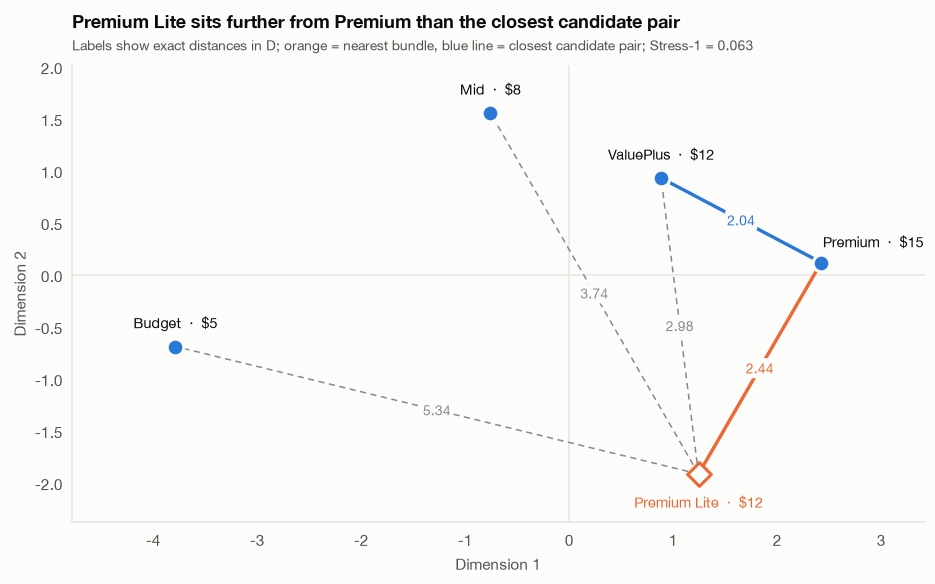

In [37]:
# Position of each concept relative to the four candidates (same z-scores as D, so bundle distances do not change)
Z_concepts = t3_scaler.transform(numeric_features(concepts))
to_bundles = pd.DataFrame(cdist(Z_concepts, Z_bundles), index=concepts.index, columns=BUNDLE_ORDER)
distinct = pd.DataFrame({'nearest_bundle': to_bundles.idxmin(axis=1), 'distance': to_bundles.min(axis=1)})
display(
    mark(
        distinct.style.format({'distance': '{:.2f}'}),
        [(None, ['nearest_bundle', 'distance'])],
        title="Premium Lite's nearest bundle",
    )
)

# The bundles and concepts mapped together
map_names = BUNDLE_ORDER + list(concepts.index)
Z_map = np.vstack([Z_bundles, Z_concepts])
D_map = pd.DataFrame(cdist(Z_map, Z_map), index=map_names, columns=map_names)
points, stress_map = mds_fit(D_map, 2)
coords_map = pd.DataFrame(points, index=map_names, columns=['dim_1', 'dim_2'])
coords_map = orient_map(coords_map)
show_facts(
    {'Variation in 2D': f'{variance_share(D_map)[:2].sum():.1%}', 'Stress-1': f'{stress_map:.3f}'},
    'Fit of the map with Premium Lite',
)

# Why every combination cannot go on one map
all_options = pd.concat([grid[FEATURES], df_bundles[FEATURES]])
Z_options = StandardScaler().fit_transform(numeric_features(all_options))
print(
    f"All {len(all_options)} combinations: {variance_share(pd.DataFrame(cdist(Z_options, Z_options)))[:2].sum():.1%} of the variation in 2D"
)

fig, ax = plt.subplots(figsize=(10, 5.4))
ax.axhline(0, color=COLORS['grid'], lw=1, zorder=0)
ax.axvline(0, color=COLORS['grid'], lw=1, zorder=0)


def draw_distance(a, b, color, lw, ls):
    """Line between two points on the map, labeled with their exact distance in D."""
    (xa, ya), (xb, yb) = coords_map.loc[a], coords_map.loc[b]
    ax.plot([xa, xb], [ya, yb], color=color, lw=lw, ls=ls, zorder=1)
    ax.annotate(
        f'{D_map.loc[a, b]:.2f}',
        ((xa + xb) / 2, (ya + yb) / 2),
        ha='center',
        va='center',
        fontsize=9,
        color=color,
        bbox=dict(boxstyle='round,pad=0.15', fc=COLORS['surface'], ec='none'),
        zorder=2,
    )


nearest = distinct.loc['Premium Lite', 'nearest_bundle']
for bundle in BUNDLE_ORDER:
    if bundle != nearest:
        draw_distance('Premium Lite', bundle, COLORS['muted'], 1, (0, (4, 3)))
draw_distance('Premium Lite', nearest, COLORS['orange'], 2.2, '-')
draw_distance(*pair_distances(D_euclid).index[0], COLORS['blue'], 2.2, '-')

LABEL_OFFSET = {'Premium': (34, 10), 'Premium Lite': (0, -22)}  # clear of the distance lines
for name, row in coords_map.iterrows():
    is_bundle = name in BUNDLE_ORDER
    ax.scatter(
        row['dim_1'],
        row['dim_2'],
        s=120,
        marker='o' if is_bundle else 'D',
        zorder=3,
        lw=2,
        facecolor=COLORS['blue'] if is_bundle else COLORS['surface'],
        edgecolor=COLORS['surface'] if is_bundle else COLORS['orange'],
    )
    price = bundles_t3.loc[name, 'price_usd'] if is_bundle else concepts.loc[name, 'price_usd']
    ax.annotate(
        f'{name}  ·  ${price}',
        (row['dim_1'], row['dim_2']),
        xytext=LABEL_OFFSET.get(name, (0, 12)),
        textcoords='offset points',
        ha='center',
        fontsize=9.5,
        color=COLORS['text'] if is_bundle else COLORS['orange'],
    )
ax.margins(0.16)
ax.set_aspect('equal', adjustable='datalim')
ax.grid(visible=False)
ax.set_xlabel('Dimension 1')
ax.set_ylabel('Dimension 2')
ax.set_title('Premium Lite sits further from Premium than the closest candidate pair')
subtitle(
    ax,
    f'Labels show exact distances in D; orange = nearest bundle, blue line = closest candidate pair; Stress-1 = {stress_map:.3f}',
)
plt.show()

**Result:** **Premium Lite sits apart from all four bundles, but narrowly under Gower, and the map illustrates this rather than proving it.**
- **The margin is small.** Its nearest bundle is Premium at 2.44, further than ValuePlus is from Premium (2.044). Under Gower the margin is small (0.217 vs. 0.206), so it is open space by specification, and customers may still see it as close to Premium.
- **The map is an illustration, not evidence.** With five points, 2D holds 92.0% of the variation and Stress-1 is 0.063, just above the usual good-fit guide and weaker than the four-bundle map (0.037). The table distances are exact, and Dimension 2 should not be interpreted.
- **Blank areas on the chart are not opportunities by themselves.** With five points most of the map is empty by construction, and because Dimension 2 has no clear meaning, a blank spot does not define a product. All 284 options were scored directly instead, and the cheaper ones lower revenue in this model. It has no "none" option, so the appeal of a cheaper tier to new customers remains untested.
- **Why the search does not use the map:** a 2D map of every tested combination would keep too little of the variation (printed above).

### 3.5 Euclidean vs. Gower: which is more appropriate?

**Purpose:** decide which distance should support the positioning conclusions, because the bundles mix price, storage and yes/no features, and each measure scales them differently.

The two distances are compared side by side, with two further versions that test what drives the differences:

- **$\sqrt{\text{Gower}}$:** the form Gower (1971) recommended, $d_{ij} = \sqrt{1 - s_{ij}}$ with similarity
  $s_{ij} = 1 - d^{\text{Gower}}_{ij}$, which equals $\sqrt{d^{\text{Gower}}_{ij}}$. It turns exact gap addition into right
  angles, so it can fill more than one dimension.
- **Euclidean (min-max):** Euclidean distance on features scaled to 0–1 as in Gower, which shows whether z-scores matter.

,variance_in_2D,stress_1_in_2D,closest_pair,distance,runner_up,runner_up_distance
Gower,100.0%,0.000,ValuePlus – Premium,0.206,Mid – ValuePlus,0.233
√Gower,91.2%,0.072,ValuePlus – Premium,0.454,Mid – ValuePlus,0.483
Euclidean (z-scores),95.6%,0.037,ValuePlus – Premium,2.044,Mid – ValuePlus,2.259
Euclidean (min-max),95.9%,0.038,ValuePlus – Premium,0.734,Mid – ValuePlus,1.077


,gower,euclidean
price_usd,ValuePlus – Premium,ValuePlus – Premium
log_storage_gb,ValuePlus – Premium,ValuePlus – Premium
family_seats,ValuePlus – Premium,ValuePlus – Premium
priority_support,Mid – ValuePlus,Mid – ValuePlus
no_ads,ValuePlus – Premium,ValuePlus – Premium
offline_download,ValuePlus – Premium,ValuePlus – Premium


,gower_max_share,z_score_full_range
price_usd,0.167,2.63
log_storage_gb,0.167,2.82
family_seats,0.167,2.80
priority_support,0.167,2.00
no_ads,0.167,2.31
offline_download,0.167,2.31


no_ads and offline_download are identical across the four bundles: True


,gower_nearest,gower_distance,euclidean_nearest,euclidean_distance
bundle,,,,
Premium Lite,Premium,0.217,Premium,2.44


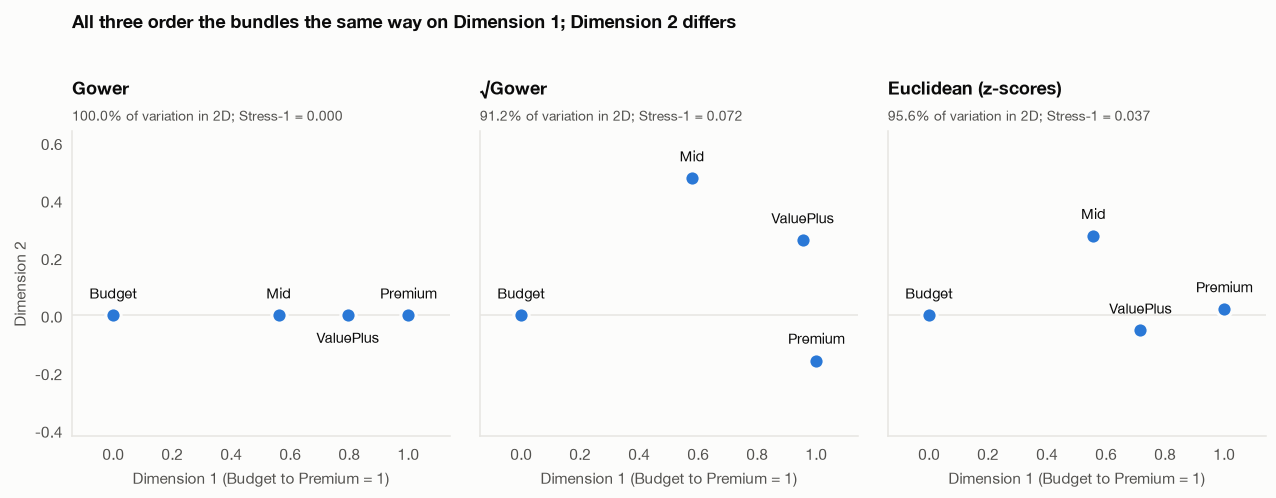

In [38]:
U_bundles = MinMaxScaler().fit_transform(numeric_features(bundles_t3))
versions_2d = {
    'Gower': D_gower,
    '√Gower': np.sqrt(D_gower),
    'Euclidean (z-scores)': D_euclid,
    'Euclidean (min-max)': as_matrix(cdist(U_bundles, U_bundles)),
}
compare_table = pd.DataFrame(
    {
        name: {
            'variance_in_2D': variance_share(D)[:2].sum(),
            'stress_1_in_2D': mds_fit(D, 2)[1],
            'closest_pair': ' – '.join(pair_distances(D).index[0]),
            'distance': pair_distances(D).iloc[0],
            'runner_up': ' – '.join(pair_distances(D).index[1]),
            'runner_up_distance': pair_distances(D).iloc[1],
        }
        for name, D in versions_2d.items()
    }
).T
display(
    mark(
        compare_table.style.format(
            {
                'variance_in_2D': '{:.1%}',
                'stress_1_in_2D': '{:.3f}',
                'distance': '{:.3f}',
                'runner_up_distance': '{:.3f}',
            }
        ),
        [(None, ['variance_in_2D', 'stress_1_in_2D', 'closest_pair'])],
        title='2D fit and closest pair by distance version',
    )
)

# Remove one feature at a time: does the closest pair change?
FEATURE_MAP = {
    'price_usd': 'price_usd',
    'log_storage_gb': 'log_storage_gb',
    'family_seats': 'family_seats',
    'priority_support': 'support',
    'no_ads': 'ads',
    'offline_download': 'offline_download',
}
leave_one_out = {}
for num_name, gower_name in FEATURE_MAP.items():
    z = StandardScaler().fit_transform(numeric_features(bundles_t3).drop(columns=num_name))
    leave_one_out[num_name] = {
        'gower': ' – '.join(
            pair_distances(as_matrix(gower.gower_matrix(gower_frame(bundles_t3).drop(columns=gower_name)))).index[0]
        ),
        'euclidean': ' – '.join(pair_distances(as_matrix(cdist(z, z))).index[0]),
    }
leave_one_out = pd.DataFrame(leave_one_out).T
display(
    mark(
        leave_one_out.style,
        [('priority_support', None)],
        title='Closest pair after removing one feature at a time',
    )
)

# What each feature can contribute under each distance
features = numeric_features(bundles_t3)
feature_weight = pd.DataFrame(
    {
        'gower_max_share': 1 / features.shape[1],
        'z_score_full_range': (features.max() - features.min()) / features.std(ddof=0),
    }
)
display(
    mark(
        feature_weight.style.format({'gower_max_share': '{:.3f}', 'z_score_full_range': '{:.2f}'}),
        [
            (None, 'gower_max_share'),
            (['price_usd', 'log_storage_gb', 'priority_support', 'no_ads', 'offline_download'], 'z_score_full_range'),
        ],
        title='How much each feature can contribute to distance',
    )
)
print(
    f"no_ads and offline_download are identical across the four bundles: {features['no_ads'].equals(features['offline_download'])}"
)

# Concepts under both distances
concept_gower = pd.DataFrame(
    gower.gower_matrix(gower_frame(concepts), gower_frame(bundles_t3)), index=concepts.index, columns=BUNDLE_ORDER
)
concept_compare = pd.DataFrame(
    {
        'gower_nearest': concept_gower.idxmin(axis=1),
        'gower_distance': concept_gower.min(axis=1),
        'euclidean_nearest': to_bundles.idxmin(axis=1),
        'euclidean_distance': to_bundles.min(axis=1),
    }
)
display(
    mark(
        concept_compare.style.format({'gower_distance': '{:.3f}', 'euclidean_distance': '{:.2f}'}),
        [(None, None)],
        title="Premium Lite's nearest bundle under Gower and Euclidean",
    )
)

# The three maps on one scale: each is rescaled so that Budget to Premium spans 1 on dimension 1
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharex=True, sharey=True, gridspec_kw={'wspace': 0.08})
for ax, name in zip(axes, ['Gower', '√Gower', 'Euclidean (z-scores)']):
    D = versions_2d[name]
    xy = pd.DataFrame(mds_fit(D, 2)[0], index=BUNDLE_ORDER, columns=['x', 'y'])
    xy = xy - xy.loc['Budget']
    span = xy.loc['Premium', 'x']
    xy = xy / span
    if xy.loc['Mid', 'y'] < 0:
        xy['y'] *= -1
    ax.axhline(0, color=COLORS['grid'], lw=1, zorder=0)
    ax.scatter(xy['x'], xy['y'], s=100, color=COLORS['blue'], edgecolor=COLORS['surface'], lw=2, zorder=3)
    for b, row in xy.iterrows():
        below = name == 'Gower' and b == 'ValuePlus'  # keeps the label clear of its neighbors on the line
        ax.annotate(
            b,
            (row['x'], row['y']),
            xytext=(0, -18 if below else 11),
            textcoords='offset points',
            ha='center',
            fontsize=9.5,
            color=COLORS['text'],
        )
    ax.set_xlim(-0.14, 1.14)
    ax.set_ylim(-0.42, 0.64)
    ax.grid(visible=False)
    ax.set_xlabel('Dimension 1 (Budget to Premium = 1)')
    ax.set_title(name)
    subtitle(
        ax,
        f"{variance_share(D)[:2].sum():.1%} of variation in 2D; Stress-1 = {compare_table.loc[name, 'stress_1_in_2D']:.3f}",
    )
axes[0].set_ylabel('Dimension 2')
fig.subplots_adjust(top=0.74)
fig.suptitle(
    'All three order the bundles the same way on Dimension 1; Dimension 2 differs',
    x=0.125,
    y=0.99,
    ha='left',
    fontsize=12,
    fontweight='bold',
)
plt.show()

**Result:** **Euclidean is the better choice for this map and Gower for reading individual distances. The business conclusions are the same under both.**

**Where they agree:**
- **Same closest pair:** ValuePlus – Premium in all four versions, which all use log storage, with Mid – ValuePlus as runner-up.
- **Same answer when features are removed:** the closest pair matches under Gower and Euclidean in all six tests. It changes only without Priority support, in both, because that feature is what separates Mid from ValuePlus.
- **Same order on Dimension 1:** Budget, Mid, ValuePlus, Premium.
- **Same nearest bundle for the whitespace:** Premium Lite sits nearest Premium under both.

**Where they differ:**

| | Gower | Euclidean (z-scores) |
|---|---|---|
| 2D map | Plain form is a line: 100.0% on one dimension. $\sqrt{\text{Gower}}$ gives 2D with Stress-1 = 0.072 | Real 2D map: 95.6%, Stress-1 = 0.037 |
| Feature weight | Equal by design (0.167 each) | Unequal: 2.00 for Priority support up to 2.82 for storage, set by the spread across four bundles |
| Reading a distance | Direct: 0.206 is that share of the maximum difference | No direct meaning: 2.044 standard-deviation units |

**Why the choice falls this way:** Euclidean gives the better 2D fit of the two real 2D options (Stress-1 0.037 vs. 0.072). Gower's equal weights and direct reading are real advantages, and they do not depend on standard deviations estimated from four bundles. The closest pair and Premium Lite's nearest bundle are the same under both. The revenue figures come from the conjoint model, and the open-space rule requires both distances to pass (3.4).

**What neither settles:** Dimension 2 is not robust. In the chart ValuePlus sits on opposite sides of the Budget – Premium baseline under $\sqrt{\text{Gower}}$ and Euclidean, so only Dimension 1 should be interpreted with confidence. Both also count one Budget difference twice, because no ads and offline download are identical across the four bundles, and both measure specifications rather than customer perception.

### 3.6 Launch line-up

**Purpose:** reconcile Section 1, which picked the best of the four candidates, with Premium Lite, by scoring whole line-ups without Budget and ValuePlus, and then test how far that result depends on the model.

Section 1 picked Mid, with Premium as the upsell, and found that Budget and ValuePlus lose on value (1.5). Budget is dropped because it gives up more value than it saves. ValuePlus is left out for simplicity, a judgment set out in 3.4. Premium Lite was tested alongside all four candidates (3.4), so that test does not show what the launch line-up earns. Each line-up is scored on the stored bootstrap draws, so the gaps have CIs and no new randomness enters.

**Limit:** the model has no "none" option, so dropping Budget (0.9% of the four-candidate shares) and ValuePlus (6.8%) assumes their choosers stay and move to a remaining tier.

**Checks that follow the scoring:**
- **Segment models.** 1.7 rejects equal preferences across segments, so each line-up is rescored with each segment's own model and weighted by segment size.
- **Nesting.** Logit treats Premium Lite and Premium as no closer than any other pair, although they differ only by offline download and \$3. A nested logit lets the two share a correlated error. Here $\lambda$ runs from 1 (plain logit) toward 0 (near-perfect substitutes). It is an assumed value, not an estimate, and the utilities stay fixed:

$$
P(\text{nest}) = \frac{e^{I}}{e^{I} + e^{U_{\text{Mid}}}},
\qquad
I = \lambda \ln\!\left(e^{U_{\text{Lite}}/\lambda} + e^{U_{\text{Premium}}/\lambda}\right),
\qquad
P(j \mid \text{nest}) = \frac{e^{U_j/\lambda}}{e^{U_{\text{Lite}}/\lambda} + e^{U_{\text{Premium}}/\lambda}}
$$

- **Mid's price.** The 1.6 price checks use the four candidates, so Mid is repriced inside the launch line-up.
- **The two steps.** WTP tests what each step buys: from Mid to Premium Lite, and from Premium Lite to Premium, where offline download is the only added feature.

In [39]:
# Score the launch candidates. Reads stored bootstrap draws only, so no new randomness enters.
launch_lineups = {
    'Four candidates': BUNDLE_ORDER,
    'Mid + Premium': ['Mid', 'Premium'],
    'Mid + Premium Lite': ['Mid', 'Premium Lite'],
    'Mid + Premium Lite + Premium': ['Mid', 'Premium Lite', 'Premium'],
}
BASELINE_LINEUP, RECOMMENDED_LINEUP = 'Four candidates', 'Mid + Premium Lite + Premium'


def launch_metrics(b):
    """Share by tier and total expected revenue for each launch candidate, with gaps to the recommended line-up."""
    utilities = pd.Series(X_options.to_numpy() @ b.to_numpy(), index=X_options.index)
    out = {}
    for name, line_up in launch_lineups.items():
        shares = logit_shares(utilities[line_up])
        out.update({f'{name}|{tier}': share for tier, share in shares.items()})
        out[f'{name}|Total'] = (shares * option_prices[line_up].astype(float)).sum()
    for name in launch_lineups:
        if name != RECOMMENDED_LINEUP:
            out[f'{RECOMMENDED_LINEUP} vs. {name}'] = out[f'{RECOMMENDED_LINEUP}|Total'] - out[f'{name}|Total']
    return pd.Series(out)


launch_ci = boot_summary(launch_metrics(pw), boot_apply(launch_metrics, boot_pw))
launch_tiers = ['Budget', 'Mid', 'ValuePlus', 'Premium Lite', 'Premium']
launch_table = pd.DataFrame(
    {name: [launch_ci['estimate'].get(f'{name}|{tier}', np.nan) for tier in launch_tiers] for name in launch_lineups},
    index=launch_tiers,
)
launch_table.loc['Revenue per subscriber (USD/month)'] = [
    launch_ci.loc[f'{name}|Total', 'estimate'] for name in launch_lineups
]
tier_rows = launch_table.index[:-1]
display(
    mark(
        launch_table.style.format('{:.1%}', subset=(tier_rows, launch_table.columns), na_rep='–').format(
            '${:.2f}', subset=(launch_table.index[-1:], launch_table.columns)
        ),
        [(None, None)],
        title='Launch line-ups: share by tier and expected revenue per subscriber',
    )
)
show_ci(
    launch_ci.loc[[f'{RECOMMENDED_LINEUP} vs. {name}' for name in launch_lineups if name != RECOMMENDED_LINEUP]],
    'usd',
    marks=[(None, ['estimate', 'ci_95_low', 'ci_95_high', 'p_value'])],
    title='Revenue gap between the recommended line-up and each alternative, USD/month, with 95% bootstrap CIs',
)

# Who picks each tier? Segment shares under the recommended line-up
recommended_tiers = launch_lineups[RECOMMENDED_LINEUP]
segment_lineup = pd.DataFrame(
    {
        seg: logit_shares(
            pd.Series(X_options.to_numpy() @ seg_fits[seg].params.to_numpy(), index=X_options.index)[recommended_tiers]
        )
        for seg in segments
    }
)
display(
    mark(segment_lineup.style.format('{:.1%}'), [(None, None)], title='Share by segment under the recommended line-up')
)

# Does offline download justify the $3 step from Premium Lite to Premium?
step_price = float(bundle_prices['Premium'] - concepts['price_usd'].iloc[0])
offline_value = pd.concat(
    {
        seg: boot_summary(wtp_fn(seg_fits[seg].params)[['Offline download']], boot_apply(wtp_fn, boot_seg_pw[seg]))
        for seg in segments
    }
).droplevel(1)
offline_value['net_of_step_price'] = offline_value['estimate'] - step_price
display(
    mark(
        offline_value[['estimate', 'ci_95_low', 'ci_95_high', 'net_of_step_price']].style.format(
            lambda v: f'-${-v:.2f}' if v < 0 else f'${v:.2f}'
        ),
        [(None, None)],
        title=f'Offline download WTP vs. the ${step_price:.0f} step from Premium Lite to Premium (USD/month)',
    )
)

,Four candidates,Mid + Premium,Mid + Premium Lite,Mid + Premium Lite + Premium
Budget,0.9%,–,–,–
Mid,60.7%,65.8%,23.7%,21.1%
ValuePlus,6.8%,–,–,–
Premium Lite,–,–,76.3%,68.0%
Premium,31.5%,34.2%,–,10.9%
Revenue per subscriber (USD/month),$10.45,$10.39,$11.05,$11.49


,estimate,ci_95_low,ci_95_high,boot_se,p_value
Mid + Premium Lite + Premium vs. Four candidates,$1.03,$0.88,$1.18,$0.08,<0.001
Mid + Premium Lite + Premium vs. Mid + Premium,$1.09,$0.93,$1.25,$0.08,<0.001
Mid + Premium Lite + Premium vs. Mid + Premium Lite,$0.43,$0.38,$0.48,$0.03,<0.001


,PowerUser,ValueSeeker,Family
Mid,3.8%,35.7%,19.9%
Premium Lite,76.8%,62.4%,74.8%
Premium,19.4%,1.9%,5.2%


,estimate,ci_95_low,ci_95_high,net_of_step_price
PowerUser,$1.65,$1.44,$1.85,-$1.35
ValueSeeker,$0.40,$0.26,$0.55,-$2.60
Family,$0.38,$0.15,$0.67,-$2.62


In [40]:
# Robustness of the line-up result. Everything reads stored draws, so no new randomness enters.
# 1. Pooled logit vs. segment models: 1.7 rejects equal preferences, so weight each segment's model by its size
segment_weights = pd.Series({seg: len(resp_by_seg[seg]) for seg in segments}, dtype=float)
segment_weights /= segment_weights.sum()
weighted_est = sum(segment_weights[seg] * launch_metrics(seg_fits[seg].params) for seg in segments)
weighted_draws = sum(segment_weights[seg] * boot_apply(launch_metrics, boot_seg_pw[seg]) for seg in segments)
weighted_ci = boot_summary(weighted_est, weighted_draws)

gap_rows = [f'{RECOMMENDED_LINEUP} vs. {name}' for name in launch_lineups if name != RECOMMENDED_LINEUP]
model_gaps = pd.DataFrame(
    {
        'pooled_logit': [ci_str(*launch_ci.loc[r, ['estimate', 'ci_95_low', 'ci_95_high']], 'usd') for r in gap_rows],
        'segment_models': [
            ci_str(*weighted_ci.loc[r, ['estimate', 'ci_95_low', 'ci_95_high']], 'usd') for r in gap_rows
        ],
    },
    index=gap_rows,
)
for tier in ['Mid', 'Premium']:
    four = f'{BASELINE_LINEUP}|{tier}'
    model_gaps.loc[f'{tier} expected revenue among the four candidates'] = [
        f'${source.loc[four, "estimate"] * bundle_prices[tier]:.2f}' for source in (launch_ci, weighted_ci)
    ]
model_gaps.loc['Premium share in the recommended line-up'] = [
    f'{source.loc[f"{RECOMMENDED_LINEUP}|Premium", "estimate"]:.1%}' for source in (launch_ci, weighted_ci)
]
display(
    mark(
        model_gaps.style,
        [(None, None)],
        title='Pooled logit vs. size-weighted segment models: revenue gaps, USD/month, estimate [95% CI]',
    )
)


# 2. Nested sensitivity: what does the line-up earn if Premium Lite and Premium are closer substitutes?
NEST_LAMBDAS = (1.0, 0.75, 0.5, 0.25)


def nested_gains(b):
    """Revenue gain by nesting strength, with Premium Lite and Premium in one nest; lambda = 1 is plain logit."""
    u = pd.Series(X_options.to_numpy() @ b.to_numpy(), index=X_options.index)
    prices = option_prices[recommended_tiers].astype(float)
    four_candidates = (logit_shares(u[BUNDLE_ORDER]) * option_prices[BUNDLE_ORDER].astype(float)).sum()
    without_premium = (logit_shares(u[['Mid', 'Premium Lite']]) * prices[['Mid', 'Premium Lite']]).sum()
    out = {}
    for lam in NEST_LAMBDAS:
        nest_u = u[['Premium Lite', 'Premium']] / lam
        inclusive = lam * np.logaddexp(*nest_u)
        nest_share = np.exp(inclusive) / (np.exp(inclusive) + np.exp(u['Mid']))
        nest_revenue = (logit_shares(nest_u) * prices[nest_u.index]).sum()
        revenue = nest_share * nest_revenue + (1 - nest_share) * prices['Mid']
        out[(lam, 'Keeping Premium')] = revenue - without_premium
        out[(lam, 'Vs. four candidates')] = revenue - four_candidates
    return pd.Series(out)


nested_ci = {
    'pooled': boot_summary(nested_gains(pw), boot_apply(nested_gains, boot_pw)),
    'segment': boot_summary(
        sum(segment_weights[seg] * nested_gains(seg_fits[seg].params) for seg in segments),
        sum(segment_weights[seg] * boot_apply(nested_gains, boot_seg_pw[seg]) for seg in segments),
    ),
}
nested_table = pd.DataFrame(
    {
        f'{gain}, {model}': [
            ci_str(*ci.loc[[(lam, gain)], ['estimate', 'ci_95_low', 'ci_95_high']].iloc[0], 'usd')
            for lam in NEST_LAMBDAS
        ]
        for gain in ('Keeping Premium', 'Vs. four candidates')
        for model, ci in nested_ci.items()
    },
    index=pd.Index([f'{lam:.2f}' for lam in NEST_LAMBDAS], name='lambda'),
)
display(
    mark(
        nested_table.style,
        [(None, None)],
        title='Revenue gain by assumed nesting strength: USD/month per subscriber, estimate [95% CI]',
    )
)


# 3. Mid's price inside the launch line-up, not among the four candidates
def mid_price_metrics(b):
    """Shares and revenue of the recommended line-up at each Mid price."""
    u = pd.Series(X_options.to_numpy() @ b.to_numpy(), index=X_options.index)[recommended_tiers]
    prices = option_prices[recommended_tiers].astype(float)
    out = {}
    for mid_price in (7.0, 8.0, 9.0):
        trial_u, trial_prices = u.copy(), prices.copy()
        trial_u['Mid'] += b['price_usd'] * (mid_price - prices['Mid'])
        trial_prices['Mid'] = mid_price
        shares = logit_shares(trial_u)
        out.update({(mid_price, f'{tier} share'): share for tier, share in shares.items()})
        out[(mid_price, 'Revenue per subscriber')] = (shares * trial_prices).sum()
    return pd.Series(out)


mid_price_ci = boot_summary(mid_price_metrics(pw), boot_apply(mid_price_metrics, boot_pw))
mid_price_ci.index = pd.MultiIndex.from_tuples(mid_price_ci.index)
mid_price_table = pd.DataFrame(
    {
        f'Mid at ${mid_price:.0f}': [
            ci_str(*mid_price_ci.loc[(mid_price, m), ['estimate', 'ci_95_low', 'ci_95_high']], 'usd')
            if m == 'Revenue per subscriber'
            else '{:.1%} [{:.1%}, {:.1%}]'.format(
                *mid_price_ci.loc[(mid_price, m), ['estimate', 'ci_95_low', 'ci_95_high']]
            )
            for m in mid_price_ci.loc[mid_price].index
        ]
        for mid_price in (7.0, 8.0, 9.0)
    },
    index=mid_price_ci.loc[7.0].index,
)
display(
    mark(
        mid_price_table.style,
        [(None, None)],
        title="Mid's price in the recommended line-up: estimate [95% CI], share and USD/month",
    )
)


# 4. What the step from Mid to Premium Lite buys and gives up, in WTP
seats_added = float(concepts['family_seats'].iloc[0] - df_bundles.set_index('bundle').loc['Mid', 'family_seats'])
step_up_price = float(concepts['price_usd'].iloc[0] - bundle_prices['Mid'])


def step_value(b):
    """WTP for each change between Mid and Premium Lite, and the total net of the price step."""
    w = wtp_fn(b)
    parts = {
        'Storage 200 → 1000 GB': w['Storage 200 → 1000 GB'],
        'Priority support': w['Priority support'],
        f'{seats_added:.0f} extra family seats': seats_added * w['Each extra family seat'],
        'Offline download given up': -w['Offline download'],
    }
    total = sum(parts.values())
    return pd.Series(
        parts | {'Total feature value': total, f'Net of the ${step_up_price:.0f} step': total - step_up_price}
    )


step_table = boot_summary(step_value(pw), boot_apply(step_value, boot_pw))[['estimate', 'ci_95_low', 'ci_95_high']]
step_table = step_table.join(pd.DataFrame({seg: step_value(seg_fits[seg].params) for seg in segments}))
display(
    mark(
        step_table.style.format(lambda v: f'-${-v:.2f}' if v < 0 else f'${v:.2f}'),
        [(None, None)],
        title='WTP for the step from Mid to Premium Lite: all respondents with 95% CI, then by segment (USD/month)',
    )
)

# 5. Break-even cost per Premium Lite subscriber in the launch line-up, under each model
break_even = {}
for model, source in {'pooled logit': launch_ci, 'segment models': weighted_ci}.items():
    gain = source.loc[f'{RECOMMENDED_LINEUP} vs. {BASELINE_LINEUP}', 'estimate']
    lite_share = source.loc[f'{RECOMMENDED_LINEUP}|Premium Lite', 'estimate']
    break_even[f'Revenue gain / Premium Lite share, {model}'] = f'${gain / lite_share:.2f}'
show_facts(break_even, 'Break-even extra cost per Premium Lite subscriber in the launch line-up (USD/month)')

,pooled_logit,segment_models
Mid + Premium Lite + Premium vs. Four candidates,"$1.03 [0.88, 1.18]","$0.85 [0.68, 1.02]"
Mid + Premium Lite + Premium vs. Mid + Premium,"$1.09 [0.93, 1.25]","$0.87 [0.70, 1.04]"
Mid + Premium Lite + Premium vs. Mid + Premium Lite,"$0.43 [0.38, 0.48]","$0.30 [0.25, 0.35]"
Mid expected revenue among the four candidates,$4.86,$4.91
Premium expected revenue among the four candidates,$4.73,$5.27
Premium share in the recommended line-up,10.9%,8.8%


,"Keeping Premium, pooled","Keeping Premium, segment","Vs. four candidates, pooled","Vs. four candidates, segment"
lambda,,,,
1.00,"$0.43 [0.38, 0.48]","$0.30 [0.25, 0.35]","$1.03 [0.88, 1.18]","$0.85 [0.68, 1.02]"
0.75,"$0.23 [0.20, 0.27]","$0.18 [0.14, 0.22]","$0.83 [0.67, 0.99]","$0.73 [0.55, 0.90]"
0.50,"$0.07 [0.05, 0.09]","$0.07 [0.04, 0.10]","$0.67 [0.49, 0.84]","$0.62 [0.44, 0.79]"
0.25,"$0.00 [0.00, 0.00]","$0.00 [0.00, 0.01]","$0.60 [0.41, 0.79]","$0.56 [0.37, 0.74]"


,Mid at $7,Mid at $8,Mid at $9
Mid share,"38.5% [34.6%, 42.3%]","21.1% [18.4%, 23.7%]","10.2% [8.8%, 11.8%]"
Premium Lite share,"53.0% [49.3%, 56.7%]","68.0% [65.0%, 70.9%]","77.3% [75.0%, 79.6%]"
Premium share,"8.5% [7.6%, 9.6%]","10.9% [9.8%, 12.2%]","12.4% [11.1%, 13.8%]"
Revenue per subscriber,"$10.33 [10.13, 10.54]","$11.49 [11.37, 11.59]","$12.07 [12.02, 12.11]"


,estimate,ci_95_low,ci_95_high,PowerUser,ValueSeeker,Family
Storage 200 → 1000 GB,$3.92,$3.82,$4.02,$5.65,$3.39,$2.37
Priority support,$1.44,$1.32,$1.55,$2.35,$0.70,$1.83
2 extra family seats,$0.88,$0.82,$0.94,$0.59,$0.73,$1.48
Offline download given up,-$0.85,-$0.97,-$0.73,-$1.65,-$0.40,-$0.38
Total feature value,$5.38,$5.18,$5.58,$6.95,$4.42,$5.30
Net of the $4 step,$1.38,$1.18,$1.58,$2.95,$0.42,$1.30


,value
"Revenue gain / Premium Lite share, pooled logit",$1.52
"Revenue gain / Premium Lite share, segment models",$1.21


**Result:** **Mid + Premium Lite + Premium earns the most of the line-ups scored under both the pooled and the segment models, \$11.49 expected revenue per subscriber per month in the pooled logit. Keeping Premium remains a hypothesis, because its value depends on how close it is to Premium Lite.**
- **It beats each alternative, all p < 0.001:** +\$1.03 [0.88, 1.18] vs. the four candidates (\$10.45), +\$1.09 [0.93, 1.25] vs. Mid + Premium (\$10.39) and +\$0.43 [0.38, 0.48] vs. Mid + Premium Lite (\$11.05).
- **Segment models keep the order and shrink the gains:** +\$0.85 [0.68, 1.02], +\$0.87 [0.70, 1.04] and +\$0.30 [0.25, 0.35]. They also reverse Mid and Premium among the four candidates: \$4.91 vs. \$5.27, against \$4.86 vs. \$4.73 in the pooled logit.
- **Each kept tier has a role:** Premium Lite leads every segment (62.4% to 76.8%). Mid's strongest segment is ValueSeekers (35.7%). Premium's is PowerUsers (19.4%, vs. 5.2% for Families and 1.9% for ValueSeekers).
- **+\$0.43 is an upper bound for keeping Premium.** It assumes proportional substitution. If Premium Lite and Premium are closer substitutes, the gain falls to +\$0.23 at $\lambda$ = 0.75, +\$0.07 at 0.50 and \$0.00 at 0.25. The line-up's gain over the four candidates then falls to +\$0.60 [0.41, 0.79] in the pooled logit and +\$0.56 [0.37, 0.74] in the segment models.
- **Offline download does not carry the \$3 step.** PowerUsers are the segment most likely to pay for it, but their average WTP is \$1.65 [1.44, 1.85]. The step falls short in every segment, net -\$1.35 to -\$2.62, so Premium's price should be tested.
- **The step from Mid to Premium Lite is a trade.** It adds \$3.92 of storage, \$1.44 of Priority support and \$0.88 of seats, and gives up \$0.85 of offline download: \$5.38 of value for \$4, net +\$1.38 [1.18, 1.58]. By segment, the net runs from +\$0.42 for ValueSeekers to +\$2.95 for PowerUsers.
- **Mid's price is a judgment.** In this line-up its share falls from 21.1% [18.4%, 23.7%] at \$8 to 10.2% [8.8%, 11.8%] at \$9. Expected revenue rises to \$12.07, but only because nobody can leave the market in this model, so the model supports neither price. Holding \$8 is a choice to keep entry-tier reach, and a live test should check it.
- **Break-even:** in this line-up, Premium Lite pays only if its extra cost stays below about \$1.21 to \$1.52 per Premium Lite subscriber per month, on the segment and pooled models.
- **ValuePlus stays out for simplicity.** In the comparison that keeps Budget, it adds only \$0.01 [0.01, 0.02], and two \$12 tiers make the line-up harder to explain (3.4). The data does not settle this: the decision follows from simplicity and is not statistically forced.
- **Premium Lite's share is 68.0% here,** vs. 66.2% in the line-up with all four candidates (3.4).

### Section summary

**Recommendation:** **Launch Mid + Premium Lite + Premium, lead with Premium Lite at \$12, position it on capacity, and treat Premium as a hypothesis for the live test.**
- **Closest substitutes:** ValuePlus and Premium (Gower 0.206, Euclidean 2.044), confirmed by the similarity matrix (3.1, 3.3). This depends on measuring storage in log terms (3.1) and counting Priority support as a feature (3.5).
- **Whitespace:** a search of all 284 options leaves 32 that raise revenue, are real trade-offs against the four candidates and sit in open space (3.4). The highest-revenue one is Premium Lite: 1000 GB, no ads, 6 seats and Priority support, without offline download, at \$12.
- **Premium Lite:** added to the four candidates, it wins 66.2% [63.1%, 69.2%] and adds +\$1.03 [0.87, 1.17] per subscriber per month, p < 0.001. In the pooled logit it pays only if its extra cost stays below \$1.55 per Premium Lite subscriber per month (3.4); 3.6 gives the segment value.
- **Launch line-up:** Mid + Premium Lite + Premium earns \$11.49 expected revenue per subscriber per month, +\$1.03 [0.88, 1.18] vs. \$10.45 for the four candidates, p < 0.001, and Premium Lite wins 68.0% of it. Across the model and nesting checks, the gain runs from about +\$0.56 to +\$1.03 (3.6).
- **Premium:** keeping it adds at most +\$0.43 [0.38, 0.48], and \$0.00 if it and Premium Lite are close substitutes. PowerUsers are its strongest segment (19.4% share) and the most likely to pay for offline download, but their \$1.65 falls short of the \$3 step. Test whether Premium earns its place, and at what price (3.6).
- **ValuePlus:** drop it. It adds only \$0.01 [0.01, 0.02] per subscriber per month, and two \$12 tiers make the line-up harder to explain. The data does not settle this: the decision follows from simplicity and is not statistically forced (3.4, 3.6).
- **Cheaper entry tier:** not supported by this screen, and untested. All 142 options at \$5 and \$8 lower revenue because they sit below the \$10.45 baseline, but the model cannot show new customers a cheaper tier might bring (3.4).
- **Messaging by tier:** lead Premium Lite with storage and Priority support. Every launch tier has no ads, so that message belongs to the whole line. Use family seats for Families, who value each extra seat most (1.7).
- **Main risk:** with Premium Lite added to the four candidates, expected revenue per subscriber falls from \$4.86 to \$1.64 for Mid and from \$4.73 to \$1.60 for Premium, and Premium's loss is likely understated (3.4). In the launch line-up their shares fall from 60.7% to 21.1% and from 31.5% to 10.9% (3.6). Premium Lite clears the open-space rule narrowly under Gower (0.217 vs. 0.206) and differs from Premium only by offline download and \$3. It sits between Mid and Premium on price but nearest Premium on features.

**Limitations:** $D$ reflects product specifications, not measured customer perception. The similarity matrix has no documented source. Four bundles give a limited map, and Dimension 2 is not robust across distances (3.5). No cost data is available, so options are compared on revenue, not profit. Premium Lite uses only tested levels, but its shares are model simulations, not launch forecasts: they assume proportional substitution, and with no "none" option the model cannot show customers leaving or new customers joining. A live test should confirm demand and how much share moves from Mid and Premium.

## 4. Marketing Budget and Measurement (MMM)

**Question:** What can weekly marketing data show about each channel's effect on installs, new subscriptions and revenue, and should the budget move?

### Approach
A marketing mix model (MMM) regresses a weekly business outcome on channel spend and controls to estimate what each channel contributes.

The same Ridge MMM is fitted separately on three outcomes, reported in funnel order: installs, new subscriptions, then weekly revenue (the business metric). Each channel's spend is first converted into adstock, which carries part of past spend into later weeks:

$$
a_{k,t} = s_{k,t} + c\,a_{k,t-1}
$$

where $s_{k,t}$ is spend on channel $k$ in week $t$ and $c$ is the share carried into the next week. The series starts at $a_{k,0} = s_{k,0}$, which assumes no spend before week 1. The half-life, the weeks until half of the carried effect has decayed, is:

$$
h = \frac{\ln(0.5)}{\ln(c)}
$$

Each outcome $y_t$ is then modeled as:

$$
y_t = \beta_0 + \sum_{k}\beta_k a_{k,t} + \gamma_1 t + \gamma_2 \sin\!\left(\tfrac{2\pi t}{52.18}\right) + \gamma_3 \cos\!\left(\tfrac{2\pi t}{52.18}\right) + \varepsilon_t
$$

Because \$1 of spend creates $1/(1-c)$ dollars of adstock in total, the outcome gained per \$1 of spend is:

$$
\text{Return}_k = \frac{\beta_k}{1-c}
$$

For installs and new subscriptions, it is reported per \$1,000 of spend. For revenue, it is the return per \$1.

- **Time-aware split:** the first 80% of weeks train the model and the last 20% test it.
- **Selection:** carryover (0 to 0.98, one value shared by all channels) and the Ridge penalty are chosen for each outcome by 5-fold time-ordered cross-validation on training weeks only. Section 4.4 tests a separate carryover for each channel.
- **Benchmarks:** the model is compared with the train average, seasonality only, and trend plus seasonality.
- **CIs and p-values:** coefficients use 1,000 moving-block bootstrap resamples of the training weeks in 8-week blocks. The CI is the 2.5th to 97.5th percentile, and $p = 2 \times \min(\text{share above } 0,\ \text{share below } 0)$. Accuracy gaps use 2,000 paired resamples of 4-week test blocks. Carryover and penalty stay fixed in the coefficient bootstrap, so these intervals ignore selection uncertainty and are, if anything, too narrow.
- **Joint test:** an OLS F-test with HAC errors (4 lags) asks whether the five channels together add anything beyond the controls.

**Key concepts**

| Term | Meaning | Why it matters here |
|---|---|---|
| Ridge regression | Least squares with an L2 penalty: it minimizes $\sum_t (y_t - x_t^\top\beta)^2 + \alpha\sum_j \beta_j^2$ on standardized features. | At high carryover, channel adstock series move together (collinear), through heavy smoothing and a shared start-up ramp (4.3). That makes unpenalized coefficients unstable, so shrinkage steadies them. The penalty also biases estimates, so there is no standard p-value. |
| Moving-block bootstrap | Resamples runs of consecutive weeks instead of single weeks. | Blocks keep the week-to-week correlation that single-week resampling would destroy. |
| HAC errors | Standard errors that stay valid under autocorrelation and uneven variance. | Weekly errors can be correlated, which makes default OLS standard errors unreliable. |
| Bonferroni adjustment | $p_{\text{adj}} = \min(1,\ p \times m)$ for $m$ tests, capped at 1. | Testing five channels on each outcome raises the chance of a false positive. |
| MAE and negative $R^2$ | MAE is the mean absolute error in outcome units. A test $R^2$ below 0 means worse than predicting the test mean. | MAE compares models directly, and a negative $R^2$ flags a model that loses to a flat line. |
| Saturation | Diminishing returns: each extra dollar in a week buys less. | Adstock moves an effect across weeks, while saturation bends the response to spend. Section 4.5 tests a log curve. |

### 4.1 Data check

**Purpose:** check that the weekly data is complete, and see how much signal each outcome has before fitting a model.

A very noisy outcome limits what any model can attribute to a channel, so this sets expectations for the results. Installs and new subscriptions come before revenue because they come first in the funnel and may be easier to measure.

The train and test split is set here because all later models use the same weeks.

In [41]:
# Weekly marketing data: index by week, fix the 80/20 time split, and profile each outcome
mmm = df_mmm.set_index('week_start').sort_index()
spend_cols = [c for c in mmm.columns if c.startswith('spend_')]
channel_names = [c.removeprefix('spend_') for c in spend_cols]
SPLIT = int(len(mmm) * 0.8)
installs, new_subs, revenue = mmm['installs'], mmm['new_subscriptions'], mmm['weekly_revenue_usd']
weekly_spend = mmm[spend_cols].sum(axis=1)

data_check = pd.Series(
    {
        'Weeks': f'{len(mmm)}',
        'Train weeks': f'{SPLIT}',
        'Test weeks': f'{len(mmm) - SPLIT}',
        'First test week': f'{mmm.index[SPLIT]:%Y-%m-%d}',
        'Missing values': f'{mmm.isna().sum().sum()}',
        'Mean weekly installs': f'{installs.mean():,.0f}',
        'Mean weekly new subscriptions': f'{new_subs.mean():,.0f}',
        'Mean weekly revenue': f'${revenue.mean():,.0f}',
        'SD of weekly revenue': f'${revenue.std():,.0f}',
        'Lowest weekly revenue': f'-${-revenue.min():,.0f}',
        'Weeks with negative revenue': f'{(revenue < 0).sum()}',
        'Mean weekly revenue, train': f'${revenue[:SPLIT].mean():,.0f}',
        'Mean weekly revenue, test': f'${revenue[SPLIT:].mean():,.0f}',
        'Install autocorrelation, one week apart': f'{installs.autocorr(1):.2f}',
        'New-subscription autocorrelation, one week apart': f'{new_subs.autocorr(1):.2f}',
        'Revenue autocorrelation, one week apart': f'{revenue.autocorr(1):.2f}',
        'Installs vs. new subscriptions, correlation': f'{installs.corr(new_subs):.2f}',
        'Installs vs. revenue, correlation': f'{installs.corr(revenue):.2f}',
        'New subscriptions vs. revenue, correlation': f'{new_subs.corr(revenue):.2f}',
        'Mean weekly marketing spend': f'${weekly_spend.mean():,.0f}',
        'Spend per install': f'${weekly_spend.sum() / installs.sum():.2f}',
        'Spend per new subscription': f'${weekly_spend.sum() / new_subs.sum():.2f}',
        'Revenue per $1 of spend': f'${revenue.sum() / weekly_spend.sum():.2f}',
    },
    name='value',
).to_frame()
cited = [
    'Weeks',
    'Train weeks',
    'Test weeks',
    'Missing values',
    'Mean weekly revenue',
    'SD of weekly revenue',
    'Lowest weekly revenue',
    'Weeks with negative revenue',
    'Mean weekly revenue, train',
    'Mean weekly revenue, test',
    'Install autocorrelation, one week apart',
    'New-subscription autocorrelation, one week apart',
    'Revenue autocorrelation, one week apart',
    'Installs vs. new subscriptions, correlation',
    'Installs vs. revenue, correlation',
    'New subscriptions vs. revenue, correlation',
    'Mean weekly marketing spend',
    'Spend per install',
    'Spend per new subscription',
    'Revenue per $1 of spend',
]
display(
    mark(
        data_check.style, [(cited, 'value')], title='Weekly marketing data: coverage, volatility and blended efficiency'
    )
)

channel_table = pd.DataFrame(
    {
        'mean_weekly_spend': mmm[spend_cols].mean().to_numpy(),
        'share_of_spend': (mmm[spend_cols].sum() / weekly_spend.sum()).to_numpy(),
        'highest_week': mmm[spend_cols].max().to_numpy(),
        'correlation_with_revenue': mmm[spend_cols].corrwith(revenue).to_numpy(),
    },
    index=pd.Index(channel_names, name='channel'),
)
display(
    mark(
        channel_table.style.format(
            {
                'mean_weekly_spend': '${:,.0f}',
                'share_of_spend': '{:.1%}',
                'highest_week': '${:,.0f}',
                'correlation_with_revenue': '{:+.2f}',
            }
        ),
        [(None, ['mean_weekly_spend', 'share_of_spend', 'correlation_with_revenue'])],
        title='Marketing spend by channel',
    )
)

,value
Weeks,156
Train weeks,124
Test weeks,32
First test week,2024-05-20
Missing values,0
Mean weekly installs,"25,546"
Mean weekly new subscriptions,896
Mean weekly revenue,"$8,022"
SD of weekly revenue,"$8,362"
Lowest weekly revenue,"-$12,457"


,mean_weekly_spend,share_of_spend,highest_week,correlation_with_revenue
channel,,,,
search,"$6,222",34.1%,"$24,322",+0.05
social,"$5,383",29.5%,"$59,172",+0.06
video,"$4,020",22.1%,"$19,386",+0.03
affiliate,"$1,617",8.9%,"$4,879",-0.04
email,$982,5.4%,"$2,405",-0.09


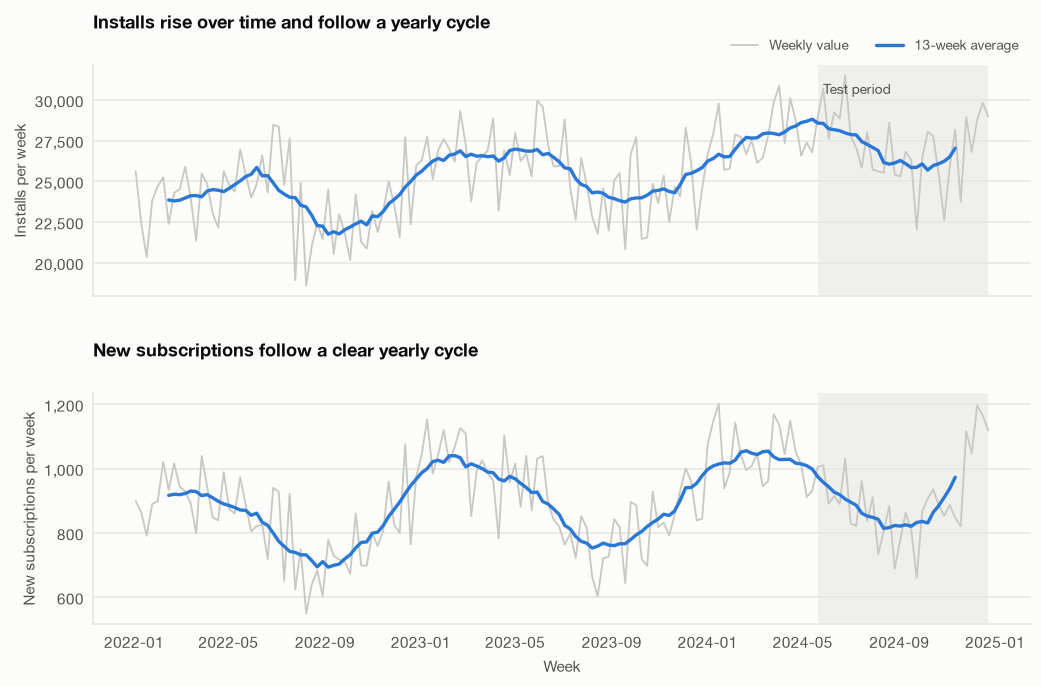

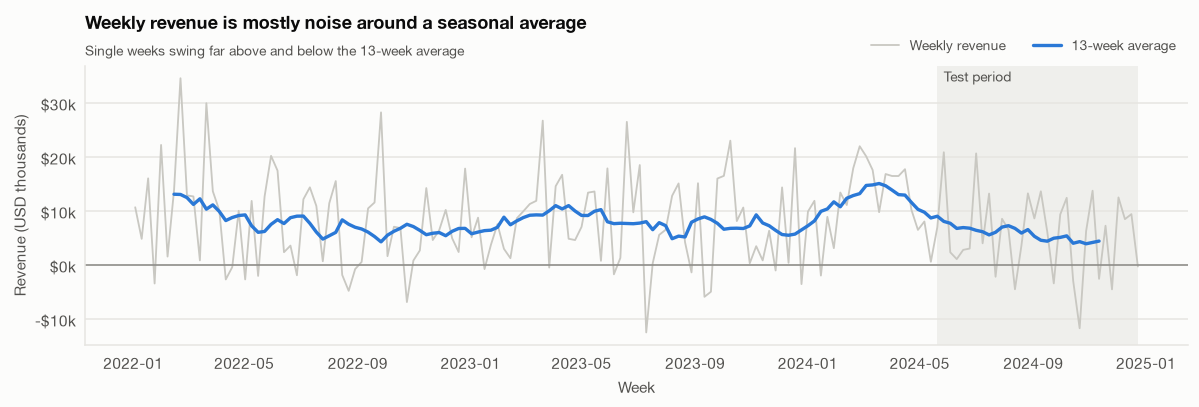

In [42]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.6), sharex=True, gridspec_kw={'hspace': 0.42})
for ax, series, label, title in [
    (axes[0], installs, 'Installs per week', 'Installs rise over time and follow a yearly cycle'),
    (axes[1], new_subs, 'New subscriptions per week', 'New subscriptions follow a clear yearly cycle'),
]:
    ax.axvspan(mmm.index[SPLIT], mmm.index[-1], color=COLORS['grid'], alpha=0.55, lw=0)
    ax.plot(series.index, series, color=COLORS['neutral'], lw=1.2, label='Weekly value')
    ax.plot(series.index, series.rolling(13, center=True).mean(), color=COLORS['blue'], lw=2.2, label='13-week average')
    ax.set_ylabel(label)
    ax.yaxis.set_major_formatter(lambda v, _: f'{v:,.0f}')
    ax.grid(axis='x', visible=False)
    ax.set_title(title)
axes[0].text(
    mmm.index[SPLIT] + pd.Timedelta(days=7),
    axes[0].get_ylim()[1] * 0.97,
    'Test period',
    fontsize=9,
    color=COLORS['text_2'],
    va='top',
)
axes[0].legend(loc='lower right', bbox_to_anchor=(1, 1.0), ncol=2)
axes[1].set_xlabel('Week')
plt.show()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.axvspan(mmm.index[SPLIT], mmm.index[-1], color=COLORS['grid'], alpha=0.55, lw=0)
ax.plot(revenue.index, revenue / 1000, color=COLORS['neutral'], lw=1.2, label='Weekly revenue')
ax.plot(
    revenue.index, revenue.rolling(13, center=True).mean() / 1000, color=COLORS['blue'], lw=2.2, label='13-week average'
)
ax.axhline(0, color=COLORS['muted'], lw=1)
ax.text(
    mmm.index[SPLIT] + pd.Timedelta(days=7), ax.get_ylim()[1] * 0.92, 'Test period', fontsize=9, color=COLORS['text_2']
)
ax.set_xlabel('Week')
ax.set_ylabel('Revenue (USD thousands)')
ax.yaxis.set_major_formatter(lambda v, _: f'-${-v:.0f}k' if v < 0 else f'${v:.0f}k')
ax.grid(axis='x', visible=False)
ax.legend(loc='lower right', bbox_to_anchor=(1, 1.0), ncol=2)
ax.set_title('Weekly revenue is mostly noise around a seasonal average')
subtitle(ax, 'Single weeks swing far above and below the 13-week average')
plt.tight_layout()
plt.show()

**Result:** **The data is complete, and installs and new subscriptions have a clear pattern, but weekly revenue is very noisy, which limits what any model can attribute to a channel.**
- **The data is complete:** 156 weeks with 0 missing values, split into 124 train and 32 test weeks.
- **Installs and new subscriptions have a clear pattern:** installs follow a yearly cycle around a rising trend, and new subscriptions follow a yearly cycle. Revenue shows neither as clearly.
- **Revenue is noisy:** autocorrelation is 0.47 for installs and 0.61 for new subscriptions, vs. 0.03 for revenue. The revenue SD of \$8,362 exceeds its mean of \$8,022, and 28 weeks are negative, with a low of -\$12,457. The data dictionary does not explain negative revenue, so its definition needs confirming with finance.
- **Revenue moves separately from the funnel:** installs and new subscriptions correlate at 0.76, while revenue correlates at 0.07 with installs and 0.13 with new subscriptions.
- **The test period is weaker than training:** mean weekly revenue is \$5,743 vs. \$8,610.
- **Spend is larger than recorded revenue:** spend averages \$18,224 a week, which is \$0.71 per install and \$20.33 per new subscription. Each \$1 of spend sits against \$0.44 of revenue, even crediting all revenue to marketing. This compares weekly figures and excludes any later subscription value.
- **No channel stands out on its own:** same-week correlations with revenue run from -0.09 (email) to +0.06 (social). Search (34.1%) and social (29.5%) take the most budget.

### 4.2 Ridge MMM on all three outcomes

**Purpose:** fit the Ridge MMM on each outcome, then test whether it predicts better than simple models that ignore marketing.

Each outcome gets its own model, because their scale and noise differ. Test MAE alone says little, so each model is compared with the train average and with trend plus seasonality. The second comparison shows what channels add. Time-ordered folds keep future weeks out of training, and mean absolute percentage error (MAPE) is not used because revenue is negative or near zero in some weeks.

`gap_to_reference` is the model's MAE minus the reference model's, so a negative value means the model is better.

In [43]:
YEAR_WEEKS = 52.1775
week_no = (mmm.index - mmm.index[0]).days / 7
controls = pd.DataFrame(
    {
        't': week_no + 1,
        'yearly_sin': np.sin(2 * np.pi * week_no / YEAR_WEEKS),
        'yearly_cos': np.cos(2 * np.pi * week_no / YEAR_WEEKS),
    },
    index=mmm.index,
)
tscv = TimeSeriesSplit(n_splits=5)
ridge_alphas = np.logspace(-2, 3, 30, base=10)
carryovers = np.round(np.arange(0, 0.99, 0.02), 2)
# Blocks keep neighbouring weeks together, so bootstrap resamples preserve autocorrelation
Y_BLOCK, MAE_BLOCK, N_BOOT = 8, 4, 1000


def adstock(carryover):
    """Geometric adstock for all five channels: a_t = spend_t + carryover * a_(t-1)."""
    return mmm[spend_cols].ewm(alpha=1 - carryover).sum().rename(columns=lambda c: re.sub('^spend_', 'adstock_', c))


def fit_ridge(X, y):
    """Ridge fit on the training weeks; the penalty is chosen by time-ordered CV on MAE."""
    pipe = make_pipeline(StandardScaler(), RidgeCV(alphas=ridge_alphas, cv=tscv, scoring='neg_mean_absolute_error'))
    return pipe.fit(X[:SPLIT], y[:SPLIT])


def select_carryover(y, transform=lambda a: a):
    """Lowest time-ordered CV MAE across the carryover grid, using training weeks only."""
    fits = [(c, fit_ridge(transform(adstock(c)).join(controls), y)) for c in carryovers]
    return min(fits, key=lambda f: -f[1][-1].best_score_)


def ridge_coefs(pipe, columns):
    """Coefficients in original units."""
    return pd.Series(pipe[-1].coef_ / pipe[0].scale_, index=columns)


def boot_p(draws):
    """Two-sided bootstrap p-value for a difference from zero, floored at 1/B."""
    draws = np.asarray(draws)
    return np.minimum(1, np.maximum(2 * np.minimum((draws > 0).mean(axis=0), (draws < 0).mean(axis=0)), 1 / len(draws)))


def block_indices(n, block, rng):
    """Moving-block bootstrap positions; blocks keep neighbouring weeks together."""
    starts = rng.integers(0, n - block + 1, n // block + 1)
    return np.concatenate([np.arange(s, s + block) for s in starts])[:n]


def score_models(y, predictions, reference, seed=11):
    """Test MAE and R-squared, with paired block-bootstrap CIs for each model's MAE gap to the reference."""
    y_test = y[SPLIT:].to_numpy()
    # Same seed and same resampled weeks for every model, so MAE gaps are paired
    rng = np.random.default_rng(seed)
    draws = [block_indices(len(y_test), MAE_BLOCK, rng) for _ in range(2 * N_BOOT)]
    errors = {name: np.abs(y_test - pred) for name, pred in predictions.items()}
    rows = {}
    for name, err in errors.items():
        maes = np.array([err[i].mean() for i in draws])
        gaps = np.array([(err[i] - errors[reference][i]).mean() for i in draws])
        same = name == reference
        rows[name] = {
            'test_mae': err.mean(),
            'ci_95_low': np.quantile(maes, 0.025),
            'ci_95_high': np.quantile(maes, 0.975),
            'test_r2': 1 - ((y_test - predictions[name]) ** 2).sum() / ((y_test - y_test.mean()) ** 2).sum(),
            'gap_to_reference': np.nan if same else err.mean() - errors[reference].mean(),
            'gap_ci_low': np.nan if same else np.quantile(gaps, 0.025),
            'gap_ci_high': np.nan if same else np.quantile(gaps, 0.975),
            'p_value': np.nan if same else boot_p(gaps),
        }
    return pd.DataFrame(rows).T.rename_axis('model')

In [44]:
inst_carryover, inst_mmm = select_carryover(installs)
sub_carryover, sub_mmm = select_carryover(new_subs)
best_carryover, ridge_mmm = select_carryover(revenue)
X_inst = adstock(inst_carryover).join(controls)
X_subs = adstock(sub_carryover).join(controls)
X_mmm = adstock(best_carryover).join(controls)
best_alpha = ridge_mmm[-1].alpha_

outcome_fits = {
    'Installs': (installs, inst_carryover, inst_mmm, X_inst),
    'New subscriptions': (new_subs, sub_carryover, sub_mmm, X_subs),
    'Revenue (USD)': (revenue, best_carryover, ridge_mmm, X_mmm),
}

settings = pd.DataFrame(
    {
        name: {
            'Selected carryover': f'{c:.2f}',
            'Carryover half-life (weeks)': f'{np.log(0.5) / np.log(c):.1f}' if c > 0 else 'None',
            'Selected Ridge penalty (alpha)': f'{pipe[-1].alpha_:.2f}',
            'Cross-validated MAE (training weeks)': f'{-pipe[-1].best_score_:,.1f}',
        }
        for name, (_, c, pipe, _) in outcome_fits.items()
    }
)
display(mark(settings.style, [(None, None)], title='Ridge MMM settings selected on training weeks, by outcome'))

,Installs,New subscriptions,Revenue (USD)
Selected carryover,0.00,0.00,0.94
Carryover half-life (weeks),None,None,11.2
Selected Ridge penalty (alpha),8.53,0.36,18.87
Cross-validated MAE (training weeks),"1,981.3",83.1,"6,532.9"


In [45]:
season_cols = ['yearly_sin', 'yearly_cos']
outcome_preds = {
    name: {
        'Train average': np.full(len(mmm) - SPLIT, y[:SPLIT].mean()),
        'Seasonality only': fit_ridge(controls[season_cols], y).predict(controls[season_cols][SPLIT:]),
        'Trend + seasonality': fit_ridge(controls, y).predict(controls[SPLIT:]),
        'Ridge MMM': pipe.predict(X[SPLIT:]),
    }
    for name, (y, _, pipe, X) in outcome_fits.items()
}
score_format = {
    'test_mae': '{:,.1f}',
    'ci_95_low': '{:,.1f}',
    'ci_95_high': '{:,.1f}',
    'test_r2': '{:.3f}',
    'gap_to_reference': '{:+,.1f}',
    'gap_ci_low': '{:+,.1f}',
    'gap_ci_high': '{:+,.1f}',
    'p_value': '{:.3f}',
}

accuracy_table = pd.concat(
    {name: score_models(outcome_fits[name][0], preds, 'Train average') for name, preds in outcome_preds.items()},
    names=['outcome'],
)
ridge_rows = accuracy_table.index[accuracy_table.index.get_level_values('model') == 'Ridge MMM']
display(
    mark(
        accuracy_table.style.format(score_format, na_rep='–'),
        [(None, ['test_mae', 'test_r2', 'p_value']), (ridge_rows, None)],
        title='Test-period accuracy by outcome, compared with always predicting the train average',
    )
)

channel_gain = pd.DataFrame(
    {
        name: score_models(outcome_fits[name][0], preds, 'Trend + seasonality').loc['Ridge MMM']
        for name, preds in outcome_preds.items()
    }
).T.rename_axis('outcome')
display(
    mark(
        channel_gain[['gap_to_reference', 'gap_ci_low', 'gap_ci_high', 'p_value']].style.format(score_format),
        [(None, None)],
        title='Do channels add accuracy? Ridge MMM compared with trend + seasonality, by outcome',
    )
)

,gap_to_reference,gap_ci_low,gap_ci_high,p_value
outcome,,,,
Installs,-15.7,-100.1,+42.2,0.510
New subscriptions,+1.7,-3.3,+6.8,0.578
Revenue (USD),+206.5,-69.2,+431.3,0.135


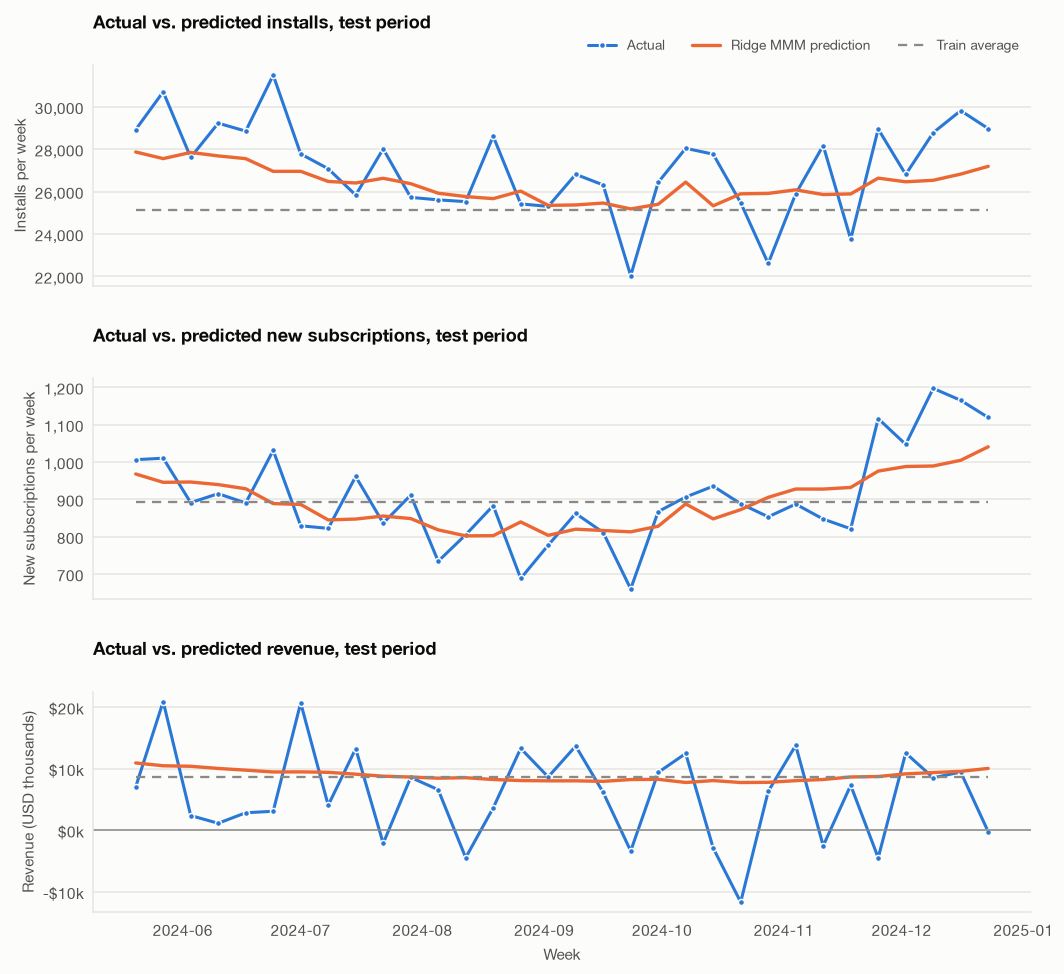

In [46]:
test_index = mmm.index[SPLIT:]
outcome_panels = [
    ('Installs', 1, 'Installs per week', lambda v, _: f'{v:,.0f}'),
    ('New subscriptions', 1, 'New subscriptions per week', lambda v, _: f'{v:,.0f}'),
    ('Revenue (USD)', 1000, 'Revenue (USD thousands)', lambda v, _: f'-${-v:.0f}k' if v < 0 else f'${v:.0f}k'),
]


def plot_test_fit(main_model, main_label, reference_model, reference_label):
    """Actual vs. predicted test weeks for all three outcomes, with one comparison series."""
    fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True, gridspec_kw={'hspace': 0.42})
    for ax, (name, scale, label, tick) in zip(axes, outcome_panels):
        actual = outcome_fits[name][0][SPLIT:] / scale
        ax.plot(
            test_index,
            actual,
            color=COLORS['blue'],
            lw=2,
            marker='o',
            ms=4,
            mec=COLORS['surface'],
            mew=1,
            label='Actual',
        )
        ax.plot(test_index, main_model[name] / scale, color=COLORS['orange'], lw=2.2, label=main_label)
        ax.plot(
            test_index,
            reference_model[name] / scale,
            color=COLORS['muted'],
            lw=1.5,
            ls=(0, (4, 3)),
            label=reference_label,
        )
        ax.set_ylabel(label)
        ax.yaxis.set_major_formatter(tick)
        ax.grid(axis='x', visible=False)
        ax.set_title(f"Actual vs. predicted {name.replace(' (USD)', '').lower()}, test period")
    axes[2].axhline(0, color=COLORS['muted'], lw=1)
    axes[0].legend(loc='lower right', bbox_to_anchor=(1, 1.0), ncol=3)
    axes[2].set_xlabel('Week')
    plt.show()


plot_test_fit(
    {name: preds['Ridge MMM'] for name, preds in outcome_preds.items()},
    'Ridge MMM prediction',
    {name: preds['Train average'] for name, preds in outcome_preds.items()},
    'Train average',
)

**Result:** **The Ridge MMM significantly beats the train average only on installs, and channels add no significant forecast accuracy on any outcome.**
- **Selected settings:** installs and new subscriptions both select a carryover of 0.00, with penalties of 8.53 and 0.36. Revenue selects a carryover of 0.94, a half-life of 11.2 weeks, and a penalty of 18.87. At that carryover, adstock smooths spend heavily and ramps up from the start of the data, so it mostly tracks slow movement rather than weekly campaigns (4.3).
- **Installs:** test MAE is 1,517.5, a gap of -917.6 [-1,374.2, -280.5] to the train average of 2,435.1 (p = 0.001). Test $R^2$ is 0.200.
- **New subscriptions:** test MAE is 71.1, a gap of -23.6 [-41.1, +5.1] to the train average of 94.7 (p = 0.138). Test $R^2$ is 0.520.
- **Revenue:** test MAE is \$6,378, a gap of +\$174 [-\$112, +\$409] to the train average of \$6,204 (p = 0.384). Test $R^2$ is -0.156. No model significantly beats the train average: seasonality only reaches \$6,100 (p = 0.573) and trend plus seasonality \$6,172 (p = 0.679).
- **Trend and seasonality do the work, not channels:** they alone reach a test $R^2$ of 0.181 for installs and 0.533 for new subscriptions, vs. -0.064 for revenue. Adding channels changes MAE by -15.7 [-100.1, +42.2] installs (p = 0.510), +1.7 [-3.3, +6.8] new subscriptions (p = 0.578) and +\$206.5 [-\$69.2, +\$431.3] of revenue (p = 0.135).
- **The charts show the same pattern:** predictions follow the seasonal shape of installs and new subscriptions, but miss individual weeks and the jump in new subscriptions at the end of the test period. The revenue prediction stays smooth while actual revenue swings week to week.

### 4.3 Directional channel summary

**Purpose:** rank the channels and test how far that ranking can be trusted, because budget decisions need more than a list of coefficients.

Coefficients are converted to effect per dollar of spend, because adstock coefficients are not in spend units: `return_per_usd` is $\beta_k/(1-c)$, and \$1.00 is break-even on revenue alone. The rest of the code tests the ranking in five ways:
- **Bootstrap CIs and p-values** show whether each estimate is distinguishable from zero. `p_bonferroni` adjusts for testing five channels on each outcome.
- **Other carryovers** show whether a channel's direction depends on one setting.
- **Other outcomes** show whether installs, new subscriptions and revenue tell the same story.
- **Adstock start** shows whether the results depend on assuming no spend before week 1. Under that assumption high-carryover series all ramp up together, so the check also starts each series as if spend had already run at its training mean.
- **Joint tests** ask whether the channels matter as a group. `placebo_p` is added because a HAC F-test can reject too often in a sample this size. It slides the spend history against the outcome by every possible number of weeks, which breaks any real link but keeps the shape of spend, and reports the share of shifts with an F-statistic at least as large.

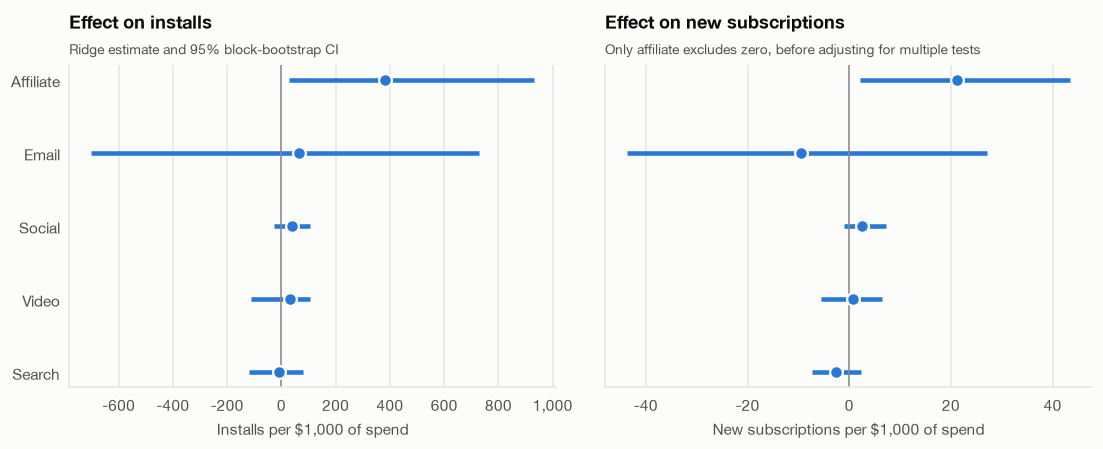

In [47]:
# Channel effects: funnel outcomes first, then revenue, then agreement across outcomes
channel_rows = [f'adstock_{c}' for c in channel_names]


def channel_effects(y, pipe, X, carryover, seed=42):
    """Ridge outcome per $1,000 of spend for each channel, with block-bootstrap CIs and p-values."""
    rng = np.random.default_rng(seed)
    draws = []
    for _ in range(N_BOOT):
        idx = block_indices(SPLIT, Y_BLOCK, rng)
        boot_pipe = make_pipeline(StandardScaler(), Ridge(alpha=pipe[-1].alpha_)).fit(X.iloc[idx], y.iloc[idx])
        draws.append(ridge_coefs(boot_pipe, X.columns))
    draws = pd.DataFrame(draws)
    # Long-run multiplier: $1 of spend creates 1 / (1 - c) units of adstock
    scale = 1000 / (1 - carryover)
    p_values = boot_p(draws[channel_rows])
    return pd.DataFrame(
        {
            'per_1000_usd': ridge_coefs(pipe, X.columns)[channel_rows].to_numpy() * scale,
            'ci_95_low': draws[channel_rows].quantile(0.025).to_numpy() * scale,
            'ci_95_high': draws[channel_rows].quantile(0.975).to_numpy() * scale,
            'p_value': p_values,
            'p_bonferroni': np.minimum(1, p_values * len(channel_rows)),
        },
        index=pd.Index(channel_names, name='channel'),
    ).sort_values('per_1000_usd', ascending=False)


funnel_effects = pd.concat(
    {
        'Installs': channel_effects(installs, inst_mmm, X_inst, inst_carryover),
        'New subscriptions': channel_effects(new_subs, sub_mmm, X_subs, sub_carryover),
    },
    names=['outcome'],
)
display(
    mark(
        funnel_effects.style.format(
            {
                'per_1000_usd': '{:+.2f}',
                'ci_95_low': '{:+.2f}',
                'ci_95_high': '{:+.2f}',
                'p_value': '{:.3f}',
                'p_bonferroni': '{:.3f}',
            }
        ),
        [(None, None)],
        title='Ridge MMM on funnel outcomes: installs and new subscriptions per $1,000 of spend',
    )
)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True, gridspec_kw={'wspace': 0.1})
channel_order = list(funnel_effects.loc['Installs'].index[::-1])
ypos = np.arange(len(channel_order))
for ax, outcome, xlabel in zip(
    axes,
    ['Installs', 'New subscriptions'],
    [r'Installs per \$1,000 of spend', r'New subscriptions per \$1,000 of spend'],
):
    r = funnel_effects.loc[outcome].loc[channel_order]
    forest(ax, r['per_1000_usd'], r['ci_95_low'], r['ci_95_high'], ypos)
    ax.xaxis.set_major_formatter(lambda v, _: f'{v:,.0f}')
    ax.set_xlabel(xlabel)
    ax.grid(axis='y', visible=False)
    ax.set_title(f'Effect on {outcome.lower()}')
axes[0].set_yticks(ypos, [ch.capitalize() for ch in channel_order])
subtitle(axes[0], 'Ridge estimate and 95% block-bootstrap CI')
subtitle(axes[1], 'Only affiliate excludes zero, before adjusting for multiple tests')
plt.show()

In [48]:
coef_mmm = ridge_coefs(ridge_mmm, X_mmm.columns)
boot_rng = np.random.default_rng(42)
boot_coefs = []
for _ in range(N_BOOT):
    idx = block_indices(SPLIT, Y_BLOCK, boot_rng)
    pipe = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha)).fit(X_mmm.iloc[idx], revenue.iloc[idx])
    boot_coefs.append(ridge_coefs(pipe, X_mmm.columns))
boot_coefs = pd.DataFrame(boot_coefs)

mmm_coef_table = pd.DataFrame(
    {
        'coefficient': coef_mmm,
        'ci_95_low': boot_coefs.quantile(0.025),
        'ci_95_high': boot_coefs.quantile(0.975),
        'p_value': boot_p(boot_coefs),
    }
)
display(
    mark(
        mmm_coef_table.style.format(
            {'coefficient': '{:+.3f}', 'ci_95_low': '{:+.3f}', 'ci_95_high': '{:+.3f}', 'p_value': '{:.3f}'}
        ),
        [(['yearly_sin'], None)],
        title='Ridge MMM coefficients with bootstrap 95% CIs and p-values, in USD per unit of each feature',
    )
)

return_table = mmm_coef_table.loc[channel_rows, ['coefficient', 'ci_95_low', 'ci_95_high']] / (1 - best_carryover)
return_table.columns = ['return_per_usd', 'ci_95_low', 'ci_95_high']
return_table.index = pd.Index(channel_names, name='channel')
return_table['p_value'] = mmm_coef_table.loc[channel_rows, 'p_value'].to_numpy()
return_table = return_table.sort_values('return_per_usd', ascending=False)
return_table.insert(0, 'rank', range(1, len(return_table) + 1))
display(
    mark(
        return_table.style.format(
            {'return_per_usd': '{:+.2f}', 'ci_95_low': '{:+.2f}', 'ci_95_high': '{:+.2f}', 'p_value': '{:.3f}'}
        ),
        [(None, None)],
        title='Directional channel ranking: long-run revenue per $1 of spend',
    )
)

,coefficient,ci_95_low,ci_95_high,p_value
adstock_search,+0.038,-0.035,+0.116,0.294
adstock_social,-0.010,-0.050,+0.039,0.758
adstock_video,-0.027,-0.125,+0.054,0.328
adstock_affiliate,-0.034,-0.297,+0.256,0.758
adstock_email,-0.288,-0.909,+0.326,0.180
t,+25.245,-8.229,+72.476,0.124
yearly_sin,+1968.058,-74.355,+3748.828,0.062
yearly_cos,+557.310,-972.383,+1943.138,0.556


,rank,return_per_usd,ci_95_low,ci_95_high,p_value
channel,,,,,
search,1,+0.64,-0.58,+1.93,0.294
social,2,-0.17,-0.84,+0.64,0.758
video,3,-0.44,-2.08,+0.89,0.328
affiliate,4,-0.57,-4.95,+4.27,0.758
email,5,-4.80,-15.14,+5.44,0.180


In [49]:
check_carryovers = [0.0, 0.3, 0.5, 0.7, 0.9, best_carryover]
sign_check = pd.DataFrame(
    {
        f'carryover {c:.2f}': ridge_coefs(fit_ridge(adstock(c).join(controls), revenue), X_mmm.columns)[
            channel_rows
        ].to_numpy()
        / (1 - c)
        for c in check_carryovers
    },
    index=pd.Index(channel_names, name='channel'),
)
sign_check = sign_check.loc[return_table.index]
sign_check['same_sign'] = np.where((sign_check > 0).all(axis=1) | (sign_check < 0).all(axis=1), 'Yes', 'No')
display(
    mark(
        sign_check.style.format('{:+.3f}', subset=sign_check.columns[:-1]),
        [(None, None)],
        title='Does each channel keep its direction at a different carryover? Revenue per $1 of spend',
    )
)

joint_rows = {}
for c in sorted({0.0, 0.5, best_carryover}):
    ols_full = sm.OLS(revenue, sm.add_constant(adstock(c).join(controls))).fit(cov_type='HAC', cov_kwds={'maxlags': 4})
    ols_base = sm.OLS(revenue, sm.add_constant(controls)).fit()
    joint = ols_full.f_test(np.eye(len(ols_full.params))[1:6])
    joint_rows[f'{c:.2f}'] = {
        'r2_controls_only': ols_base.rsquared,
        'r2_with_channels': ols_full.rsquared,
        'f_statistic': float(np.squeeze(joint.fvalue)),
        'p_value': float(joint.pvalue),
    }
joint_table = pd.DataFrame(joint_rows).T.rename_axis('carryover')
display(
    mark(
        joint_table.style.format(
            {'r2_controls_only': '{:.3f}', 'r2_with_channels': '{:.3f}', 'f_statistic': '{:.2f}', 'p_value': '{:.3f}'}
        ),
        [(None, ['p_value']), ([f'{best_carryover:.2f}'], ['r2_controls_only', 'r2_with_channels'])],
        title='Joint test that all five channels have zero effect on revenue (OLS with HAC errors, all weeks)',
    )
)

,carryover 0.00,carryover 0.30,carryover 0.50,carryover 0.70,carryover 0.90,carryover 0.94,same_sign
channel,,,,,,,
search,+0.035,+0.088,+0.279,+0.511,+0.794,+0.640,Yes
social,+0.012,-0.002,-0.040,-0.105,-0.198,-0.173,No
video,+0.038,+0.016,+0.002,-0.121,-0.434,-0.444,No
affiliate,-0.123,-0.162,-0.510,-0.480,-0.277,-0.568,Yes
email,-0.335,-0.698,-2.444,-4.764,-6.123,-4.798,Yes


,r2_controls_only,r2_with_channels,f_statistic,p_value
carryover,,,,
0.00,0.062,0.082,1.43,0.217
0.50,0.062,0.097,1.64,0.153
0.94,0.062,0.091,1.28,0.275


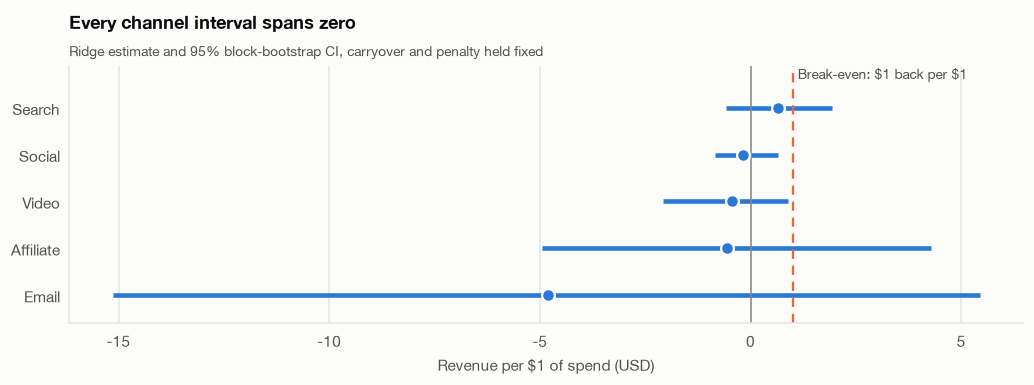

In [50]:
fig, ax = plt.subplots(figsize=(9.5, 3.6))
order = return_table.iloc[::-1]
ypos = np.arange(len(order))
forest(ax, order['return_per_usd'], order['ci_95_low'], order['ci_95_high'], ypos)
ax.axvline(1, color=COLORS['orange'], lw=1.5, ls=(0, (4, 3)))
ax.text(1.12, len(order) - 0.45, r'Break-even: \$1 back per \$1', fontsize=9, color=COLORS['text_2'], va='bottom')
ax.set_yticks(ypos, [c.capitalize() for c in order.index])
ax.set_ylim(-0.6, len(order) - 0.1)
ax.set_xlabel(r'Revenue per \$1 of spend (USD)')
ax.grid(axis='y', visible=False)
ax.set_title('Every channel interval spans zero')
subtitle(ax, 'Ridge estimate and 95% block-bootstrap CI, carryover and penalty held fixed')
plt.tight_layout()
plt.show()

In [51]:
sign_of = lambda v: np.where(v > 0, '+', '-')
sign_table = pd.DataFrame(
    {
        'installs': sign_of(funnel_effects.loc['Installs'].loc[channel_names, 'per_1000_usd']),
        'new_subscriptions': sign_of(funnel_effects.loc['New subscriptions'].loc[channel_names, 'per_1000_usd']),
        'revenue': sign_of(return_table.loc[channel_names, 'return_per_usd']),
    },
    index=pd.Index(channel_names, name='channel'),
)
sign_table['all_agree'] = np.where(sign_table.nunique(axis=1).eq(1), 'Yes', 'No')
display(mark(sign_table.style, [(None, None)], title='Direction of each channel across the three outcomes'))

,installs,new_subscriptions,revenue,all_agree
channel,,,,
search,-,-,+,No
social,+,+,-,No
video,+,+,-,No
affiliate,+,+,-,No
email,+,-,-,No


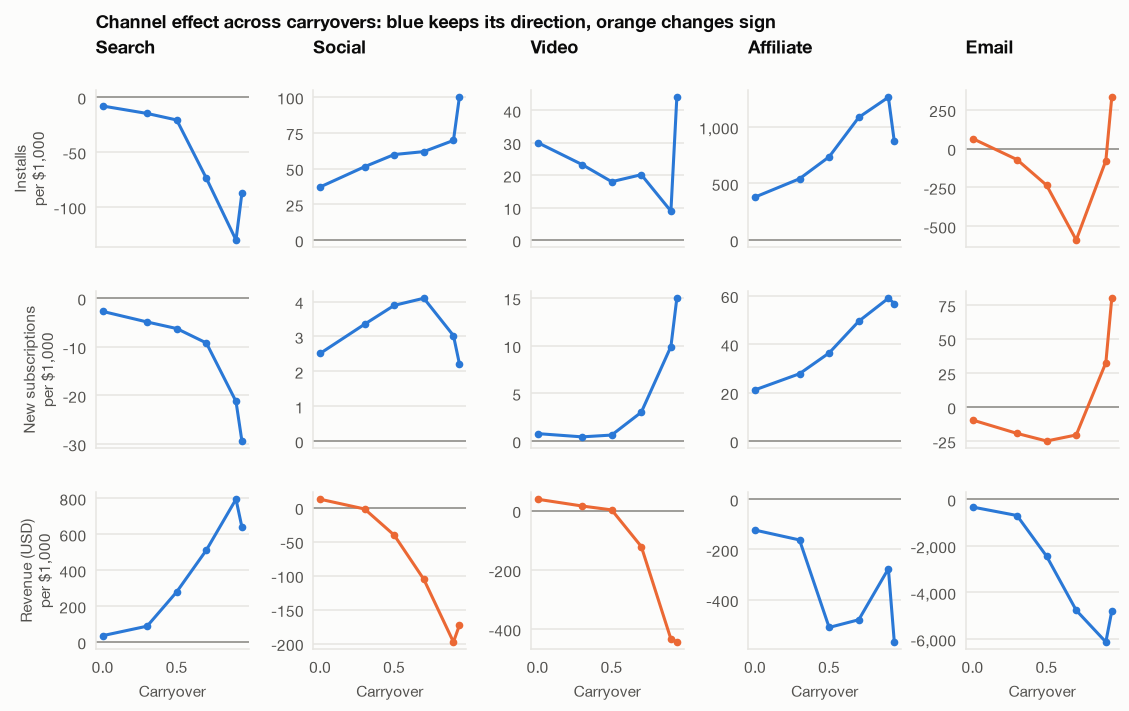

In [52]:
# The two revenue checks from 4.3, run on every outcome with the same settings so the results compare directly
outcome_series = {'Installs': installs, 'New subscriptions': new_subs, 'Revenue (USD)': revenue}


def effect_per_1000(y, carryover):
    """Ridge effect per $1,000 of spend at a fixed carryover; the penalty is re-chosen on training weeks."""
    X = adstock(carryover).join(controls)
    return ridge_coefs(fit_ridge(X, y), X.columns)[channel_rows].to_numpy() * 1000 / (1 - carryover)


sensitivity = pd.concat(
    {
        name: pd.DataFrame(
            {f'carryover {c:.2f}': effect_per_1000(y, c) for c in check_carryovers},
            index=pd.Index(channel_names, name='channel'),
        )
        for name, y in outcome_series.items()
    },
    names=['outcome'],
)
sensitivity['same_sign'] = np.where((sensitivity > 0).all(axis=1) | (sensitivity < 0).all(axis=1), 'Yes', 'No')
display(
    mark(
        sensitivity.style.format('{:+.2f}', subset=sensitivity.columns[:-1]),
        [(None, ['same_sign'])],
        title='Does each channel keep its direction at a different carryover? Outcome per $1,000 of spend',
    )
)


def hac_f(y, spend):
    """HAC F-statistic that all five channels are zero, beyond trend and seasonality."""
    X = sm.add_constant(spend.join(controls))
    fit = sm.OLS(y, X).fit(cov_type='HAC', cov_kwds={'maxlags': 4})
    return fit, fit.f_test(np.eye(X.shape[1])[1:6])  # positions 1-5 are the channels, after the constant


def joint_channel_test(y, carryover):
    """Joint test on all weeks, plus a placebo p-value from sliding spend against the outcome by every shift."""
    spend = adstock(carryover)
    fit, test = hac_f(y, spend)
    observed = float(np.squeeze(test.fvalue))
    placebo = [
        float(
            np.squeeze(
                hac_f(y, pd.DataFrame(np.roll(spend.to_numpy(), s, axis=0), index=spend.index, columns=spend.columns))[
                    1
                ].fvalue
            )
        )
        for s in range(1, len(y))
    ]
    return {
        'r2_controls_only': sm.OLS(y, sm.add_constant(controls)).fit().rsquared,
        'r2_with_channels': fit.rsquared,
        'r2_gain': fit.rsquared - sm.OLS(y, sm.add_constant(controls)).fit().rsquared,
        'f_statistic': observed,
        'p_value': float(test.pvalue),
        'placebo_p': (1 + sum(f >= observed for f in placebo)) / len(y),
    }


joint_all = pd.concat(
    {
        name: pd.DataFrame({f'{c:.2f}': joint_channel_test(y, c) for c in sorted({0.0, 0.5, best_carryover})}).T
        for name, y in outcome_series.items()
    },
    names=['outcome', 'carryover'],
)
display(
    mark(
        joint_all.style.format(
            {
                'r2_controls_only': '{:.3f}',
                'r2_with_channels': '{:.3f}',
                'r2_gain': '{:.3f}',
                'f_statistic': '{:.2f}',
                'p_value': '{:.3f}',
                'placebo_p': '{:.3f}',
            }
        ),
        [(None, ['r2_gain', 'p_value', 'placebo_p'])],
        title='Joint test that all five channels have zero effect, by outcome (OLS with HAC errors, all weeks)',
    )
)

fig, axes = plt.subplots(3, 5, figsize=(12, 6.6), sharex=True, gridspec_kw={'wspace': 0.42, 'hspace': 0.28})
x = np.array(check_carryovers, dtype=float)
for row, outcome in zip(axes, outcome_series):
    for ax, ch in zip(row, channel_names):
        r = sensitivity.loc[(outcome, ch)]
        values = r.drop('same_sign').astype(float).to_numpy()
        ax.axhline(0, color=COLORS['muted'], lw=1)
        ax.plot(
            x, values, color=COLORS['blue'] if r['same_sign'] == 'Yes' else COLORS['orange'], lw=2, marker='o', ms=4
        )
        ax.yaxis.set_major_formatter(lambda v, _: f'{v:,.0f}')
        ax.grid(axis='x', visible=False)
    row[0].set_ylabel(f'{outcome}\nper \\$1,000')
for ax, ch in zip(axes[0], channel_names):
    ax.set_title(ch.capitalize())
for ax in axes[-1]:
    ax.set_xlabel('Carryover')
fig.suptitle(
    'Channel effect across carryovers: blue keeps its direction, orange changes sign',
    x=0.125,
    y=0.99,
    ha='left',
    fontsize=12,
    fontweight='bold',
)
plt.show()

In [53]:
# The adstock recursion starts from zero history, so high-carryover series all ramp up together in the early weeks.
# This check removes that ramp to see which conclusions depend on the start-up assumption.
def steady_state_adstock(carryover):
    """Adstock if spend before week 1 had run at its training-week mean, which removes the start-up ramp."""
    prior_stock = mmm[spend_cols].iloc[:SPLIT].mean().to_numpy() / (1 - carryover)
    return adstock(carryover) + np.outer(carryover ** (np.arange(len(mmm)) + 1), prior_stock)


def channel_correlation_range(series):
    """Lowest and highest pairwise correlation between channels on training weeks."""
    corr = series.iloc[:SPLIT].corr().to_numpy()
    pairs = corr[np.triu_indices_from(corr, k=1)]
    return f'{pairs.min():+.2f} to {pairs.max():+.2f}'


weeks_to_steady_state = int(np.ceil(np.log(0.05) / np.log(best_carryover)))
show_facts(
    {
        f'Weeks to reach 95% of steady state at carryover {best_carryover:.2f}': f'{weeks_to_steady_state}',
        'Training weeks': f'{SPLIT}',
        'Pairwise channel correlation, raw spend': channel_correlation_range(mmm[spend_cols]),
        'Pairwise channel correlation, adstock from zero history': channel_correlation_range(adstock(best_carryover)),
        'Pairwise channel correlation, adstock with no ramp': channel_correlation_range(
            steady_state_adstock(best_carryover)
        ),
    },
    f'Start-up ramp at the revenue carryover of {best_carryover:.2f}',
)

start_rows = {}
for name, (y, base_c, base_pipe, X_base) in outcome_fits.items():
    fits = [(c, fit_ridge(steady_state_adstock(c).join(controls), y)) for c in carryovers]
    steady_c, steady_pipe = min(fits, key=lambda f: -f[1][-1].best_score_)
    X_steady = steady_state_adstock(steady_c).join(controls)
    base_effect = pd.Series(
        ridge_coefs(base_pipe, X_base.columns)[channel_rows].to_numpy() / (1 - base_c), channel_names
    )
    steady_effect = pd.Series(
        ridge_coefs(steady_pipe, X_steady.columns)[channel_rows].to_numpy() / (1 - steady_c), channel_names
    )
    start_rows[name] = {
        'carryover, zero history': f'{base_c:.2f}',
        'carryover, no ramp': f'{steady_c:.2f}',
        'top channel, zero history': base_effect.idxmax(),
        'top channel, no ramp': steady_effect.idxmax(),
        'bottom channel, zero history': base_effect.idxmin(),
        'bottom channel, no ramp': steady_effect.idxmin(),
    }
display(
    mark(
        pd.DataFrame(start_rows).T.rename_axis('outcome').style,
        [(None, None)],
        title='Selected carryover and channel ranking under each adstock start',
    )
)

,value
Weeks to reach 95% of steady state at carryover 0.94,49
Training weeks,124
"Pairwise channel correlation, raw spend",-0.20 to +0.14
"Pairwise channel correlation, adstock from zero history",+0.81 to +0.95
"Pairwise channel correlation, adstock with no ramp",-0.22 to +0.55


,"carryover, zero history","carryover, no ramp","top channel, zero history","top channel, no ramp","bottom channel, zero history","bottom channel, no ramp"
outcome,,,,,,
Installs,0.00,0.34,affiliate,affiliate,search,email
New subscriptions,0.00,0.00,affiliate,affiliate,email,email
Revenue (USD),0.94,0.98,search,search,email,email


**Result:** **Affiliate is the strongest lead on installs and new subscriptions and search ranks first on revenue, but neither is significant after adjusting for multiple tests, and the three outcomes disagree on direction.**

**MMM results are correlational (directional), not causal.**

- **Installs and new subscriptions:** affiliate leads at +380.00 [+28.38, +931.60] installs and +21.12 [+2.12, +43.41] new subscriptions per \$1,000 (both p = 0.032, and 0.160 after adjusting for five tests on each outcome). The two results are not independent evidence, because the outcomes move together.
- **Revenue ranking:** search +\$0.64 [-\$0.58, +\$1.93], p = 0.294; social -\$0.17 [-\$0.84, +\$0.64], p = 0.758; video -\$0.44 [-\$2.08, +\$0.89], p = 0.328; affiliate -\$0.57 [-\$4.95, +\$4.27], p = 0.758; email -\$4.80 [-\$15.14, +\$5.44], p = 0.180. The negative estimates should not be read as spend destroying revenue: -\$4.80 per \$1 is not plausible for email, and points to noise.
- **Direction depends on the outcome and the carryover:** at each outcome's selected carryover (0.00 for installs and new subscriptions, 0.94 for revenue), no channel has the same direction on all three outcomes. Across carryovers from 0.00 to 0.94, search and affiliate are the firm split: search stays negative on installs and new subscriptions and positive on revenue (+\$0.04 to +\$0.79), and affiliate the reverse. Email stays negative on revenue but changes sign on installs and new subscriptions. Social and video stay positive on installs and new subscriptions but change sign on revenue, so they cannot be ranked there. They agree on all three outcomes at low carryover, so their split comes from the higher carryover selected for revenue.
- **The adstock start changes the settings, not the leaders:** at a carryover of 0.94, a series needs 49 of the 124 training weeks to reach 95% of steady state. That shared ramp is part of why pairwise channel correlations rise from -0.20 to +0.14 in raw spend to +0.81 to +0.95 in adstock, vs. -0.22 to +0.55 without it. Starting at steady state moves the selected carryover from 0.94 to 0.98 on revenue, the top of the grid, so revenue carryover is not identified without the ramp, and from 0.00 to 0.34 on installs. Search stays first and email last on revenue, and affiliate stays first on installs and new subscriptions.
- **Seasonality does not clear 5% on revenue:** the `yearly_sin` coefficient is +\$1,968 [-\$74, +\$3,749] (p = 0.062).
- **The joint tests do not support the channels as a group:** across the three carryovers tested, HAC p-values are 0.018 to 0.092 for installs, 0.016 to 0.042 for new subscriptions and 0.153 to 0.275 for revenue. The lower values do not hold up: spend shifted to unrelated weeks gives an F-statistic this large often enough that `placebo_p` is 0.308 to 0.359 for installs, 0.154 to 0.263 for new subscriptions and 0.365 to 0.462 for revenue. Channels add at most 0.032 and 0.026 to in-sample $R^2$ on installs and new subscriptions, and lift it only from 0.062 to 0.091 on revenue at the selected carryover.

### 4.4 Ridge MMM with channel-specific carryover

**Purpose:** test whether one shared carryover is hiding real differences between channels, because a video campaign may last longer than a search click.

Section 4.2 uses one carryover for all channels. Here each channel gets its own, on all three outcomes, so adstock becomes:

$$
a_{k,t} = s_{k,t} + c_k\,a_{k,t-1}
$$

The effect per \$1 of spend becomes $\beta_k/(1-c_k)$. Selection runs on training weeks only: starting from the shared carryover, it changes one channel at a time across a grid of values, keeps a change only if cross-validated MAE improves, and repeats for three passes. CIs and p-values use the same method as sections 4.2 and 4.3, with carryovers and penalty held fixed, so they ignore selection uncertainty and are likely too narrow. Each model is compared with trend plus seasonality and with the shared carryover, because extra settings are only worth keeping if they improve test accuracy.

In [54]:
# Refit each outcome with a separate carryover per channel and test whether it helps
channel_grid = sorted({round(float(c), 2) for c in np.arange(0, 0.99, 0.1)} | {round(float(best_carryover), 2)})


def adstock_by_channel(carryover_by_channel):
    """Geometric adstock with each channel's own carryover."""
    return pd.DataFrame(
        {f'adstock_{ch}': mmm[f'spend_{ch}'].ewm(alpha=1 - c).sum() for ch, c in carryover_by_channel.items()}
    )


def select_channel_carryovers(y, start, passes=3):
    """Coordinate search on training weeks: change one channel's carryover at a time, keeping CV MAE gains."""
    current = {ch: start for ch in channel_names}
    best_fit = fit_ridge(adstock_by_channel(current).join(controls), y)
    for _ in range(passes):
        for ch in channel_names:
            for c in channel_grid:
                trial = current | {ch: c}
                fit = fit_ridge(adstock_by_channel(trial).join(controls), y)
                if fit[-1].best_score_ > best_fit[-1].best_score_:
                    current, best_fit = trial, fit
    return current, best_fit


channel_fits = {}
for name, (y, shared_c, _, _) in outcome_fits.items():
    by_channel, pipe = select_channel_carryovers(y, shared_c)
    channel_fits[name] = (y, by_channel, pipe, adstock_by_channel(by_channel).join(controls))

In [55]:
carryover_table = pd.DataFrame({name: fit[1] for name, fit in channel_fits.items()}).rename_axis('channel')
carryover_table.loc['Shared carryover (4.2)'] = [outcome_fits[name][1] for name in carryover_table.columns]
carryover_table.loc['CV MAE, shared'] = [-outcome_fits[name][2][-1].best_score_ for name in carryover_table.columns]
carryover_table.loc['CV MAE, by channel'] = [-channel_fits[name][2][-1].best_score_ for name in carryover_table.columns]
display(
    mark(
        carryover_table.style.format('{:.2f}').format(
            '{:,.1f}', subset=(['CV MAE, shared', 'CV MAE, by channel'], carryover_table.columns)
        ),
        [(None, None)],
        title='Carryover selected for each channel on training weeks, by outcome',
    )
)

,Installs,New subscriptions,Revenue (USD)
channel,,,
search,0.00,0.00,0.70
social,0.00,0.00,0.90
video,0.90,0.70,0.90
affiliate,0.60,0.60,0.94
email,0.20,0.00,0.94
Shared carryover (4.2),0.00,0.00,0.94
"CV MAE, shared","1,981.3",83.1,"6,532.9"
"CV MAE, by channel","1,815.2",80.7,"6,439.3"


In [56]:
channel_preds = {
    name: outcome_preds[name] | {'Ridge MMM, by channel': fit[2].predict(fit[3][SPLIT:])}
    for name, fit in channel_fits.items()
}
by_channel_scores = pd.concat(
    {
        name: score_models(
            channel_fits[name][0],
            {k: preds[k] for k in ['Trend + seasonality', 'Ridge MMM', 'Ridge MMM, by channel']},
            'Trend + seasonality',
        )
        for name, preds in channel_preds.items()
    },
    names=['outcome'],
)
display(
    mark(
        by_channel_scores.style.format(score_format, na_rep='–'),
        [
            (None, ['test_mae', 'test_r2']),
            (
                by_channel_scores.index[by_channel_scores.index.get_level_values('model') == 'Ridge MMM, by channel'],
                None,
            ),
        ],
        title='Test accuracy with channel-specific carryover, compared with trend + seasonality',
    )
)

shared_gap = pd.DataFrame(
    {
        name: score_models(
            channel_fits[name][0], {k: preds[k] for k in ['Ridge MMM', 'Ridge MMM, by channel']}, 'Ridge MMM'
        ).loc['Ridge MMM, by channel']
        for name, preds in channel_preds.items()
    }
).T.rename_axis('outcome')
display(
    mark(
        shared_gap[['gap_to_reference', 'gap_ci_low', 'gap_ci_high', 'p_value']].style.format(score_format),
        [(None, None)],
        title='Does channel-specific carryover beat one shared carryover? Change in test MAE',
    )
)

channel_effect_table = pd.concat(
    {
        name: channel_effects(fit[0], fit[2], fit[3], np.array([fit[1][ch] for ch in channel_names]))
        for name, fit in channel_fits.items()
    },
    names=['outcome'],
)
display(
    mark(
        channel_effect_table.style.format(
            {
                'per_1000_usd': '{:+.2f}',
                'ci_95_low': '{:+.2f}',
                'ci_95_high': '{:+.2f}',
                'p_value': '{:.3f}',
                'p_bonferroni': '{:.3f}',
            }
        ),
        [(None, None)],
        title='Ridge MMM with channel-specific carryover: outcome per $1,000 of spend, in USD for revenue',
    )
)

,gap_to_reference,gap_ci_low,gap_ci_high,p_value
outcome,,,,
Installs,-38.6,-89.0,+35.7,0.344
New subscriptions,-0.6,-3.3,+3.2,0.746
Revenue (USD),-134.1,-464.8,+122.1,0.289


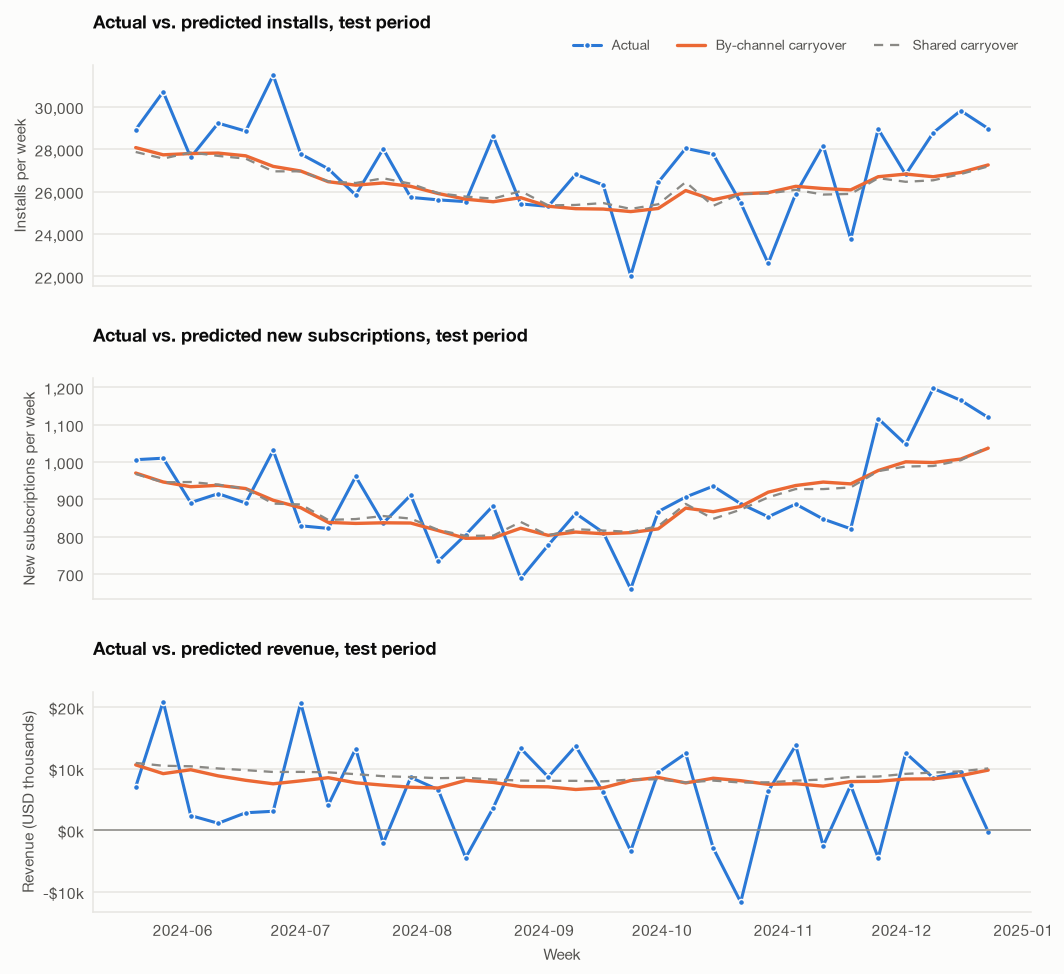

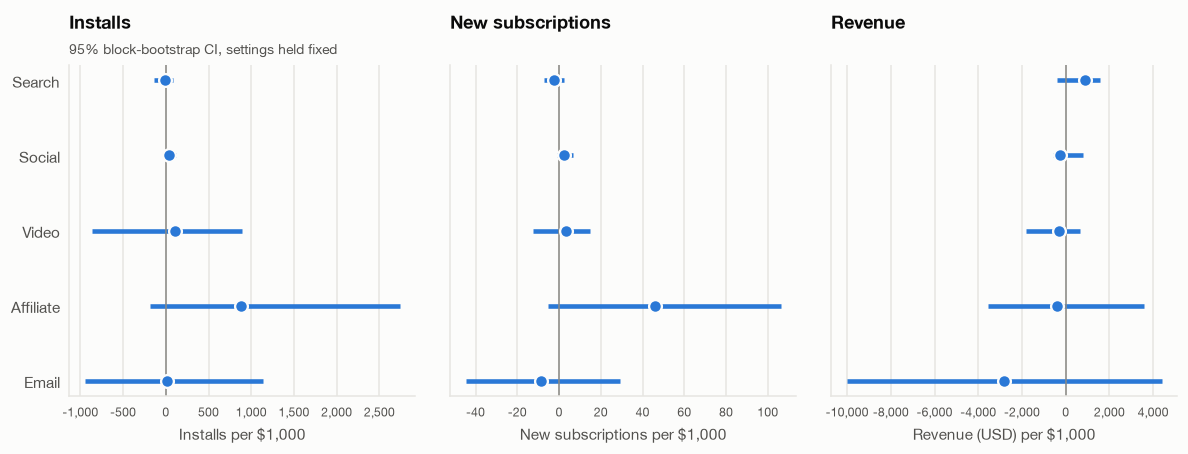

In [57]:
plot_test_fit(
    {name: preds['Ridge MMM, by channel'] for name, preds in channel_preds.items()},
    'By-channel carryover',
    {name: preds['Ridge MMM'] for name, preds in channel_preds.items()},
    'Shared carryover',
)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True, gridspec_kw={'wspace': 0.1})
ypos = np.arange(len(channel_names))
for ax, name, xlabel in zip(
    axes, outcome_fits, [r'Installs per \$1,000', r'New subscriptions per \$1,000', r'Revenue (USD) per \$1,000']
):
    r = channel_effect_table.loc[name].loc[channel_names[::-1]]
    forest(ax, r['per_1000_usd'], r['ci_95_low'], r['ci_95_high'], ypos)
    ax.xaxis.set_major_formatter(lambda v, _: f'{v:,.0f}')
    ax.tick_params(axis='x', labelsize=8)
    ax.set_xlabel(xlabel)
    ax.grid(axis='y', visible=False)
    ax.set_title(name.replace(' (USD)', ''))
axes[0].set_yticks(ypos, [ch.capitalize() for ch in channel_names[::-1]])
subtitle(axes[0], '95% block-bootstrap CI, settings held fixed')
plt.show()

**Result:** **Channel-specific carryover lowers test error slightly on all three outcomes, but the gain is not significant and the budget conclusion does not change.**
- **Selected carryovers differ by channel:** on installs and new subscriptions, search and social select 0.00, while video selects 0.90 and 0.70, and affiliate 0.60 on both. Revenue selects 0.70 for search to 0.94 for affiliate and email.
- **The values are not stable across outcomes:** search is 0.00 on installs and new subscriptions but 0.70 on revenue, so these should not be read as measured decay rates.
- **Cross-validated MAE improves, as expected on the weeks used for selection:** 1,981.3 to 1,815.2 on installs, 83.1 to 80.7 on new subscriptions, and \$6,532.9 to \$6,439.3 on revenue.
- **The test-period gain over a shared carryover is not significant:** -38.6 [-89.0, +35.7] on installs (p = 0.344), -0.6 [-3.3, +3.2] on new subscriptions (p = 0.746), and -\$134.1 [-\$464.8, +\$122.1] on revenue (p = 0.289).
- **It still does not significantly beat trend plus seasonality:** the gap is -54.3 [-126.7, +24.5] on installs (p = 0.181), +1.1 [-3.9, +7.0] on new subscriptions (p = 0.756), and +\$72.4 [-\$181.9, +\$262.8] on revenue (p = 0.713). Test $R^2$ is 0.230, 0.530 and -0.131.
- **The affiliate lead weakens:** +885.45 [-187.35, +2,737.71] installs (p = 0.070) and +46.14 [-5.33, +106.18] new subscriptions (p = 0.076) per \$1,000, so its intervals now include zero.
- **No channel interval excludes zero on any outcome, and every channel keeps its direction from 4.3:** search is +\$866.11 [-\$389.06, +\$1,564.55] per \$1,000 of spend on revenue, the unit this table uses for every outcome (p = 0.156).

**Limitation:** this adds four more settings to a model with 124 training weeks, and the selection can stop at a local best. The shared carryover therefore stays as the baseline.

### 4.5 Measurement plan: experiment-calibrated MMM

**Purpose:** test the parts of a stronger measurement plan that this data can test: whether a saturation curve helps, and how long an experiment would need to run.

Standard practice treats MMM as one part of a measurement system, with experiments supplying the causal evidence that weekly time series cannot:

1. **Measure a clearer outcome.** Model the funnel from spend to new subscriptions, then convert to value using subscriber lifetime value.
2. **Run incrementality experiments.** Use geo holdouts for paid channels, partner-level holdouts for affiliate and user-level holdouts for email, and turn each result into a measured cost per incremental subscription.
3. **Fit a Bayesian MMM calibrated to those results.** Give each channel its own adstock and saturation curve, and use the experiments as priors. Google Meridian and PyMC-Marketing work this way, and Meta's Robyn offers a Ridge-based alternative that also calibrates to experiments.
4. **Add the missing drivers.** Include price, offers, product releases and organic demand, none of which are in this dataset.
5. **Reallocate and repeat.** Move budget using the response curves, then refresh the model and re-test on a set schedule.

This dataset has no regional data or past experiments, so steps 2 and 3 cannot be run here, and a Bayesian fit without experiment priors would rest on invented assumptions. Section 4.2 shows that new subscriptions have clearer trend and seasonality than revenue, not that channels can be measured on them.

The log curve is compared with trend plus seasonality because a saturation curve is only useful if it improves on a model without channels.

Test length comes from three inputs: the significance level (two-sided 5%, the false-positive rate), the power (80%, the chance of detecting a true effect) and the detectable effect (the smallest weekly change the test must find). Spend on one channel is cut by half in alternating one-week blocks, which fit every total here and rely on the no-carryover assumption below, with $n$ weeks at each spend level. Longer blocks round $N$ up to a multiple of twice the block length. Total weeks are $N = 2n$, where $n$ is the smallest value that gives a two-sample t-test 80% power:

$$
P\Big(|T_{2n-2}(\delta)| > t_{0.975,\,2n-2}\Big) \ge 0.80,
\qquad
\delta = \frac{\Delta}{\sigma}\sqrt{\frac{n}{2}}
$$

where $T_{2n-2}(\delta)$ is a noncentral t variable, $\sigma$ is the weekly SD left after trend and seasonality, and $\Delta$ is the detectable effect. For long tests this approaches $N \approx 4\big((z_{0.975}+z_{0.80})\,\sigma/\Delta\big)^2$. The t-test is used because several tests here are short. It assumes independent weekly residuals, shown by their lag-1 autocorrelation, and no carryover between blocks. For installs and new subscriptions, $\Delta$ is the spend cut divided by a cost per incremental install or new subscription, at the blended cost and at double it. For revenue, $\Delta$ is the spend cut at a \$1 return.

In [58]:
# Test a saturation curve, then size the experiments that would measure channels directly
saturation_rows = {}
for name, (y, _, _, _) in outcome_fits.items():
    c_log, log_fit = select_carryover(y, np.log)
    X_log = np.log(adstock(c_log)).join(controls)
    preds = outcome_preds[name] | {'Ridge MMM + log saturation': log_fit.predict(X_log[SPLIT:])}
    saturation_rows[name] = score_models(y, preds, 'Trend + seasonality').loc['Ridge MMM + log saturation']
saturation_table = pd.DataFrame(saturation_rows).T.rename_axis('outcome')
display(
    mark(
        saturation_table[['test_mae', 'gap_to_reference', 'gap_ci_low', 'gap_ci_high', 'p_value']].style.format(
            score_format
        ),
        [(None, ['gap_to_reference', 'p_value'])],
        title='Does a log saturation curve help? Ridge MMM + log saturation compared with trend + seasonality, by outcome',
    )
)

,test_mae,gap_to_reference,gap_ci_low,gap_ci_high,p_value
outcome,,,,,
Installs,"1,549.2",+16.0,-95.3,+110.6,0.870
New subscriptions,71.6,+2.2,-3.8,+8.5,0.481
Revenue (USD),"6,389.7",+218.0,-38.6,+426.9,0.093


In [59]:
residuals = {
    name: sm.OLS(y, sm.add_constant(controls)).fit().resid
    for name, y in {'installs': installs, 'subs': new_subs, 'revenue': revenue}.items()
}
resid_sd = {name: r.std() for name, r in residuals.items()}
blended_cac = weekly_spend.sum() / new_subs.sum()
blended_cpi = weekly_spend.sum() / installs.sum()
spend_cut = mmm[spend_cols].mean().to_numpy() * 0.5


def weeks_needed(effect, sd):
    """Total test weeks, equal at normal and reduced spend, for 80% power in a two-sided 5% two-sample t-test."""
    per_arm = [TTestIndPower().solve_power(effect_size=e / sd, alpha=0.05, power=0.8) for e in effect]
    return 2 * np.ceil(per_arm).astype(int)


test_design = pd.DataFrame(
    {
        'weekly_spend_cut': spend_cut,
        'weeks_installs_at_blended_cost': weeks_needed(spend_cut / blended_cpi, resid_sd['installs']),
        'weeks_installs_at_double_cost': weeks_needed(spend_cut / (2 * blended_cpi), resid_sd['installs']),
        'weeks_subs_at_blended_cost': weeks_needed(spend_cut / blended_cac, resid_sd['subs']),
        'weeks_subs_at_double_cost': weeks_needed(spend_cut / (2 * blended_cac), resid_sd['subs']),
        'weeks_revenue_at_1usd_return': weeks_needed(spend_cut * 1.0, resid_sd['revenue']),
    },
    index=pd.Index(channel_names, name='channel'),
)
display(
    mark(
        pd.Series(
            {
                'Unexplained weekly SD, installs': f"{resid_sd['installs']:,.1f}",
                'Unexplained weekly SD, new subscriptions': f"{resid_sd['subs']:,.1f}",
                'Unexplained weekly SD, revenue': f"${resid_sd['revenue']:,.0f}",
                'Lag-1 autocorrelation of residuals, installs': f"{residuals['installs'].autocorr():.2f}",
                'Lag-1 autocorrelation of residuals, new subscriptions': f"{residuals['subs'].autocorr():.2f}",
                'Lag-1 autocorrelation of residuals, revenue': f"{residuals['revenue'].autocorr():.2f}",
                'Blended spend per install': f'${blended_cpi:.2f}',
                'Selected carryover, installs': f'{inst_carryover:.2f}',
                'Blended spend per new subscription': f'${blended_cac:.2f}',
                'Selected carryover, new subscriptions': f'{sub_carryover:.2f}',
                'Spend reduction tested': '50%',
                'Statistical power': '80%',
            },
            name='value',
        )
        .to_frame()
        .style,
        [(None, 'value')],
        title='Inputs to the experiment-size estimate',
    )
)
display(
    mark(
        test_design.style.format(
            {
                'weekly_spend_cut': '${:,.0f}',
                'weeks_installs_at_blended_cost': '{:,}',
                'weeks_installs_at_double_cost': '{:,}',
                'weeks_subs_at_blended_cost': '{:,}',
                'weeks_subs_at_double_cost': '{:,}',
                'weeks_revenue_at_1usd_return': '{:,}',
            }
        ),
        [(None, None)],
        title='Test length needed to detect a channel effect, by outcome (total weeks across both arms)',
    )
)

,value
"Unexplained weekly SD, installs","1,904.7"
"Unexplained weekly SD, new subscriptions",87.7
"Unexplained weekly SD, revenue","$8,097"
"Lag-1 autocorrelation of residuals, installs",0.00
"Lag-1 autocorrelation of residuals, new subscriptions",0.01
"Lag-1 autocorrelation of residuals, revenue",-0.03
Blended spend per install,$0.71
"Selected carryover, installs",0.00
Blended spend per new subscription,$20.33
"Selected carryover, new subscriptions",0.00


,weekly_spend_cut,weeks_installs_at_blended_cost,weeks_installs_at_double_cost,weeks_subs_at_blended_cost,weeks_subs_at_double_cost,weeks_revenue_at_1usd_return
channel,,,,,,
search,"$3,111",10,28,14,44,216
social,"$2,691",12,36,16,58,288
video,"$2,010",18,60,28,102,512
affiliate,$809,92,358,156,612,"3,150"
email,$491,244,966,416,"1,658","8,546"


**Result:** **All three outcomes say the same thing about measurement: the MMM cannot isolate channel effects, so experiments should decide, with new subscriptions as the main outcome.**
- **A saturation curve does not help:** a log curve changes MAE by +16.0 installs (p = 0.870), +2.2 new subscriptions (p = 0.481) and +\$218.0 of revenue (p = 0.093) vs. trend plus seasonality.
- **Installs give an earlier read:** search needs 10 to 28 weeks and social 12 to 36, using the blended \$0.71 per install and an unexplained SD of 1,904.7. An install is not a subscription, so this supports the decision but should not make it.
- **Testing on new subscriptions is feasible for the largest channels:** with an unexplained SD of 87.7 and a selected carryover of 0.00, cutting search by \$3,111 a week needs 14 weeks and cutting social by \$2,691 needs 16, if incremental cost matches the blended \$20.33. At double that cost, they need 44 and 58. Video needs 28 to 102.
- **Testing on revenue is impractical:** a test would need 216 weeks for search and 288 for social, because the unexplained weekly SD is \$8,097.
- **Affiliate and email need a different design:** 92 and 244 weeks on installs, or 156 and 416 on new subscriptions, are too long at this level, so these need partner-level and user-level holdouts.

**Limitation:** the blended costs credit every install and new subscription to marketing, so true incremental cost is probably higher and the shorter test lengths are a best case. The lengths also assume independent weeks (lag-1 residual autocorrelation 0.00 to 0.01 on these outcomes) and no carryover between blocks. No carryover is supported only on new subscriptions: revenue selects 0.94 and installs reach 0.34 under the steady-state start (4.3), so the revenue and install lengths are best cases. Regional tests may need fewer weeks, but this data cannot size them.

### Section summary
**Recommendation:** **Do not reallocate between channels yet, and run experiments on search, then social, before moving any money.**

- **Budget:** no reallocation is supported yet, including away from email. MMM results are correlational (directional), not causal. The launch budget level stays open until subscriber lifetime value is known, because it is not in the data. The overall level of \$0.44 of recorded revenue per \$1 of spend needs reconciling with that value (4.1).
- **Model:** the Ridge MMM significantly beats the train average on installs (p = 0.001), but not on new subscriptions (p = 0.138) or revenue (p = 0.384). Channels add no significant accuracy beyond trend and seasonality on any outcome, so the model should not set budgets (4.2).
- **Directional view:** affiliate leads on installs and new subscriptions (p = 0.160 after adjustment). On revenue, search ranks first at +\$0.64 [-\$0.58, +\$1.93] and email last at -\$4.80 [-\$15.14, +\$5.44]. Lower joint p-values on installs and new subscriptions do not survive a placebo test (`placebo_p` of at least 0.154), and channels are not jointly significant on revenue (p = 0.153 to 0.275) (4.3).
- **Model refinements:** channel-specific carryover lowers test MAE on installs, new subscriptions and revenue, but not significantly (p = 0.344, 0.746 and 0.289), so the shared carryover stays as the baseline (4.4). A log saturation curve does not beat trend plus seasonality (4.5).
- **Next step:** run the spend tests on search, then social, with installs as the earlier read (10 to 28 and 12 to 36 weeks) and new subscriptions as the deciding outcome (14 to 44 and 16 to 58 weeks) (4.5). In parallel, run partner-level holdouts for affiliate and user-level holdouts for email. Move budget toward a channel only if its cost per incremental subscription is below subscriber value.
- **Volatility caveat:** weekly revenue has an SD of \$8,362 around a mean of \$8,022, with 28 negative weeks, so single-week results should not drive budget decisions (4.1).

**Limitations:** the baseline shares one carryover across channels, and the data has no pricing, offer or competitor drivers. Subscriber lifetime value is not available, so the break-even cost per subscription cannot be set here.

## 5. Launch Plan, Risks and Next Steps

This section joins the four analyses into one plan. Figures use different bases and must not be added: expected revenue is per subscriber per month, offer effects are per existing user per month, and marketing figures are per week or per dollar of spend. The table below collects the figures that connect the analyses.

In [60]:
# Evidence behind the launch plan, computed from the tables above. Units differ by row and must not be added.
launch_evidence = pd.Series(
    {
        'Expected revenue per subscriber, recommended line-up (USD/month, simulated)': (
            f"${launch_ci.loc[f'{RECOMMENDED_LINEUP}|Total', 'estimate']:.2f}"
        ),
        'Offer effect on revenue (USD/user/month)': f"${t2_ci.loc['revenue: IPW ATE', 'estimate']:.3f}",
        'Marketing spend per new subscription (USD, recorded)': f'${blended_cac:.2f}',
    },
    name='value',
).to_frame()
display(mark(launch_evidence.style, [(None, None)], title='Launch plan evidence linking price, offer and marketing'))

,value
"Expected revenue per subscriber, recommended line-up (USD/month, simulated)",$11.49
Offer effect on revenue (USD/user/month),$0.238
"Marketing spend per new subscription (USD, recorded)",$20.33


### Bundle recommendation

**Launch Mid, Premium Lite and Premium, and lead with Premium Lite.**

| Tier | Price | Storage | Support | Ads | Seats | Offline download | Role |
|---|---|---|---|---|---|---|---|
| Mid | \$8 | 200 GB | Standard | None | 4 | Yes | Entry tier |
| **Premium Lite** | **\$12** | 1000 GB | Priority | None | 6 | No | Lead tier |
| Premium | \$15 | 1000 GB | Priority | None | 6 | Yes | Top tier, pending the live test |

- **Mid is the best of the four candidates** at 60.7% share of preference vs. 31.5% for Premium (1.5).
- **The three-tier line-up beats the four candidates on revenue:** it earns \$11.49 of expected revenue per subscriber per month vs. \$10.45, +\$1.03 [\$0.88, \$1.18]. Read the gain as about \$0.56 to \$1.03, depending on the model and on how close Premium is to Premium Lite (3.6).
- **Premium stays as a hypothesis for the live test:** keeping it adds at most +\$0.43 [\$0.38, \$0.48] over Mid and Premium Lite alone, and \$0.00 if the two are close substitutes. PowerUsers choose it most, at 19.4% vs. 1.9% for ValueSeekers and 5.2% for Families (3.6).
- **Budget goes** because it gives up \$7.89 of features to save \$3 (1.5).
- **ValuePlus goes for simplicity, a judgment call:** revenue slightly favors keeping it, and two \$12 tiers are harder to explain (3.4, 3.6). Dropping ValuePlus does not remove overlap: Premium Lite and Premium are almost as close (Gower 0.217 vs. 0.206).

### Pricing recommendation

**Hold Mid at \$8, launch Premium Lite at \$12, and test both Mid at \$9 and Premium below \$15.**

Willingness to pay (WTP) uses the coefficient ratio, $-\beta_{\text{feature}}/\beta_{\text{price}}$, and is directional because it comes from stated choices.

- **Mid at \$8:** this is a judgment for entry-tier reach. In the launch line-up, Mid's share falls from 21.1% to 10.2% at \$9. Simulated revenue rises to \$12.07 at \$9 only because nobody can leave the market in this model, so the model supports neither price (3.6).
- **Premium Lite at \$12:** the \$4 step up from Mid adds \$3.92 of storage, \$1.44 of Priority support and \$0.88 of seats, and gives up \$0.85 of offline download, for \$5.38 of value (3.6). The price is a test starting point, not an optimum, because the revenue screen cannot identify the best price without a "buy nothing" option (3.4).
- **Premium at \$15:** the \$3 step from Premium Lite buys only offline download, worth \$0.85 on average and \$1.65 to PowerUsers, the highest segment. Every segment falls short of the step, by \$1.35 to \$2.62 (1.4, 3.6).

### Offer recommendation

**Refine the offer's targeting, and do not scale it until a holdout and a cost check are done.**

- **Effect:** if the six covariates explain targeting, the offer adds an estimated +2.02 percentage points [1.46, 2.64] to the upgrade rate and +\$0.238 [\$0.153, \$0.321] of revenue per user per month. It was not randomized. The naive gap of +3.68 percentage points overstates it because the offer leaned toward longer-tenured users (2.5).
- **Diagnostics:** overlap is adequate, and balance improved after IPW, with tenure's SMD falling from 0.282 to below 0.01 (2.3, 2.4). The estimate still assumes no unmeasured confounding, and omitting tenure alone would move the upgrade effect to +3.40 percentage points (2.5).
- **Why not scale yet:** offer cost is not in the data, and the effect is an average across all users, not the users a campaign would target. Send it only where cost per user is below \$0.238 times the expected months of extra revenue.
- **Link to the launch:** the data does not define the offer or show which tier upgraders chose, so these results are not specific to Premium Lite. Run the offer holdout after the line-up test, so it measures the tiers that actually launch.

### Positioning and messaging

**Position the line on capacity, with Premium Lite as the higher-capacity choice over Mid and no ads as a message for the whole line.**

- **Substitutes:** ValuePlus and Premium are the closest pair among the four candidates (Gower 0.206, Euclidean 2.044) (3.1).
- **Whitespace:** Premium Lite sits between Mid and Premium on price and nearest Premium on features, with full capacity at a mid price (3.4).
- **Offline trade:** Mid includes offline download and Premium Lite does not, so messages must not present it as a plain upgrade.
- **Messages by audience:**
  - **Premium Lite:** 1000 GB, Priority support and 6 seats, the features that separate it from Mid (3.6).
  - **Families:** no ads and seats, worth \$3.29 and \$0.74 per seat (1.7).
  - **PowerUsers:** storage and Priority support, worth \$5.65 and \$2.35 (1.7).
  - **ValueSeekers:** Premium Lite's value first, with Mid at \$8 as their second choice, at 62.4% vs. 35.7% in the launch line-up (3.6).

### Budget recommendation

**Do not reallocate between channels yet, run experiments before moving money, and leave the launch budget level open until subscriber lifetime value is known.**

MMM results are correlational (directional), not causal.

- **The model cannot rank channels:** channels add no significant forecast accuracy beyond trend and seasonality on installs (p = 0.510), new subscriptions (p = 0.578) or revenue (p = 0.135) (4.2). No revenue interval excludes zero (4.3).
- **Volatility caveat:** weekly revenue has an SD of \$8,362 around a mean of \$8,022, with 28 negative weeks, so single-week results should not drive budget decisions (4.1).
- **Unit economics to check:** recorded spend is \$20.33 per new subscription. It should be judged against measured subscriber lifetime value, not the simulated \$11.49, which has no retention or margin.

### Assumptions and limitations

- **Stated preferences:** conjoint shares reflect survey choices, not purchases, and CIs capture sampling error only.
- **No "buy nothing" option:** shares are relative, so the model cannot show total demand, or customers lost by dropping Budget and ValuePlus.
- **Pooled logit:** Section 1 rejects equal preferences across segments, and the headline figures still use the pooled model. Segment models give smaller gains and the same order (3.6).
- **Proportional substitution:** the logit model likely understates how much Premium Lite takes from Premium, so +\$0.43 for keeping Premium is an upper bound (3.6).
- **No cost data:** every comparison is on revenue, not profit.
- **Unmeasured confounding:** the offer estimate holds only if the recorded covariates explain targeting.
- **Observational marketing data:** the MMM has no price, offer or competitor drivers, and no subscriber lifetime value.

### Next steps

Tests run in this order so that each one does not distort the next.

| Order | Test | Primary metric | Decision rule |
|---|---|---|---|
| 1 | Live line-up and price test before full launch. Arms: the recommended line-up, Mid + Premium Lite, and Mid + Premium. Price cells: Mid at \$9 and Premium below \$15. Include how the missing offline download is described | Revenue per visitor, including non-buyers | Launch the arm that earns most after serving costs. Keep Premium only if it beats Mid + Premium Lite |
| 2 | Randomized offer holdout at launch, with effects estimated by user segment | Incremental upgrades and revenue per user | Scale to segments where incremental revenue over the customer lifetime exceeds offer cost |
| 3 | Search, then social, spend tests once the line-up is stable | New subscriptions, with installs as the early read | Search needs 14 to 44 weeks and social 16 to 58 (4.5). Move budget only if cost per incremental subscription is below subscriber value |
| 4 | Partner-level holdouts for affiliate and user-level holdouts for email | New subscriptions | Same rule. Weekly tests would take too long at these spend levels (4.5) |
| 5 | Calibrate a Bayesian MMM with the experiment results | Forecast accuracy on held-out weeks | Use for budget setting once it beats trend and seasonality |

## Appendix: Survey Value Drivers (Factor Analysis)

A supplementary check of how survey items group. It does not change the recommendation.

### Approach

**Purpose:** find which items in `survey_value_drivers.csv` move together, because items that share a factor can carry one message.

Each respondent's answers are modeled as a few shared factors plus item-specific noise:

$$
x_i = \Lambda f_i + \varepsilon_i
$$

where $x_i$ holds the standardized answers to the 16 items, $\Lambda$ is the loadings table and $f_i$ holds the factor scores.

- **Number of factors:** the count from 1 to 6 with the highest 5-fold cross-validated log-likelihood, because it rewards fit on respondents the model has not seen. The code stops if the count is not 2 or 3, the range that gives a usable set of messages.
- **Rotation:** varimax, because the groups cannot be read without it.
- **Uncertainty:** 95% CIs from 500 respondent bootstrap resamples, with each resample's factors matched to the full-sample factors.

| Term | Meaning | Why it matters here |
|---|---|---|
| Factor | Unobserved driver that makes several items move together | Each factor can carry one message |
| Loading | Weight of a factor in an item's standardized answer | The top loadings show which items define a factor |
| Rotation | Turns the factors without changing the model's fit, so each item loads strongly on as few as possible | Gives groups of items that can be read |
| Uniqueness | Share of an item's variance that the factors do not explain | A high value marks an item that fits the groups poorly |
| Factor analysis vs. PCA | Factor analysis separates shared variance from item noise; PCA summarizes all variance | The question is what items share, so item noise is left out |

In [61]:
survey = df_survey.set_index('respondent_id')
X_survey = StandardScaler().fit_transform(survey)

factor_counts = range(1, 7)
cv_ll = pd.Series(
    {k: cross_val_score(FactorAnalysis(n_components=k, random_state=0), X_survey, cv=5).mean() for k in factor_counts},
    name='cv_log_likelihood',
).rename_axis('factors')
n_factors = int(cv_ll.idxmax())
assert n_factors in (2, 3), 'expected 2 or 3 factors'
display(
    mark(
        cv_ll.to_frame().T.style.format('{:.3f}'),
        [(None, [n_factors - 1, n_factors, n_factors + 1])],
        title='Cross-validated log-likelihood by number of factors',
    )
)

factor_names = [f'Factor_{k}' for k in range(1, n_factors + 1)]


def rotated_loadings(X):
    """Varimax loadings, factors ordered by variance explained and signed so the largest loading is positive."""
    fa = FactorAnalysis(n_components=n_factors, rotation='varimax', random_state=42).fit(X)
    L = fa.components_.T
    L = L[:, np.argsort(-(L**2).sum(axis=0))]
    L = L * np.sign(L[np.abs(L).argmax(axis=0), range(n_factors)])
    return L, fa.noise_variance_


L_full, noise = rotated_loadings(X_survey)
loadings = pd.DataFrame(L_full, index=survey.columns, columns=factor_names)

# Bootstrap: match each resample's factors to the full-sample factors before comparing them
fa_rng = np.random.default_rng(7)
boot_loadings = []
for _ in range(500):
    L_b = rotated_loadings(X_survey[fa_rng.integers(0, len(X_survey), len(X_survey))])[0]
    similarity = L_full.T @ L_b
    full_idx, boot_idx = linear_sum_assignment(-np.abs(similarity))
    boot_loadings.append(L_b[:, boot_idx] * np.sign(similarity[full_idx, boot_idx]))
boot_loadings = np.array(boot_loadings)

top_items = {f: loadings[f].abs().nlargest(3).index for f in factor_names}
main_factor = loadings.abs().idxmax(axis=1)
loading_table = loadings.assign(uniqueness=noise)
loading_table = loading_table.loc[
    sorted(loading_table.index, key=lambda q: (main_factor[q], -abs(loadings.loc[q, main_factor[q]])))
]
display(
    mark(
        loading_table.style.format('{:+.3f}', subset=factor_names).format('{:.3f}', subset=['uniqueness']),
        [(top_items[f], f) for f in factor_names] + [(['Q13', 'Q14'], ['Factor_2', 'Factor_3'])],
        title='Rotated factor loadings (varimax)',
    )
)

second_loading = loadings.abs().apply(lambda r: r.nlargest(2).iloc[1], axis=1)
print('Items with a second loading of 0.3 or more:', loadings.index[second_loading >= 0.3].tolist())

top_table = pd.DataFrame(
    [
        {
            'factor': f,
            'item': q,
            'loading': loadings.loc[q, f],
            'ci_95_low': np.quantile(boot_loadings[:, loadings.index.get_loc(q), j], 0.025),
            'ci_95_high': np.quantile(boot_loadings[:, loadings.index.get_loc(q), j], 0.975),
        }
        for j, f in enumerate(factor_names)
        for q in top_items[f]
    ]
).set_index(['factor', 'item'])
display(mark(top_table.style.format('{:.3f}'), [(None, None)], title='Top 3 items by absolute loading, with 95% CIs'))

factor_variance = pd.DataFrame({'variance_share': (L_full**2).sum(axis=0) / len(L_full)}, index=factor_names)
variance_ci = (boot_loadings**2).sum(axis=1) / len(L_full)
factor_variance['ci_95_low'], factor_variance['ci_95_high'] = np.quantile(variance_ci, [0.025, 0.975], axis=0)
factor_variance.loc['Total'] = [
    factor_variance['variance_share'].sum(),
    *np.quantile(variance_ci.sum(axis=1), [0.025, 0.975]),
]
display(
    mark(
        factor_variance.style.format('{:.1%}'),
        [(None, None)],
        title='Share of total item variance explained by each factor',
    )
)

print(
    f"Item means: {survey.mean().min():.2f}–{survey.mean().max():.2f}  |  item SDs: {survey.std().min():.2f}–{survey.std().max():.2f}"
)

factors,1,2,3,4,5,6
cv_log_likelihood,-21.137,-20.605,-20.006,-20.006,-20.008,-20.010


,Factor_1,Factor_2,Factor_3,uniqueness
Q09,+0.736,+0.122,+0.026,0.445
Q10,+0.704,+0.050,+0.088,0.494
Q11,+0.681,+0.125,+0.127,0.503
Q12,+0.640,+0.179,+0.091,0.550
Q15,+0.590,+0.169,+0.231,0.570
Q16,+0.485,+0.290,+0.210,0.636
Q06,+0.128,+0.732,+0.007,0.448
Q05,+0.070,+0.714,+0.064,0.480
Q07,+0.145,+0.688,+0.123,0.489
Q08,+0.223,+0.625,+0.077,0.553


Items with a second loading of 0.3 or more: ['Q13', 'Q14']


,variance_share,ci_95_low,ci_95_high
Factor_1,16.7%,16.2%,17.3%
Factor_2,16.3%,15.6%,16.9%
Factor_3,15.1%,14.5%,15.7%
Total,48.0%,47.1%,49.0%


Item means: 4.00–4.00  |  item SDs: 2.00–2.00


**Result:** **The 16 items form three distinct groups of similar size, which supports three separate messages. The data cannot name the groups or rank them.**
- **Three factors fit best:** cross-validated log-likelihood improves from -20.605 with two factors to -20.006 with three and does not improve with four (-20.006). Together they explain 48.0% [47.1%, 49.0%] of the variance in the items.
- **Avoid Q13 and Q14 as message anchors.** Each sits between Factor_2 and Factor_3, with loadings of 0.461 and 0.438 for Q13 and 0.513 and 0.355 for Q14.
- **The survey cannot set the message order.** Every item has the same mean and SD (printed above), and a factor's variance share shows how much items move together, not how much customers value them. The order should come from Section 1.

**Factor_1, 16.7% [16.2%, 17.3%] of item variance.** Top 3 items: Q09 0.736 [0.718, 0.757], Q10 0.704 [0.685, 0.725], Q11 0.681 [0.660, 0.702]. Q12, Q15 and Q16 also load here, more weakly. Respondents who rate one of these items highly tend to rate the others highly, so they can share one message, built from Q09, Q10 and Q11.

**Factor_2, 16.3% [15.6%, 16.9%] of item variance.** Top 3 items: Q06 0.732 [0.711, 0.751], Q05 0.714 [0.693, 0.734], Q07 0.688 [0.667, 0.707]. Q08 also loads here. This is a second, separate claim, and its message should be built from these items, not mixed with Factor_1.

**Factor_3, 15.1% [14.5%, 15.7%] of item variance.** Top 3 items: Q01 0.738 [0.717, 0.759], Q03 0.707 [0.684, 0.726], Q02 0.693 [0.672, 0.715]. Q04 also loads here. This is a third claim, separate from the other two, so it needs its own message.

**Limitations:** the question wording is not in the project files, so the factors stay unnamed and the guidance above stops at which items belong together. Theme names and final copy need the questionnaire.